In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import requests
import xgboost as xgb

from sklearn.pipeline import Pipeline
from scipy.spatial.distance import pdist, squareform
from scipy.stats import loguniform, randint, uniform
from mpl_toolkits.mplot3d import Axes3D

from google.colab import drive

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

from xgboost import XGBClassifier


# <u>**Prediction of Tissue of Origin in cancer samples**</u>

## *Introduction:*
The analysed dataset is the result of a painstaking proteomics study lasting more than 10.000h of active mass spectrometer running time, performed on 949 cancer cell lines.

According to the authors of [the article in question](https://www.sciencedirect.com/science/article/pii/S1535610822002744?via%3Dihub#bib14)(1) the purpose of this analysys was to fill a gap in the availability of cancer proteomics data, as the proteome itself is the phenotype of a given cell type, unlike genomic and trascriptomic data being only correlated with phenotype. Logically speaking proteins would serve as the ultimate predictors of cancer phenotypes and so the closest predictors of cancer vulnerabilities.

However due to the high sensitivity of mass spectrometry, different instruments and acquisition times can significantly chage detection results and relative abundances. For this a standardised approach was needed.

In the course of the article, all the proteins with more than one peptide individuated across all experimental replicates were kept (6692 proteins in total) and combined with drug response and genomic vulnerability data to train a Deep Learning based model to predict cancer vulnerabilities from their proteome.

First it was found that proteomics data alone had comparable predictive power to trascriptomic data for cancer vulnerabilities. Interestingly, given the high correlation of certain co-regulated groups of proteins, the Deep Learning model preserved high predictive power even when downsampling the training data to only 1500 correlated proteins, suggesting that perhaps proteomics data may be more efficient (in terms of variables per data point) in predicting cancer vulnerabilities such as drug-responses, drug targets and genomic vulnerabilities.

In my opinion all of these conclusions are very interesting, and being a data nerd myself I could have not hoped for a better dataset to fiddle with, however perhaps the biggest contribution of the article is the developement of a streamlined and fast protocol to actually perform all the mass-spectrometer runs. In fact every single cancer cell line was analysed in 6 different MS systems, on 3 different technical replicates (to remove batch-effect, noise and maximise detected proteins), this is a testimony to the fact that 10.000h after all are not that many... Demonstrating that proteomics data has incredible ptential for cancer treatment is itself tremendous, but simplifying its production is crucial if its predictive power is to be actually used in real-world diagnostic scenarios. With this protocol, perhaps a continuous stream of sample preparation, analysis, and repetition could be set up to analyse real cancer biopsies from patients that could truly benefit from predicting their vulnerabilities.

As already meantioned, the dataset used in the articel (1) featured 6692 proteins and leveraged Deep Learning and highly correlated proteins to make use of such a large number of variables. Not having access to an infinitely powerful computer myself, I made the choice to drop as many variables as possible, one of the steps that allowed me to drop the most proteins was removing highly correlated proteins (more information on this process later). In hindsight this could have hindered model performances but I halved the number of variables and made training significantly quicker (also I did not use a Deep Learning model, which is particularly lenghty to train and fine tune) so this decision, albeit not ideal, was taken after careful consideration and practical constraints.


<br>

---

#### ***Purpose of my project:*** ####
Attempt the developement of a Machine Learning model capable of determining tissue of origin of a particular cancer cell, using its proteomics data.

<br>

---
#### ***Why?*** ####
This could prove beneficial for individuating cell, tissue or tumour specific proteomic markers capable of differentiating between various cancer cell types (feature importance), but could also be used for tracking the origin of metastasis and so for diagnostic/prognostic purposes.

---

<br>

## ***Index:***
1.  *Dataset selection and description*
2.  *Exploratory Data Analysis (EDA)*
3.  *Preprocessing before the split*
4.  *Dataset split*
5.  *Preprocessing after the split — the Pipeline*
6.  *Model selection and comparison*
7.  *Hyperparameter tuning*
8.  *Final evaluation and overfitting/underfitting check*
9.  *Feature importance analysis*
10. *Conclusions*

---

<br>

## <u>**Sources:**</u>
1. Emanuel Gonçalves, Rebecca C. Poulos, Zhaoxiang Cai, Syd Barthorpe, Srikanth S. Manda, Natasha Lucas, Alexandra Beck, Daniel Bucio-Noble, Michael Dausmann, Caitlin Hall, Michael Hecker, Jennifer Koh, Howard Lightfoot, Sadia Mahboob, Iman Mali, James Morris, Laura Richardson, Akila J. Seneviratne, Rebecca Shepherd, Erin Sykes, Frances Thomas, Sara Valentini, Steven G. Williams, Yangxiu Wu, Dylan Xavier, Karen L. MacKenzie, Peter G. Hains, Brett Tully, Phillip J. Robinson, Qing Zhong, Mathew J. Garnett, Roger R. Reddel,
Pan-cancer proteomic map of 949 human cell lines,
Cancer Cell,
Volume 40, Issue 8,
2022,
Pages 835-849.e8,
ISSN 1535-6108,
https://doi.org/10.1016/j.ccell.2022.06.010.

# 1. Dataset Selection and Description

### *In brief:*
In the case of the data I am using, the quantification method for the proteomics study was a Label-Free Quantification method with no spiking for a quantitative protein quantification.

In short the values we see attributed to each protein in the dataset, are of themselves meaningless, a unitless measure, but it indicates the abundance of a certain protein relative to other biological samples (cell types) in the dataset.

From my understanding of Label-Free Quantification without spiking:
- If in sample 1, protein A has a value of 7
- And in sample 2 it has a value of 4
- Sample 1 has 8 times (2^3) times more of that protein than sample 2



---


- This yielded a dataset of `8498 identified proteins acorss 949 cancer cell lines`.

- An additional version of this dataset `filtered for proteins which were identidied by more than 1 peptide across runs` (so higher reliability) was released and it contains `6692 proteins` (949 cell lines) and **`this is the dataset I selected`.**






#2. Preprocessing before The Split


### Mount the drive and define the paths to the data

*   List item
*   List item



In [ ]:
# @title Mount the drive
# Mount Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# @title Data Paths

data_path = "/content/drive/MyDrive/data/ProCan-DepMapSanger_protein_matrix_6692_averaged.txt"
map_path = "/content/drive/MyDrive/data/ProCan-DepMapSanger_mapping_file_averaged.txt"

### Import the data

In [ ]:
#read data
proteomics_averaged_df = pd.read_table(data_path)
#read the mapping file specific for the averaged dataset
decoding_matrix_for_average = pd.read_table(map_path)

#output
print("Decoding Matrix for averaged results")
display(decoding_matrix_for_average.head())
print("\n\nAveraged Results:")
display(proteomics_averaged_df.head())

Decoding Matrix for averaged results


,Cell_line,SIDM,Project_Identifier,Tissue_type,Cancer_type,Cancer_subtype
0,BC-1,SIDM00896,SIDM00896;BC-1,Haematopoietic and Lymphoid,B-Cell Non-Hodgkin's Lymphoma,Primary effusion lymphoma
1,L-363,SIDM00312,SIDM00312;L-363,Haematopoietic and Lymphoid,Plasma Cell Myeloma,NaN
2,EoL-1-cell,SIDM00277,SIDM00277;EoL-1-cell,Haematopoietic and Lymphoid,Acute Myeloid Leukemia,Chronic Eosinophilic Leukemia
3,NCI-H727,SIDM01119,SIDM01119;NCI-H727,Lung,Carcinoid Tumour,Lung Carcinoid Tumor
4,MV-4-11,SIDM00657,SIDM00657;MV-4-11,Haematopoietic and Lymphoid,Acute Myeloid Leukemia,Acute Monocytic leukemia




Averaged Results:


,Project_Identifier,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,Q9Y4H2;IRS2_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q8WUQ7;CATIN_HUMAN,A6NIH7;U119B_HUMAN,Q9BTD8;RBM42_HUMAN,...,P33151;CADH5_HUMAN,Q5EBL4;RIPL1_HUMAN,P49715;CEBPA_HUMAN,Q5TA45;INT11_HUMAN,O14924;RGS12_HUMAN,Q7Z3B1;NEGR1_HUMAN,O60669;MOT2_HUMAN,Q13571;LAPM5_HUMAN,Q96JM2;ZN462_HUMAN,P35558;PCKGC_HUMAN
0,SIDM00018;K052,7.109545,3.414941,NaN,7.866614,3.895467,4.196655,NaN,NaN,3.190877,...,NaN,NaN,3.90064,2.639977,NaN,NaN,NaN,NaN,NaN,NaN
1,SIDM00023;TE-12,6.828022,4.143455,2.237808,7.628785,3.198109,4.609018,NaN,2.47059,3.695348,...,NaN,NaN,NaN,3.196077,NaN,NaN,NaN,NaN,NaN,NaN
2,SIDM00040;TMK-1,7.014256,4.199872,2.440552,8.124585,NaN,4.768811,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SIDM00041;STS-0421,5.285911,3.357894,NaN,7.972680,NaN,4.520923,NaN,NaN,2.730884,...,NaN,NaN,NaN,2.790234,NaN,NaN,NaN,NaN,NaN,NaN
4,SIDM00042;PL4,5.707857,NaN,NaN,6.225738,NaN,4.495795,NaN,NaN,2.879809,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Merge the proteomics dataset with its corresponding decoding file

This was done because the proteomics dataset I used does not directly contain information regarding the Tissue Type of each entry, nor the cancer subtype.

To remedy this I merged the proteomics data with its "decoding file" provided by the article, at the "Project_Identifier" column which was shared between the two.

In [ ]:
#Merge the mapping file columns of cancer type,
#subtype and tissue type onto the dataframe
#containing the proteomics data
proteomics_averaged_df = pd.merge(
    proteomics_averaged_df,
    decoding_matrix_for_average[['Project_Identifier', 'Tissue_type', 'Cancer_type', "Cancer_subtype"]],
    left_on='Project_Identifier', #where the right df is merghed on
    right_on='Project_Identifier',  #where the left df is merged onto the right one
    how='left'  #meaning merges onto the left, so preserves all existing entries (rows in this case)
                # of the left df (called keys), regardless of whether they have a corresponding entry on the right df
)
print("Averaged proteomics results after merging with interesting decoding columns:")
display(proteomics_averaged_df.head())

Averaged proteomics results after merging with interesting decoding columns:


,Project_Identifier,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,Q9Y4H2;IRS2_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q8WUQ7;CATIN_HUMAN,A6NIH7;U119B_HUMAN,Q9BTD8;RBM42_HUMAN,...,Q5TA45;INT11_HUMAN,O14924;RGS12_HUMAN,Q7Z3B1;NEGR1_HUMAN,O60669;MOT2_HUMAN,Q13571;LAPM5_HUMAN,Q96JM2;ZN462_HUMAN,P35558;PCKGC_HUMAN,Tissue_type,Cancer_type,Cancer_subtype
0,SIDM00018;K052,7.109545,3.414941,NaN,7.866614,3.895467,4.196655,NaN,NaN,3.190877,...,2.639977,NaN,NaN,NaN,NaN,NaN,NaN,Haematopoietic and Lymphoid,Acute Myeloid Leukemia,Adult Acute Myeloid Leukemia
1,SIDM00023;TE-12,6.828022,4.143455,2.237808,7.628785,3.198109,4.609018,NaN,2.47059,3.695348,...,3.196077,NaN,NaN,NaN,NaN,NaN,NaN,Esophagus,Esophageal Carcinoma,Esophageal Squamous Cell Carcinoma
2,SIDM00040;TMK-1,7.014256,4.199872,2.440552,8.124585,NaN,4.768811,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Stomach,Gastric Carcinoma,Gastric adenocarcinoma
3,SIDM00041;STS-0421,5.285911,3.357894,NaN,7.972680,NaN,4.520923,NaN,NaN,2.730884,...,2.790234,NaN,NaN,NaN,NaN,NaN,NaN,Stomach,Gastric Carcinoma,Gastric adenocarcinoma
4,SIDM00042;PL4,5.707857,NaN,NaN,6.225738,NaN,4.495795,NaN,NaN,2.879809,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Pancreas,Pancreatic Carcinoma,Pancreatic ductal adenocarcinoma


####`This added the Cancer_type, Cancer_subtype and Tissue_type columns`

###Split the Project_Identifier Column

In [ ]:
# see categorical columns
categorical_columns = proteomics_averaged_df.select_dtypes(include = "object").columns.tolist()
print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")

Categorical columns (4): ['Project_Identifier', 'Tissue_type', 'Cancer_type', 'Cancer_subtype']


In [ ]:
# Split 'Project_Identifier' into 'SIDM' and 'Cell_line'
proteomics_averaged_df[['SIDM', 'Cell_line']] = proteomics_averaged_df['Project_Identifier'].str.split(';', n=1, expand=True) #n=1 means that it splits only the first time ";" is encountered, this could prevent unnecessary splits

proteomics_averaged_df = proteomics_averaged_df.drop(columns=["Project_Identifier"])
display(proteomics_averaged_df.head())

,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,Q9Y4H2;IRS2_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q8WUQ7;CATIN_HUMAN,A6NIH7;U119B_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,...,Q7Z3B1;NEGR1_HUMAN,O60669;MOT2_HUMAN,Q13571;LAPM5_HUMAN,Q96JM2;ZN462_HUMAN,P35558;PCKGC_HUMAN,Tissue_type,Cancer_type,Cancer_subtype,SIDM,Cell_line
0,7.109545,3.414941,NaN,7.866614,3.895467,4.196655,NaN,NaN,3.190877,7.358065,...,NaN,NaN,NaN,NaN,NaN,Haematopoietic and Lymphoid,Acute Myeloid Leukemia,Adult Acute Myeloid Leukemia,SIDM00018,K052
1,6.828022,4.143455,2.237808,7.628785,3.198109,4.609018,NaN,2.47059,3.695348,5.707904,...,NaN,NaN,NaN,NaN,NaN,Esophagus,Esophageal Carcinoma,Esophageal Squamous Cell Carcinoma,SIDM00023,TE-12
2,7.014256,4.199872,2.440552,8.124585,NaN,4.768811,NaN,NaN,NaN,5.522833,...,NaN,NaN,NaN,NaN,NaN,Stomach,Gastric Carcinoma,Gastric adenocarcinoma,SIDM00040,TMK-1
3,5.285911,3.357894,NaN,7.972680,NaN,4.520923,NaN,NaN,2.730884,4.294287,...,NaN,NaN,NaN,NaN,NaN,Stomach,Gastric Carcinoma,Gastric adenocarcinoma,SIDM00041,STS-0421
4,5.707857,NaN,NaN,6.225738,NaN,4.495795,NaN,NaN,2.879809,NaN,...,NaN,NaN,NaN,NaN,NaN,Pancreas,Pancreatic Carcinoma,Pancreatic ductal adenocarcinoma,SIDM00042,PL4


Reorder some columns after manipulation

In [ ]:
# REORDER COLUMNS so that all the ones that describe the sample come before the proteins

# Define the new desired order for the descriptive columns
descriptive_cols_order = ['Cell_line', 'SIDM', 'Cancer_type', 'Cancer_subtype', 'Tissue_type']

# Get all columns that are not in the descriptive_cols_order
protein_cols = [col for col in proteomics_averaged_df.columns if col not in descriptive_cols_order]

# Combine them to form the final column order
final_column_order = descriptive_cols_order + protein_cols

# Reindex the DataFrame with the new column order
proteomics_averaged_df = proteomics_averaged_df[final_column_order]

print("Proteomics data Averaged:")
display(proteomics_averaged_df.head())
print("Number of proteins (columns):", len(protein_cols))
print("\n\n", "Descriptive variables:", descriptive_cols_order, "\n", "number:", len(descriptive_cols_order))

Proteomics data Averaged:


,Cell_line,SIDM,Cancer_type,Cancer_subtype,Tissue_type,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,Q9Y4H2;IRS2_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,...,P33151;CADH5_HUMAN,Q5EBL4;RIPL1_HUMAN,P49715;CEBPA_HUMAN,Q5TA45;INT11_HUMAN,O14924;RGS12_HUMAN,Q7Z3B1;NEGR1_HUMAN,O60669;MOT2_HUMAN,Q13571;LAPM5_HUMAN,Q96JM2;ZN462_HUMAN,P35558;PCKGC_HUMAN
0,K052,SIDM00018,Acute Myeloid Leukemia,Adult Acute Myeloid Leukemia,Haematopoietic and Lymphoid,7.109545,3.414941,NaN,7.866614,3.895467,...,NaN,NaN,3.90064,2.639977,NaN,NaN,NaN,NaN,NaN,NaN
1,TE-12,SIDM00023,Esophageal Carcinoma,Esophageal Squamous Cell Carcinoma,Esophagus,6.828022,4.143455,2.237808,7.628785,3.198109,...,NaN,NaN,NaN,3.196077,NaN,NaN,NaN,NaN,NaN,NaN
2,TMK-1,SIDM00040,Gastric Carcinoma,Gastric adenocarcinoma,Stomach,7.014256,4.199872,2.440552,8.124585,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,STS-0421,SIDM00041,Gastric Carcinoma,Gastric adenocarcinoma,Stomach,5.285911,3.357894,NaN,7.972680,NaN,...,NaN,NaN,NaN,2.790234,NaN,NaN,NaN,NaN,NaN,NaN
4,PL4,SIDM00042,Pancreatic Carcinoma,Pancreatic ductal adenocarcinoma,Pancreas,5.707857,NaN,NaN,6.225738,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Number of proteins (columns): 6692


 Descriptive variables: ['Cell_line', 'SIDM', 'Cancer_type', 'Cancer_subtype', 'Tissue_type'] 
 number: 5


## Missing Values: typical for proteomics

1. Calculate the missing values for every protein (column)
2. Drop the proteins (columns) which have more NaNs than a certain treshold


---


###Why remove them?
- Too many variables can result in model overfitting and increased training time.
- Presence of proteins exclusive to one or a few cancer cells types could be interpreted by the model as sole indicators of said class, limiting the ability to truly learn from all the variables.

In [ ]:
# Calculate NaN values for each protein column
nan_counts_per_protein = proteomics_averaged_df[protein_cols].isnull().sum()

# Create df for nan count and nan percentage using dictionaries
total_rows = len(proteomics_averaged_df)
nan_counts_per_protein = pd.DataFrame({"NaN_Count" : nan_counts_per_protein, "NaN_Percentage_%" : nan_counts_per_protein / total_rows *100})

display(nan_counts_per_protein)

,NaN_Count,NaN_Percentage_%
P37108;SRP14_HUMAN,0,0.000000
Q96JP5;ZFP91_HUMAN,309,32.560590
Q9Y4H2;IRS2_HUMAN,764,80.505796
P36578;RL4_HUMAN,0,0.000000
Q6SPF0;SAMD1_HUMAN,214,22.550053
...,...,...
Q7Z3B1;NEGR1_HUMAN,844,88.935722
O60669;MOT2_HUMAN,890,93.782929
Q13571;LAPM5_HUMAN,906,95.468915
Q96JM2;ZN462_HUMAN,831,87.565859


### Find the columns with more than 50% missing values and add them to a list

In [ ]:
#Define the protein columns as the numerical columns instead of the columns that are not the descriptive columns
protein_cols = proteomics_averaged_df.select_dtypes(include=['number']).columns.tolist()

proteins_to_drop = []
treshold_nan_perc = 50

proteins_to_drop = nan_counts_per_protein.loc[nan_counts_per_protein["NaN_Percentage_%"] > treshold_nan_perc].index

print("Number of proteins to drop:", len(proteins_to_drop))
print(f"Proteins in proteomics data now: {len(protein_cols)}")

Number of proteins to drop: 3303
Proteins in proteomics data now: 6692


### Drop the columns with more than 50% missing values

In [ ]:
#drop the columns which have more than 50% missing values
proteomics_data = proteomics_averaged_df.drop(columns=proteins_to_drop)

#define a list of the descriptive columns (previously defined but lets "change" the name of the variable for clarity)
descriptive_cols = proteomics_data.select_dtypes(include=["object"]).columns.tolist()
#list of the proteins in our proteomic data after we removed the ones that had too many NaN
proteins = proteomics_data.select_dtypes(include=['number']).columns.tolist()

#Peek the data
display(proteomics_data)
print(f"Shape: {proteomics_data.shape} \nCell_types: {len(proteomics_data)} \nProteins: {len(proteins)} \nCategorical variables ({len(descriptive_cols)})")



,Cell_line,SIDM,Cancer_type,Cancer_subtype,Tissue_type,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
0,K052,SIDM00018,Acute Myeloid Leukemia,Adult Acute Myeloid Leukemia,Haematopoietic and Lymphoid,7.109545,3.414941,7.866614,3.895467,4.196655,...,4.260154,6.070841,NaN,9.259751,NaN,1.671608,6.007174,3.815668,4.769969,7.084055
1,TE-12,SIDM00023,Esophageal Carcinoma,Esophageal Squamous Cell Carcinoma,Esophagus,6.828022,4.143455,7.628785,3.198109,4.609018,...,3.852484,6.135780,3.760480,9.084405,4.426812,3.039617,5.769395,4.297804,5.295486,8.294270
2,TMK-1,SIDM00040,Gastric Carcinoma,Gastric adenocarcinoma,Stomach,7.014256,4.199872,8.124585,NaN,4.768811,...,3.885525,NaN,4.428223,9.014724,NaN,NaN,NaN,3.856578,4.699897,NaN
3,STS-0421,SIDM00041,Gastric Carcinoma,Gastric adenocarcinoma,Stomach,5.285911,3.357894,7.972680,NaN,4.520923,...,4.072270,7.176259,4.989266,8.812034,NaN,2.077865,NaN,3.962057,4.302191,6.306365
4,PL4,SIDM00042,Pancreatic Carcinoma,Pancreatic ductal adenocarcinoma,Pancreas,5.707857,NaN,6.225738,NaN,4.495795,...,2.385021,NaN,NaN,7.810233,2.913824,3.885762,4.255781,NaN,6.024478,7.480701
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
944,CGTH-W-1,SIDM01248,Thyroid Gland Carcinoma,Thyroid gland squamous cell carcinoma,Thyroid,6.316308,4.869332,7.624330,3.926891,4.472120,...,3.801180,6.595114,NaN,9.250869,4.701823,2.163399,NaN,4.526977,5.869905,NaN
945,H9,SIDM01251,T-Cell Non-Hodgkin's Lymphoma,Cutaneous T-Cell Lymphoma,Haematopoietic and Lymphoid,6.230865,2.716858,7.235027,3.420646,4.717799,...,3.708513,NaN,NaN,9.030642,3.721460,-0.513798,NaN,3.235900,5.893577,NaN
946,GR-ST,SIDM01259,B-Lymphoblastic Leukemia,Childhood B acute lymphoblastic leukemia,Haematopoietic and Lymphoid,7.004074,NaN,7.581500,NaN,4.590818,...,3.567742,NaN,4.627169,9.584255,NaN,2.059710,5.266445,3.852509,5.413974,6.894095
947,YMB-1-E,SIDM01261,Breast Carcinoma,Invasive Ductal Carcinoma of No Special Type,Breast,6.765316,3.757772,7.241326,3.054766,4.740301,...,4.024586,NaN,NaN,7.787795,NaN,2.298027,NaN,5.249165,4.201864,6.093896


Shape: (949, 3394) 
Cell_types: 949 
Proteins: 3389 
Categorical variables (5)


## Variables with no variance across entries

I decided to check for proteins (variables) which possess low to no variance across the cancer cell lines.

These would have been removed as they provide no information on how to classify data (for e.g. housekeeping proteins maybe or proteins with relatively similar expressiona cross various cell types).

*I know that since protein levels are highly variable and complex, it is highly unlikely that two cell types posses the same levels of proteins but I still wanted to check...*

In [ ]:
no_var_proteins = []
var_data = []
for protein in proteins:
  p_var = proteomics_data[protein].var()
  if p_var == 0:
    no_var_proteins.append(protein)
  else:
    continue
print(f"No. of 0 variance proteins: {len(no_var_proteins)} \nThey are: {no_var_proteins}")

no_var_proteins = []
for protein in proteins:
  p_var = proteomics_data[protein].var()
  var_data.append({"Protein": protein, "Variance": p_var})


var_data = pd.DataFrame(var_data)
print(20*"-")
print("\nList of variance per protein:")
display(var_data.sort_values(by="Variance", ascending=True))

No. of 0 variance proteins: 0 
They are: []
--------------------

List of variance per protein:


,Protein,Variance
187,O75533;SF3B1_HUMAN,0.061249
2500,P62318;SMD3_HUMAN,0.086903
441,Q13435;SF3B2_HUMAN,0.089547
3198,Q9Y3B4;SF3B6_HUMAN,0.093314
258,O75643;U520_HUMAN,0.098293
...,...,...
2482,P09382;LEG1_HUMAN,6.617713
742,P05783;K1C18_HUMAN,11.332615
672,P05787;K2C8_HUMAN,13.247670
1885,P08670;VIME_HUMAN,13.838454


I want to check if there are any cell lines in the decoding file not present in my proteomics file, for example if merging or splitting the Project_Identifier column didn't work:

In [ ]:
# Create two sets containing the values of the cell_type column
#Technically having the .unique arguyment is redundant as sets innately
#enforce unique values only, but I kept it to remind me of the method
proteomics_cell_lines = set(proteomics_data['Cell_line'].unique())
decoding_matrix_cell_lines = set(decoding_matrix_for_average['Cell_line'].unique())

#sets, UNLIKE LISTS, support the subtractor operator
#in this case I use it to obtain the values not contained in both
unmatched_entries = list(decoding_matrix_cell_lines - proteomics_cell_lines)

print(f"Number of unmatched entries: {len(unmatched_entries)}")
print("Unmatched entries:")
display(unmatched_entries)

Number of unmatched entries: 0
Unmatched entries:


[]

In [ ]:
#For simplicity the current dataframe used is termed df
df = proteomics_data

## Removing other unnecessary columns/rows

### Duplicates

In [ ]:
#Check duplicates
num_duplicates = df.duplicated().sum()
print("Number of duplicates:", num_duplicates)

Number of duplicates: 0


### Not useful descriptive columns


In [ ]:
descriptive_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Descriptive Columns Before Dropping: {descriptive_cols}")
###############################################
#Create a dictionary of all cell_type/SIDM codes so that I can drop SIDM column but use it in the future if I want to
sidm_dict = {}

for cell_line in df["Cell_line"].unique():
  #select those rows of the df where the "Cell_line" column is equal to the current iteration of unique cell_line
  #Then from this sub-df, isolate the first (.iloc[0]) instance in the SIDM column
  sidm_value = df[df["Cell_line"] == cell_line]["SIDM"].iloc[0]
  sidm_dict[cell_line] = sidm_value

print(f"\nSIDM DICTIONARY for backup: {sidm_dict}, \nLength of dictionary: {len(sidm_dict)}")
################################################

Descriptive Columns Before Dropping: ['Cell_line', 'SIDM', 'Cancer_type', 'Cancer_subtype', 'Tissue_type']

SIDM DICTIONARY for backup: {'K052': 'SIDM00018', 'TE-12': 'SIDM00023', 'TMK-1': 'SIDM00040', 'STS-0421': 'SIDM00041', 'PL4': 'SIDM00042', 'PCI-4B': 'SIDM00043', 'PCI-30': 'SIDM00044', 'HSC-39': 'SIDM00045', 'H3255': 'SIDM00046', 'EMC-BAC-2': 'SIDM00047', 'EMC-BAC-1': 'SIDM00048', 'DiFi': 'SIDM00049', 'CHSA0108': 'SIDM00050', 'CHSA0011': 'SIDM00051', 'HCE-4': 'SIDM00052', 'MZ1-PC': 'SIDM00053', '201T': 'SIDM00055', 'K5': 'SIDM00056', 'HLE': 'SIDM00064', 'BICR31': 'SIDM00078', 'SK-OV-3': 'SIDM00079', 'SK-MEL-5': 'SIDM00080', 'SK-MEL-28': 'SIDM00081', 'SK-MEL-2': 'SIDM00082', 'SF539': 'SIDM00083', 'SF295': 'SIDM00084', 'SF268': 'SIDM00085', 'RXF393': 'SIDM00086', 'RPMI-8226': 'SIDM00087', 'PC-3': 'SIDM00088', 'OVCAR-8': 'SIDM00090', 'OVCAR-5': 'SIDM00091', 'OVCAR-4': 'SIDM00092', 'SN12C': 'SIDM00094', 'SNB75': 'SIDM00095', 'SR': 'SIDM00096', 'T47D': 'SIDM00097', 'NCI-H2731': 'SIDM0

In [ ]:
# Identify unwanted categorical columns to drop
extra_cat_cols = ['Cancer_type', 'Cancer_subtype',"SIDM"]

# Drop columns
df = df.drop(columns=extra_cat_cols, errors='ignore')

descriptive_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Descriptive columns after pruning unnecessary ones: {descriptive_cols}")

Descriptive columns after pruning unnecessary ones: ['Cell_line', 'Tissue_type']


In [ ]:
# Display the prepared dataframe
print("Dataset after removing unnecessary categorical columns:")
print(30*"-")
display(df.head())

Dataset after removing unnecessary categorical columns:
------------------------------


,Cell_line,Tissue_type,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
0,K052,Haematopoietic and Lymphoid,7.109545,3.414941,7.866614,3.895467,4.196655,3.190877,7.358065,4.841903,...,4.260154,6.070841,NaN,9.259751,NaN,1.671608,6.007174,3.815668,4.769969,7.084055
1,TE-12,Esophagus,6.828022,4.143455,7.628785,3.198109,4.609018,3.695348,5.707904,5.591560,...,3.852484,6.135780,3.760480,9.084405,4.426812,3.039617,5.769395,4.297804,5.295486,8.294270
2,TMK-1,Stomach,7.014256,4.199872,8.124585,NaN,4.768811,NaN,5.522833,5.453060,...,3.885525,NaN,4.428223,9.014724,NaN,NaN,NaN,3.856578,4.699897,NaN
3,STS-0421,Stomach,5.285911,3.357894,7.972680,NaN,4.520923,2.730884,4.294287,5.426244,...,4.072270,7.176259,4.989266,8.812034,NaN,2.077865,NaN,3.962057,4.302191,6.306365
4,PL4,Pancreas,5.707857,NaN,6.225738,NaN,4.495795,2.879809,NaN,6.292383,...,2.385021,NaN,NaN,7.810233,2.913824,3.885762,4.255781,NaN,6.024478,7.480701


### Highly correlated proteins: Handling

- Plot pairwise correlation between every protein and every other protein

- Filter the ones with a Pearson's r correlation coefficient greater than 0.9 and NOT 1 (when a protein compares to itself)

- See how many proteins are highly correlated

- DOES NOT DROP THEM (leakage if done before splitting)

Number of proteins: 3389
Calculating correlation matrix for 3389 proteins...


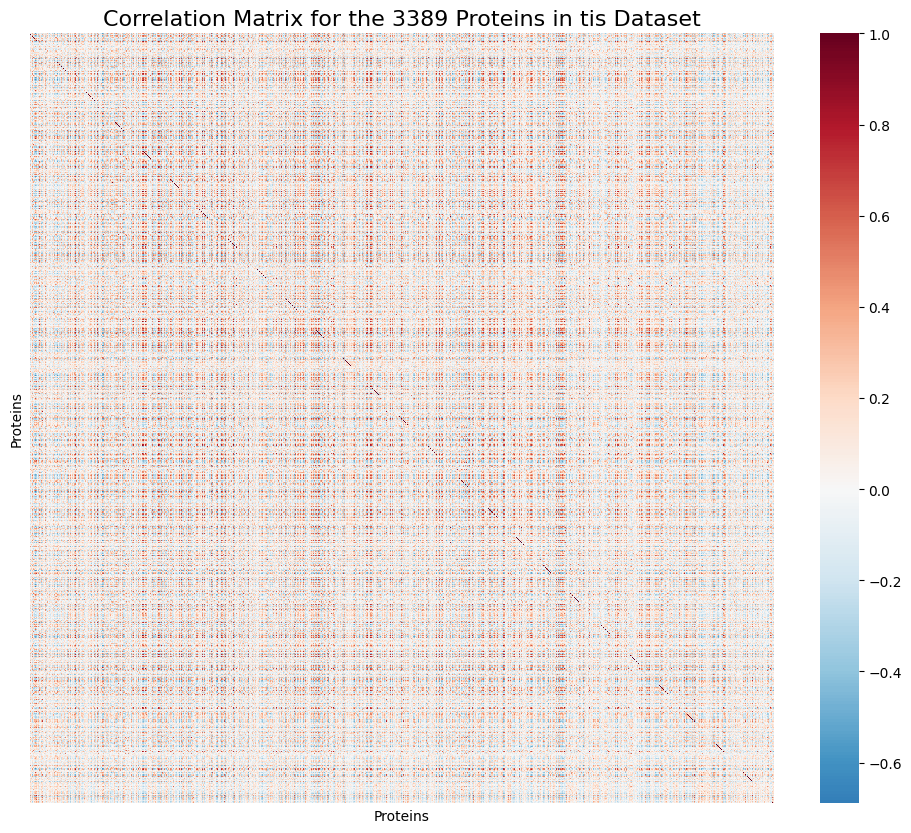

If you are seeing this, its done :)


In [ ]:
protein_cols = df.select_dtypes(include=['number']).columns.tolist()
print(f"Number of proteins: {len(protein_cols)}")

# 2. Calculate Correlation Matrix
print(f"Calculating correlation matrix for {len(protein_cols)} proteins...")
protein_corr_matrix = df[protein_cols].corr()

# 3. Plot the Correlation Matrix
plt.figure(figsize=(12, 10))
sns.heatmap(protein_corr_matrix,
            cmap='RdBu_r',
            center=0,
            xticklabels=False,
            yticklabels=False)

plt.title(f'Correlation Matrix for the {len(protein_cols)} Proteins in tis Dataset', fontsize=16)
plt.xlabel('Proteins')
plt.ylabel('Proteins')
plt.show()

print("If you are seeing this, its done :)")

In [ ]:
# Determine proteins that are strongly correlated
# We use '&' as pandas REALLY WANTS me to use & instead of AND
high_corr_proteins = protein_corr_matrix[(protein_corr_matrix >= 0.9) & (protein_corr_matrix != 1)]

# Display a snippet of the filtered matrix
display(high_corr_proteins)


,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
P37108;SRP14_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q96JP5;ZFP91_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P36578;RL4_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q6SPF0;SAMD1_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
O76031;CLPX_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P12074;CX6A1_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q8WY22;BRI3B_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q5HYI8;RABL3_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q8N131;PORIM_HUMAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# 1. stack() basically collapses the dataframe so that every index (row) has its own index (rows), one for every column
# so now every protein in the index has its own set of r values greater than 0.9 for every other protein
# this automatically removes NaNs
corr_pairs = high_corr_proteins.stack().reset_index()
# rename the columns, fundamentally Protein A is what used to be the index,
# Protein B are all the proteins in the column names where the corresponding value at Protein A row is greater than 0.9
corr_pairs.columns = ['Protein_A', 'Protein_B', 'Correlation']
print("Raw stacked correlated proteins:\n")
display(corr_pairs)

# 2. Since the matrix is symmetrical, each pair appears twice (A-B and B-A).
# We can filter to keep only unique pairs by keeping only entries where Protein A < Protein B (alphabetically speaking)
# Clever as when this correlation pair occurs again but the other way round ProteinA will be greater than B (alphabetically) so we only keep one...
unique_high_corr_proteins = corr_pairs[corr_pairs['Protein_A'] < corr_pairs['Protein_B']].sort_values(by='Correlation', ascending=False)

# 3. Display Results
print(f"Total strongly correlated protein pairs (r >= 0.9): {len(unique_high_corr_proteins)}")
display(unique_high_corr_proteins.head(20))
print(len(unique_high_corr_proteins))

pu1 = list(unique_high_corr_proteins["Protein_A"].unique())
pu2 = list(unique_high_corr_proteins["Protein_B"].unique())
pu1.extend(pu2)
pu1 = set(pu1)
print(f"\nNumber of unique proteins: {len(pu1)}")

Raw stacked correlated proteins:



,Protein_A,Protein_B,Correlation
0,P36578;RL4_HUMAN,Q07020;RL18_HUMAN,0.905872
1,P36578;RL4_HUMAN,P18124;RL7_HUMAN,0.919514
2,P52701;MSH6_HUMAN,P43246;MSH2_HUMAN,0.933585
3,P35221;CTNA1_HUMAN,O60716;CTND1_HUMAN,0.900100
4,O60716;CTND1_HUMAN,P35221;CTNA1_HUMAN,0.900100
...,...,...,...
521,P18621;RL17_HUMAN,P62241;RS8_HUMAN,0.902240
522,P48047;ATPO_HUMAN,P25705;ATPA_HUMAN,0.950650
523,Q58FF8;H90B2_HUMAN,P08238;HS90B_HUMAN,0.907124
524,Q9H0U6;RM18_HUMAN,Q8N983;RM43_HUMAN,0.911096


Total strongly correlated protein pairs (r >= 0.9): 263


,Protein_A,Protein_B,Correlation
225,P50991;TCPD_HUMAN,Q99832;TCPH_HUMAN,0.987534
271,P49736;MCM2_HUMAN,Q14566;MCM6_HUMAN,0.984462
86,P49368;TCPG_HUMAN,Q99832;TCPH_HUMAN,0.984168
261,P33993;MCM7_HUMAN,Q14566;MCM6_HUMAN,0.982688
218,P48643;TCPE_HUMAN,Q99832;TCPH_HUMAN,0.982608
265,P33993;MCM7_HUMAN,P49736;MCM2_HUMAN,0.982371
87,P49368;TCPG_HUMAN,P50990;TCPQ_HUMAN,0.982209
95,P25786;PSA1_HUMAN,P25787;PSA2_HUMAN,0.981866
184,P33991;MCM4_HUMAN,Q14566;MCM6_HUMAN,0.981433
242,P25205;MCM3_HUMAN,Q14566;MCM6_HUMAN,0.981185


263

Number of unique proteins: 173


#### Drop highly correlated proteins?


In [ ]:
proteins_to_drop_set = set()

# 1. Iterate through the rows of highly correlated protein pairs
for index, row in unique_high_corr_proteins.iterrows():
    p1 = row['Protein_A']
    p2 = row['Protein_B']

    # Calculate NaNs and variance for both proteins in the main dataframe
    nan_p1 = df[p1].isnull().sum()
    nan_p2 = df[p2].isnull().sum()

    var_p1 = df[p1].var()
    var_p2 = df[p2].var()

    # Selection logic:
    # 1. Drop the one with the greatest number of NaNs
    # 2. If NaNs are equal, drop the one with the least variance
    if nan_p1 > nan_p2:
        pick = p1
    elif nan_p2 > nan_p1:
        pick = p2
    else:
        # NaNs are equal, check SD
        if var_p1 > var_p2:
            pick = p2
        elif var_p2 > var_p1:
          pick = p1
        #if NaNs and Sd are equal, pick at random
        else:
            pick = random.choice([p1, p2])

    # Add the selected protein to the set
    proteins_to_drop_set.add(pick)

# Convert set back to list
proteins_to_drop_list = list(proteins_to_drop_set)

print(f"Proteins to drop: {len(proteins_to_drop_list)}")

Proteins to drop: 123


### Dropping highly correlated proteins in the dataset prior to splitting constitutes a massive data leakage error, termed "feature selection based on correlations computed on the entire dataset".

The fact that certain variables are pruned based on properties of the full dataset, tailors the learning environment of the model in a manner not specific to the training data it has access to. This can improve model performance in an unrealistic manner for the data it was given, since we are discarding unimportant variables a priori, rather than unimportant variables in the training data it was given.

### With the above code we have concluded that we can remove a significant number of variables from the dataset via covariance.
---


## **The dropping of highly correlated proteins will be introduced in the pipeline as a custom trasformer...**

## Replace NaNs with zeros

### NaNs will be replaced with zeros in the full dataset, this does not constitute a signficant data leakage risk, especially prior to data standardisation, as no property of the full dataset is really used in this process.

    - Technically in this proteomics data, the value zero represents a sort of harmonius anchor of the relative protein abundance. When a zero is present it means that the value of said protein is exactly the same as this theoretical anchor that was calculated, however since this proteomics data represents relative protein abundances, the value zero of itself is not actually the mean of each protein column and is in no way correlated to properties of the full dataset (read the introduction for more info)...

### Other imputation methods like substituing NaNs for the mean, would...

In [ ]:
#Fill every NaN value (only proteomics data has NaNs by this point) with 0
#This was also done in the article where I obtained the data from
df = df.fillna(0)

## Make Cell_line column the index

In [ ]:
df = df.set_index("Cell_line")

# 3. Exploratory Data Analysis

### Protein Expression Analysis by Tissue Type: Table

In [ ]:
# Ensure protein columns are correctly defined
# It should contain all numerical columns except the drug response columns if they are present.
protein_cols = [col for col in df.select_dtypes(include=['number']).columns if not col.endswith('_LN_IC50')]

# Group by 'Tissue_type' and calculate the mean for all protein columns
# Gives mean protein expression per tissue
protein_mean_per_tissue = df.groupby('Tissue_type')[protein_cols].mean()


# Group by 'Tissue_type' and calculate the standard deviation for all protein columns
protein_std_per_tissue = df.groupby('Tissue_type')[protein_cols].std()
protein_std_per_tissue = protein_std_per_tissue.fillna(0)

# Group by 'Tissue_type' and calculate the coefficient of variation for all protein columns
# CV = Standard Deviation / Mean
protein_cv_per_tissue = protein_std_per_tissue / protein_mean_per_tissue
protein_cv_per_tissue.replace([float('inf'), -float('inf')], pd.NA, inplace=True)
protein_cv_per_tissue = protein_cv_per_tissue.fillna(0)

#Formatted output
print("Mean protein value across tissues:")
display(protein_mean_per_tissue.head())
print("\nStandard deviation of protein values across tissues:")
display(protein_std_per_tissue.head())
print("\nCV of protein values across tissues:")
display(protein_cv_per_tissue.head())
print("\nInterpretation:")
print("The first table shows the mean expression level of each protein for each tissue type.")
print("The second table shows the standard deviation of each protein's expression level within each tissue type. A higher standard deviation indicates greater intra-class (within tissue type) variation for that protein.")
print("The third table shows the coefficient of variation (CV) for each protein within each tissue type. CV helps normalize the variation relative to the mean, allowing for a more comparable measure of dispersion.")

Mean protein value across tissues:


,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Bladder,6.144935,1.890240,7.136187,2.438502,4.667461,3.420031,4.053022,5.454670,1.431173,2.765960,...,2.703307,3.269475,3.162223,9.288000,3.046210,2.636211,3.942298,3.728722,5.106914,4.727105
Bone,6.535975,2.978407,7.374340,3.507700,4.545897,3.149914,5.033366,5.377705,1.669702,4.260191,...,3.899960,4.477239,3.064473,9.522570,3.249475,1.225608,0.921837,3.980397,4.050871,4.276554
Breast,6.329941,2.600197,7.103149,2.908797,4.632281,2.946047,4.903058,5.596246,1.464752,3.775901,...,3.734207,4.259813,2.558345,8.954790,1.636199,1.915132,4.025087,4.388294,4.482349,3.392373
Central Nervous System,6.174470,2.098454,7.458619,1.907865,4.404646,2.757108,4.531632,5.309141,1.070219,3.507760,...,3.765815,3.134083,2.748426,9.088936,3.353643,1.304938,1.233652,4.309079,5.220260,3.797028
Cervix,6.523480,2.940141,7.521590,2.959145,5.119768,3.502749,4.999852,5.991266,1.752482,3.794201,...,3.006820,6.079023,3.482638,9.360480,2.390050,2.237451,5.633674,4.017192,5.145483,3.829172



Standard deviation of protein values across tissues:


,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Bladder,0.658685,1.799835,0.557755,1.357258,0.483084,0.386282,1.396446,0.514537,1.265491,1.496942,...,1.797854,3.428855,2.157529,0.517627,2.282215,1.089031,2.649883,1.425732,1.979899,3.908304
Bone,0.585515,1.586305,0.522035,1.421359,0.386203,0.501511,1.144902,0.491085,1.104436,0.693443,...,0.393813,3.345623,2.320327,0.480081,2.072441,1.263528,2.036966,0.507237,2.230980,3.393613
Breast,0.565597,1.655878,0.439510,1.358516,0.378041,0.933154,1.073884,0.561564,1.100910,1.092516,...,0.708573,3.530585,2.248003,0.422147,2.155621,1.242836,2.839804,0.784840,2.488816,3.735355
Central Nervous System,0.418972,1.883375,0.434321,1.619864,0.403547,1.217608,0.954667,0.639669,1.101592,0.834556,...,0.904146,3.490895,2.475288,0.484188,2.009743,1.362248,2.196254,0.519415,2.099335,3.639016
Cervix,0.438152,1.388926,0.384958,0.859176,0.316582,0.413320,0.760248,0.465222,0.860091,1.282955,...,1.381444,2.719023,2.035365,0.431736,1.991250,1.315143,0.479224,0.372165,2.412603,3.727279



CV of protein values across tissues:


,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Bladder,0.107192,0.952172,0.078159,0.556595,0.103500,0.112947,0.344544,0.094330,0.884233,0.541202,...,0.665057,1.048748,0.682282,0.055731,0.749198,0.413105,0.672167,0.382365,0.387690,0.826786
Bone,0.089583,0.532602,0.070791,0.405211,0.084956,0.159214,0.227463,0.091319,0.661457,0.162773,...,0.100979,0.747251,0.757170,0.050415,0.637777,1.030940,2.209682,0.127434,0.550741,0.793539
Breast,0.089353,0.636828,0.061875,0.467037,0.081610,0.316748,0.219023,0.100347,0.751602,0.289339,...,0.189752,0.828812,0.878694,0.047142,1.317456,0.648956,0.705526,0.178849,0.555248,1.101104
Central Nervous System,0.067855,0.897506,0.058231,0.849045,0.091619,0.441625,0.210667,0.120484,1.029314,0.237917,...,0.240093,1.113849,0.900620,0.053272,0.599272,1.043918,1.780286,0.120540,0.402151,0.958385
Cervix,0.067165,0.472401,0.051180,0.290346,0.061835,0.117999,0.152054,0.077650,0.490785,0.338136,...,0.459437,0.447280,0.584432,0.046123,0.833142,0.587787,0.085064,0.092643,0.468878,0.973390



Interpretation:
The first table shows the mean expression level of each protein for each tissue type.
The second table shows the standard deviation of each protein's expression level within each tissue type. A higher standard deviation indicates greater intra-class (within tissue type) variation for that protein.
The third table shows the coefficient of variation (CV) for each protein within each tissue type. CV helps normalize the variation relative to the mean, allowing for a more comparable measure of dispersion.


### We can see that some tissues have low standard deviation for most proteins, some even zero (e.g. Adrenal Gland).

### This is likely due to a very low number of entries for that tissue...

In [ ]:
# Calculate the number of entries for each tissue type
#size returns the number of elements in the grouped df by tissue
tissue_counts = df.groupby('Tissue_type').size().sort_values(ascending=False)

print("Number of entries per tissue type:")
print(tissue_counts)

Number of entries per tissue type:
Tissue_type
Lung                           187
Haematopoietic and Lymphoid    163
Skin                            54
Central Nervous System          53
Breast                          50
Large Intestine                 47
Ovary                           41
Bone                            40
Head and Neck                   39
Esophagus                       35
Kidney                          32
Peripheral Nervous System       30
Pancreas                        30
Stomach                         27
Soft Tissue                     22
Bladder                         18
Liver                           16
Thyroid                         16
Cervix                          13
Endometrium                     10
dtype: int64


###Indeed some tissues only have very few data points




## Since we saw that some tissues have very few entries, lets filter the data to remove tissues with less than 10 entries...

## Filter df to include only tissues with more than 10 cell types in the dataset

### Find tissues with less than 10 cell types in the dataset

In [ ]:
# Calculate the number of entries for each tissue type
#size returns the number of elements in the grouped df by tissue
tissue_counts = df.groupby('Tissue_type').size().sort_values(ascending=False)

print("Number of entries per tissue type:")
print(tissue_counts)

Number of entries per tissue type:
Tissue_type
Lung                           187
Haematopoietic and Lymphoid    163
Skin                            54
Central Nervous System          53
Breast                          50
Large Intestine                 47
Ovary                           41
Bone                            40
Head and Neck                   39
Esophagus                       35
Kidney                          32
Peripheral Nervous System       30
Pancreas                        30
Stomach                         27
Soft Tissue                     22
Bladder                         18
Liver                           16
Thyroid                         16
Cervix                          13
Endometrium                     10
dtype: int64


In [ ]:
# Select all tissue types that have less than 10 entries
tissues_to_drop = tissue_counts[tissue_counts < 10]

print("Tissue types with less than 10 entries:")
print(tissues_to_drop, type(tissues_to_drop))

print("\n\n")
tissues_to_drop = list(tissues_to_drop.index)
print(f"Tissue (<10 entries) list: {tissues_to_drop} \nType: {type(tissues_to_drop)}")



Tissue types with less than 10 entries:
Series([], dtype: int64) <class 'pandas.core.series.Series'>



Tissue (<10 entries) list: [] 
Type: <class 'list'>


### Drop tissues with less than 10 entries

In [ ]:
# Filter out the minority tissue types identified in the previous cell
# This removes any rows where 'Tissue_type' is in our 'tissues_to_drop' list
####################################################################
# Before filtering
num_tissue_types_before_drop = len(df['Tissue_type'].unique())
num_rows_before_drop = df.shape[0]
###################################################################

# Using .loc to isolate rows which have a tissue type
#in our tissues to drop (less than 10 entries)
#retrieve their index
rows_to_drop_index = df.loc[df['Tissue_type'].isin(tissues_to_drop)].index
#drop the collected indices
df = df.drop(index=rows_to_drop_index)

##################################################################
#Formatting the output
sep = 30 * "-"
print(f"Number of tissue types before dropping: {num_tissue_types_before_drop}")
print(f"Number of rows before dropping: {num_rows_before_drop}")
print(sep)
print(f"Number of tissue types after dropping: {len(df['Tissue_type'].unique())}")
print(f"Number of entries (rows) after dropping: {df.shape[0]}")
print(sep)
print("Remaining Tissue Types:")
print(df['Tissue_type'].value_counts())

Number of tissue types before dropping: 20
Number of rows before dropping: 923
------------------------------
Number of tissue types after dropping: 20
Number of entries (rows) after dropping: 923
------------------------------
Remaining Tissue Types:
Tissue_type
Lung                           187
Haematopoietic and Lymphoid    163
Skin                            54
Central Nervous System          53
Breast                          50
Large Intestine                 47
Ovary                           41
Bone                            40
Head and Neck                   39
Esophagus                       35
Kidney                          32
Pancreas                        30
Peripheral Nervous System       30
Stomach                         27
Soft Tissue                     22
Bladder                         18
Thyroid                         16
Liver                           16
Cervix                          13
Endometrium                     10
Name: count, dtype: int64


### From here onwards the dataset contains:
- 923 rows (cancer cell lines)
- 3268 columns (proteins)

In [ ]:
# Calculate the number of cell lines (entries) per Tissue_type
tissue_counts = df['Tissue_type'].value_counts()

# Identify tissue types with more than 10 entries
filtered_tissue_types = tissue_counts[tissue_counts > 10].index.tolist()
print(30*"=")
print(f"Tissue types with more than 10 cell lines ({len(filtered_tissue_types)}): {filtered_tissue_types}")
print(30*"=")
# Filter protein_mean_per_tissue and protein_std_per_tissue
protein_mean_per_tissue_filtered = protein_mean_per_tissue.loc[filtered_tissue_types]
protein_std_per_tissue_filtered = protein_std_per_tissue.loc[filtered_tissue_types]

# Filter protein_cv_per_tissue
protein_cv_per_tissue_filtered = protein_cv_per_tissue.loc[filtered_tissue_types]
print(30*"=")
display("Filtered Mean Protein Expression per Tissue Type:\n", protein_mean_per_tissue_filtered.head())
print(30*"=")
display("Filtered Standard Deviation of Protein Expression per Tissue Type:\n", protein_std_per_tissue_filtered.head())
print(30*"=")
display("Filtered Coefficient of Variation of Protein Expression per Tissue Type:\n", protein_cv_per_tissue_filtered.head())

Tissue types with more than 10 cell lines (19): ['Lung', 'Haematopoietic and Lymphoid', 'Skin', 'Central Nervous System', 'Breast', 'Large Intestine', 'Ovary', 'Bone', 'Head and Neck', 'Esophagus', 'Kidney', 'Pancreas', 'Peripheral Nervous System', 'Stomach', 'Soft Tissue', 'Bladder', 'Thyroid', 'Liver', 'Cervix']


'Filtered Mean Protein Expression per Tissue Type:\n'

,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Lung,6.560032,2.655720,7.183544,2.661974,4.539785,3.257135,5.111448,5.803492,1.589550,4.197512,...,3.610340,4.425660,2.978463,9.267271,2.329007,1.802425,3.399117,3.897724,4.679509,4.329136
Haematopoietic and Lymphoid,6.846141,2.558090,7.494001,3.170455,4.305370,3.220711,6.157197,5.286597,1.489841,4.180039,...,3.954478,2.795874,3.205740,9.228883,2.277362,0.965052,3.550402,3.034307,3.140830,3.461970
Skin,6.283392,2.764027,7.558099,1.646620,4.716104,2.959851,4.803594,5.802276,1.179497,3.639642,...,3.624043,4.870466,2.355954,8.925249,2.392238,1.478363,2.325139,3.585796,5.508562,4.073804
Central Nervous System,6.174470,2.098454,7.458619,1.907865,4.404646,2.757108,4.531632,5.309141,1.070219,3.507760,...,3.765815,3.134083,2.748426,9.088936,3.353643,1.304938,1.233652,4.309079,5.220260,3.797028
Breast,6.329941,2.600197,7.103149,2.908797,4.632281,2.946047,4.903058,5.596246,1.464752,3.775901,...,3.734207,4.259813,2.558345,8.954790,1.636199,1.915132,4.025087,4.388294,4.482349,3.392373


'Filtered Standard Deviation of Protein Expression per Tissue Type:\n'

,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Lung,0.617976,1.790591,0.547981,1.796161,0.531295,0.841612,1.248267,0.599358,1.202391,1.006307,...,1.083924,3.348391,2.289108,0.530518,2.094631,1.387102,2.934298,0.987482,2.207987,3.620701
Haematopoietic and Lymphoid,0.507519,1.505362,0.453329,1.039936,0.322235,0.812404,0.546389,0.508636,0.977261,1.370518,...,0.501766,3.207716,2.239466,0.355579,1.916351,1.213867,2.770148,1.376074,2.455370,3.488368
Skin,0.447594,1.713353,0.351256,1.450482,0.432131,1.061287,0.715958,0.441089,1.061145,0.517127,...,1.129789,3.355011,2.405898,0.466952,2.133601,1.424498,2.642346,1.214854,1.599208,3.707901
Central Nervous System,0.418972,1.883375,0.434321,1.619864,0.403547,1.217608,0.954667,0.639669,1.101592,0.834556,...,0.904146,3.490895,2.475288,0.484188,2.009743,1.362248,2.196254,0.519415,2.099335,3.639016
Breast,0.565597,1.655878,0.439510,1.358516,0.378041,0.933154,1.073884,0.561564,1.100910,1.092516,...,0.708573,3.530585,2.248003,0.422147,2.155621,1.242836,2.839804,0.784840,2.488816,3.735355


'Filtered Coefficient of Variation of Protein Expression per Tissue Type:\n'

,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,P52701;MSH6_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Tissue_type,,,,,,,,,,,,,,,,,,,,,
Lung,0.094203,0.674239,0.076283,0.674748,0.117031,0.258390,0.244210,0.103275,0.756435,0.239739,...,0.300228,0.756586,0.768554,0.057246,0.899367,0.769575,0.863253,0.253348,0.471842,0.836357
Haematopoietic and Lymphoid,0.074132,0.588471,0.060492,0.328008,0.074845,0.252244,0.088740,0.096212,0.655950,0.327872,...,0.126886,1.147304,0.698580,0.038529,0.841478,1.257825,0.780235,0.453505,0.781758,1.007625
Skin,0.071234,0.619876,0.046474,0.880884,0.091629,0.358561,0.149046,0.076020,0.899658,0.142082,...,0.311748,0.688848,1.021199,0.052318,0.891885,0.963565,1.136425,0.338796,0.290313,0.910182
Central Nervous System,0.067855,0.897506,0.058231,0.849045,0.091619,0.441625,0.210667,0.120484,1.029314,0.237917,...,0.240093,1.113849,0.900620,0.053272,0.599272,1.043918,1.780286,0.120540,0.402151,0.958385
Breast,0.089353,0.636828,0.061875,0.467037,0.081610,0.316748,0.219023,0.100347,0.751602,0.289339,...,0.189752,0.828812,0.878694,0.047142,1.317456,0.648956,0.705526,0.178849,0.555248,1.101104


### Visualizing Inter-Class Variation: Pairwise Distances Between Tissue Types with at least 10 entries

Number of tissues: 20
This heatmap shows the pairwise Euclidean distances between the mean protein expression profiles of different tissue types, restricted to tissues with more than 10 cell lines.


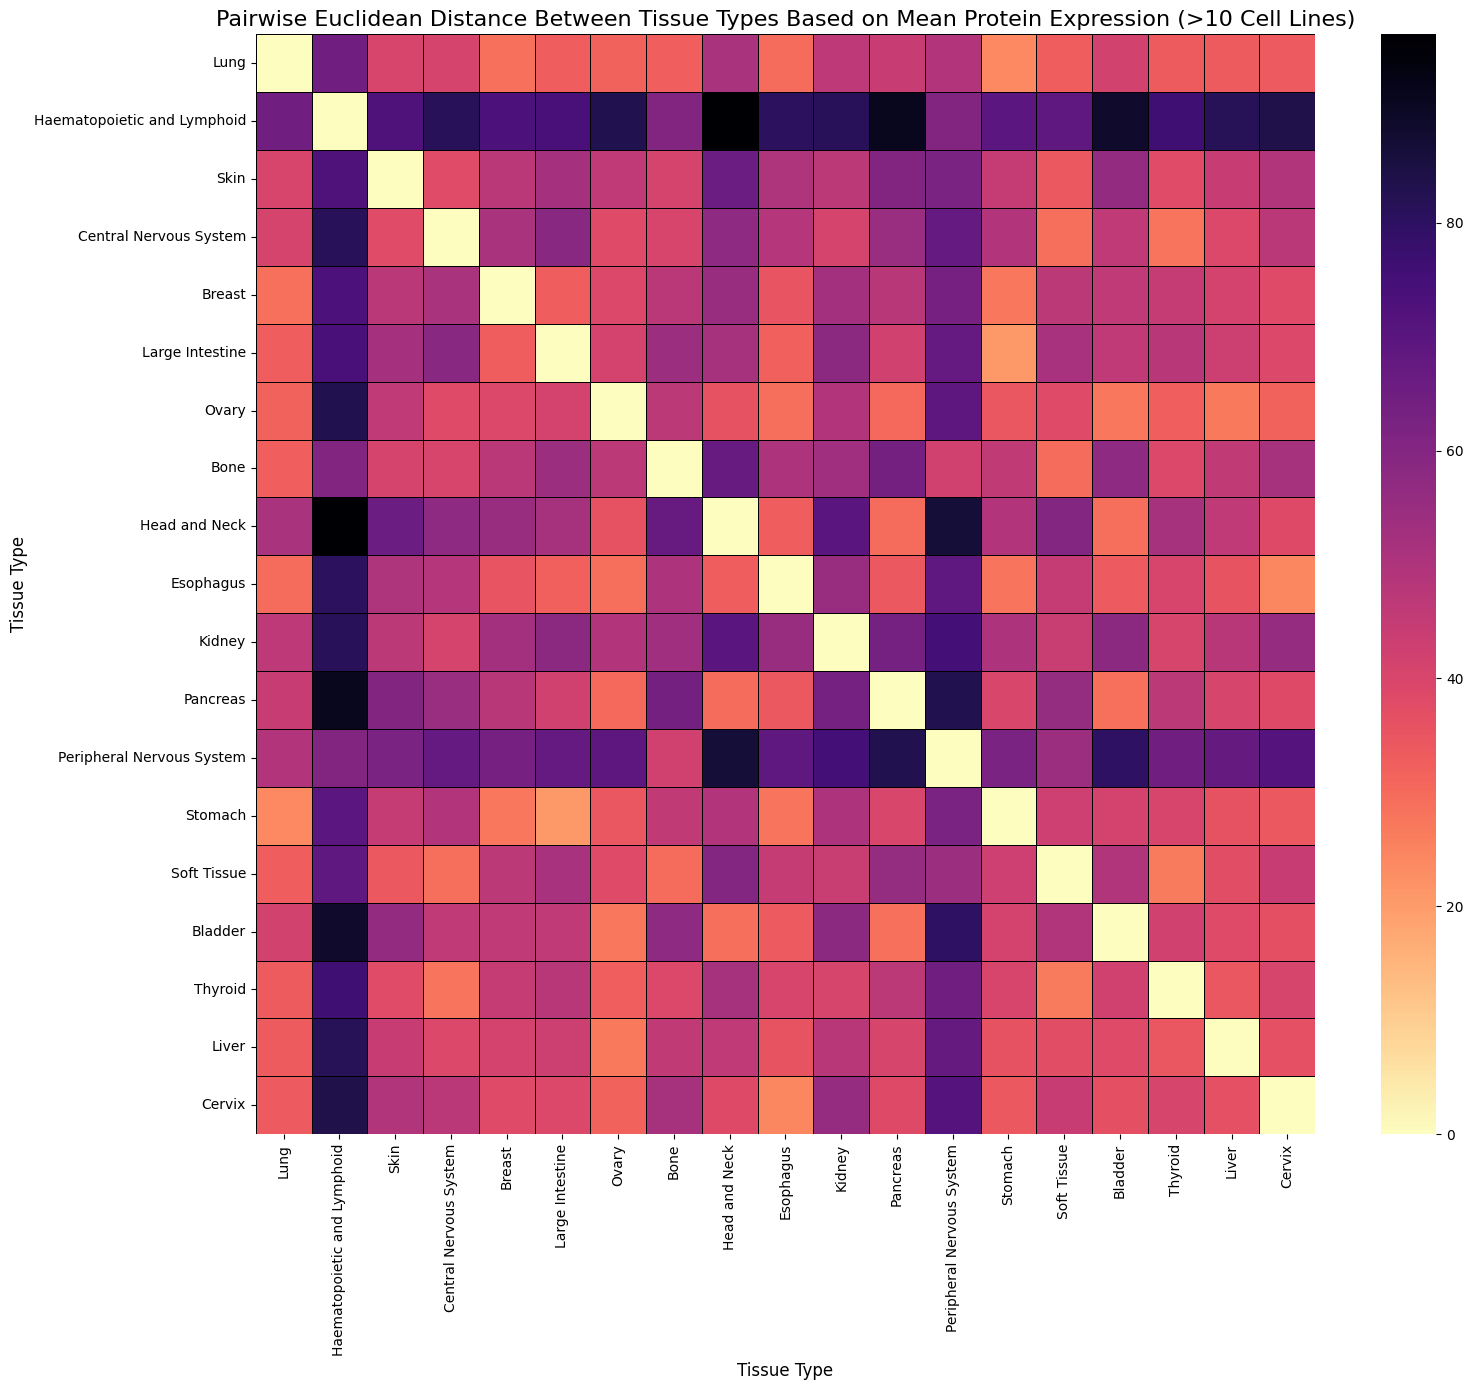

In [ ]:

# Calculate pairwise Euclidean distances between filtered tissue types based on mean protein expression
protein_mean_filled_filtered = protein_mean_per_tissue_filtered.fillna(0)

tissue_distances_filtered = pdist(protein_mean_filled_filtered, metric='euclidean')
distance_matrix_filtered = squareform(tissue_distances_filtered)

# Convert to a DataFrame for better labeling
distance_df_filtered = pd.DataFrame(distance_matrix_filtered, index=protein_mean_filled_filtered.index, columns=protein_mean_filled_filtered.index)

#Formatted output
print(f"Number of tissues: {len(df["Tissue_type"].unique().tolist())}")
print("This heatmap shows the pairwise Euclidean distances between the mean protein expression profiles of different tissue types, restricted to tissues with more than 10 cell lines.")

plt.figure(figsize=(16, 14))
sns.heatmap(distance_df_filtered, annot=False, cmap='magma_r', fmt=".1f", linewidths=.5, linecolor='black')
plt.title('Pairwise Euclidean Distance Between Tissue Types Based on Mean Protein Expression (>10 Cell Lines)', fontsize=16)
plt.xlabel('Tissue Type', fontsize=12)
plt.ylabel('Tissue Type', fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



### We can definitely see that some tissue types are particularly different from all the rest:
- Haematopoietic and Lymphoid
- Peripheral Nervous System

### Exploring Class Distributions of tissues with at least 10 entries

Counts of entries per tissue type:

Tissue_type
Lung                           187
Haematopoietic and Lymphoid    163
Skin                            54
Central Nervous System          53
Breast                          50
Large Intestine                 47
Ovary                           41
Bone                            40
Head and Neck                   39
Esophagus                       35
Kidney                          32
Pancreas                        30
Peripheral Nervous System       30
Stomach                         27
Soft Tissue                     22
Bladder                         18
Thyroid                         16
Liver                           16
Cervix                          13
Endometrium                     10
Name: count, dtype: int64 
Total: 923




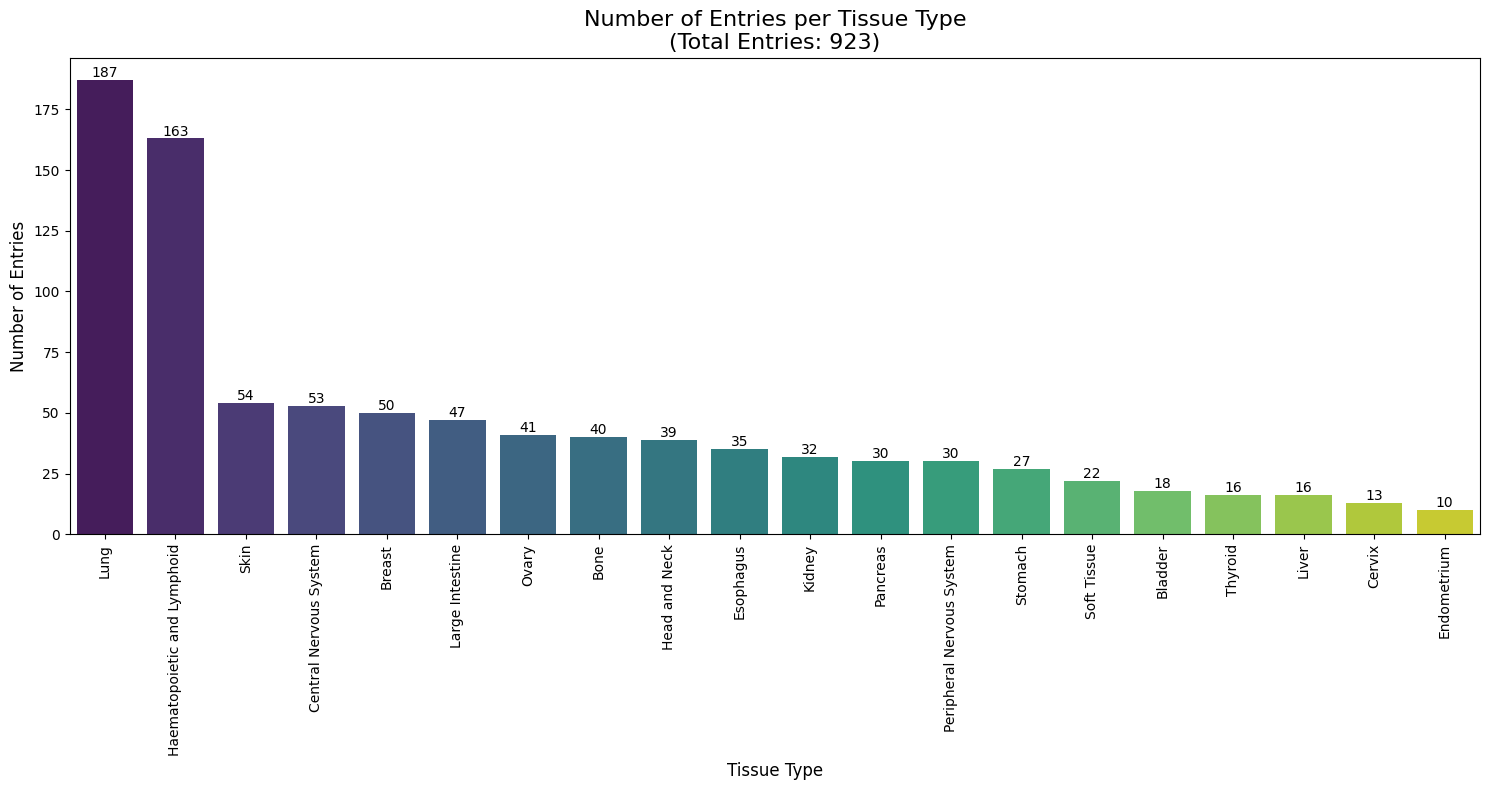

In [ ]:

total_entries = len(df["Tissue_type"])
tissue_counts = df['Tissue_type'].value_counts()

#Format the output
print("Counts of entries per tissue type:\n")
print(f"{tissue_counts} \nTotal: {tissue_counts.sum()}\n\n")
plt.figure(figsize=(15, 8))
ax = sns.barplot(x=tissue_counts.index, y=tissue_counts.values, palette='viridis', hue=tissue_counts.index, legend=False)
plt.title(f'Number of Entries per Tissue Type\n(Total Entries: {total_entries})', fontsize=16)
plt.xlabel('Tissue Type', fontsize=12)
plt.ylabel('Number of Entries', fontsize=12)
plt.xticks(rotation=90) # Rotate x-axis labels for better readability

# Add data labels on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

###The classes in my selected target seem to be very imbalanced, however removing too many entries is too costly for me as this dataset already contains many more features than entries.

### Unfortunately I would rather not remove more entries, I will try to obviate this issue in training and tuning...

## More exploration of Tissue Types with more than 10 entries:

### Visualizing Inter-Tissue Variation (Filtered: >10 Cell Lines)

# 4. Dataset Split

- Features: Proteins
- Target: Tissue Type

Ratio: 30% test, 70% train

In [ ]:
proteins = df.select_dtypes(include="number").columns.tolist()
cats = df.select_dtypes(include="object").columns.tolist()
print(20*"=")
print(f"Proteins: {len(proteins)} \nCategoricals: {len(cats)} \nCategorical Variables:{cats} \nRows: {len(df)}")
print(20*"=", "\n")
print("Final Data before the next step:\n")
display(df.head())


Proteins: 3389 
Categoricals: 1 
Categorical Variables:['Tissue_type'] 
Rows: 923

Final Data before the next step:



,Tissue_type,P37108;SRP14_HUMAN,Q96JP5;ZFP91_HUMAN,P36578;RL4_HUMAN,Q6SPF0;SAMD1_HUMAN,O76031;CLPX_HUMAN,Q9BTD8;RBM42_HUMAN,Q9P258;RCC2_HUMAN,Q8TCS8;PNPT1_HUMAN,Q96L91;EP400_HUMAN,...,P62877;RBX1_HUMAN,Q9NX14;NDUBB_HUMAN,Q4VXU2;PAP1L_HUMAN,P09651;ROA1_HUMAN,P01111;RASN_HUMAN,P12074;CX6A1_HUMAN,Q8WY22;BRI3B_HUMAN,Q5HYI8;RABL3_HUMAN,Q8N131;PORIM_HUMAN,Q86SE5;RALYL_HUMAN
Cell_line,,,,,,,,,,,,,,,,,,,,,
K052,Haematopoietic and Lymphoid,7.109545,3.414941,7.866614,3.895467,4.196655,3.190877,7.358065,4.841903,2.494679,...,4.260154,6.070841,0.000000,9.259751,0.000000,1.671608,6.007174,3.815668,4.769969,7.084055
TE-12,Esophagus,6.828022,4.143455,7.628785,3.198109,4.609018,3.695348,5.707904,5.591560,2.345347,...,3.852484,6.135780,3.760480,9.084405,4.426812,3.039617,5.769395,4.297804,5.295486,8.294270
TMK-1,Stomach,7.014256,4.199872,8.124585,0.000000,4.768811,0.000000,5.522833,5.453060,1.685853,...,3.885525,0.000000,4.428223,9.014724,0.000000,0.000000,0.000000,3.856578,4.699897,0.000000
STS-0421,Stomach,5.285911,3.357894,7.972680,0.000000,4.520923,2.730884,4.294287,5.426244,2.686038,...,4.072270,7.176259,4.989266,8.812034,0.000000,2.077865,0.000000,3.962057,4.302191,6.306365
PL4,Pancreas,5.707857,0.000000,6.225738,0.000000,4.495795,2.879809,0.000000,6.292383,0.000000,...,2.385021,0.000000,0.000000,7.810233,2.913824,3.885762,4.255781,0.000000,6.024478,7.480701


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# 1. Define features X (all protein columns) and target y (Tissue_type)
X = df.select_dtypes(include=['number'])
y = df['Tissue_type']

# 2. Split the data into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=33, stratify=y   #stratify to make sure all tissue types are present in both training and testing
)

# 3. Print the shapes to confirm the split
print(f"Total samples: {len(df)}")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"Number of features: {X_train.shape[1]}")

Total samples: 923
Training set size: 646 samples
Testing set size: 277 samples
Number of features: 3389


#5. Processing After The Split

1. Data standardisation
2. PCA dimensionality reduction

These steps are `carried out singularly at first, to analyse and visualise the data after these trasformations`, but it will eventually be incorporated into a scikit pipeline to preven leakage and simplify the code.

Categorical columns

In [ ]:
#Make a list of the categorical columns (already have one but lets redefine it for clarity)
cat_cols = df.select_dtypes(include="object").columns.tolist()
print(f"Categories to encode: {cat_cols}")
for cat in cat_cols:
  print(f"{cat}: {len(df[cat].unique().tolist())} unique values")

## Standardisation

In [ ]:

#Standardize the data
scaler = StandardScaler()
#Fir scaler onto training data and transofrm it
X_train_Z = scaler.fit_transform(X_train)
#transofrm the testing data using the parameters of the training data
X_test_Z = scaler.transform(X_test)

# Formatted output
stats_df = pd.DataFrame({
    'Mean': X_train_Z[:, :5].mean(axis=0),
    'Std Dev': X_train_Z[:, :5].std(axis=0)
}, index=X_train.columns[:5])

print(20*"=")
print("Confirmation that all data has been standardised: (mean=0, sd=1)")
display(stats_df.round(4))
print(f"\nTrain Shape: {X_train_Z.shape} | Test Shape: {X_test_Z.shape}")

## Dimensionality Reduction with PCA



Calculating the Principal Components so that they explain 95% of the variance

In [ ]:

print("--- PCA: Reducing to explain 95% Variance ---")
# Initialize PCA to explain 95% of the variance
pca_95_variance = PCA(n_components=0.95)

# Fit PCA on the standardized training data and transform it
X_train_pca_95 = pca_95_variance.fit_transform(X_train_Z)

# Create a DataFrame preserving the original Cell_line index
X_train_pca_95_df = pd.DataFrame(
    X_train_pca_95,
    columns=[f'PC{i+1}' for i in range(X_train_pca_95.shape[1])],
    index=X_train.index
)

print(f"Original X_train_Z shape: {X_train_Z.shape}")
print(f"Transformed X_train_pca_95 shape: {X_train_pca_95.shape}")
print(f"Number of components to explain 95% variance: {pca_95_variance.n_components_}")
print("Total explained variance for 95% components:", pca_95_variance.explained_variance_ratio_.sum())

print("First 5 rows of PCA-transformed training data (95% variance):")
display(X_train_pca_95_df.head())

# Create and display a dataframe of explained variance per component
explained_variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca_95_variance.explained_variance_ratio_))],
    'Explained Variance Ratio': pca_95_variance.explained_variance_ratio_
}).sort_values(by='Explained Variance Ratio', ascending=False)

print("\nExplained variance by each principal component (Sorted Descending):")
display(explained_variance_df)

### Plotting PCA data:

In [ ]:

# 1. Prepare Data for 3D Plot using top 3 PCs from the 95% variance DF
# We extract only PC1, PC2, and PC3
plot_df = X_train_pca_95_df[['PC1', 'PC2', 'PC3']].copy()
if 'Tissue_type' not in plot_df.columns:
    plot_df['Tissue_type'] = y_train.loc[plot_df.index]

# 2. Create Single 3D Scatter Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

tissues = plot_df['Tissue_type'].unique()
palette = sns.color_palette('tab20', len(tissues))
colors = dict(zip(tissues, palette))

for tissue in tissues:
    subset = plot_df[plot_df['Tissue_type'] == tissue]
    ax.scatter(subset['PC1'], subset['PC2'], subset['PC3'],
                label=tissue, color=colors[tissue], s=30, alpha=0.6)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('3D PCA of Tissue Types (Top 3 Components)')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Tissue Type', fontsize='x-small')
plt.tight_layout()
plt.show()

# 3. Scree Plot with Explicit Milestone Labels
exp_var_ratio = pca_95_variance.explained_variance_ratio_
cum_var_ratio = np.cumsum(exp_var_ratio)

plt.figure(figsize=(14, 7))
plt.bar(range(1, len(exp_var_ratio) + 1), exp_var_ratio, alpha=0.4, align='center', label='Individual Variance')
plt.step(range(1, len(exp_var_ratio) + 1), cum_var_ratio, where='mid', label='Cumulative Variance', color='red', lw=2)

# Thresholds for vertical lines
thresholds = [0.50, 0.75, 0.90, 0.95]
for t in thresholds:
    idx = np.where(cum_var_ratio >= t)[0][0] + 1
    plt.axvline(x=idx, color='black', linestyle='--', alpha=0.8)
    plt.text(idx, 0.1, f'PC{idx}\n({t*100:.0f}%)', color='black',
             fontweight='bold', ha='center', va='bottom',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component Index')
plt.title('Scree Plot: PCs needed for Various Variance Targets')
plt.legend(loc='center right')
plt.grid(axis='both', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


1. Three dimensions are definitelly not enough to clearly cluster the data, however we can discern the "Haematopoietic and Lymphoid" population as somewhat of a distinct cluster. This is consistent with the Eucledean ditance matrix generated above, showing that this tissue type (along with "Peripheral Nervous System") is particularly distinct.

2. From the SCREE plot we can clearly see that the **components needed to jump from explaining 90 to 95% of variance** (so only a 5% change) **are more than 100 components**.

### **Therefore if PCA is included in the PipeLine, it will be so that it explains 90% of variance...**

# 6 - Model selection and comparison



## Preprocessing and Model Selection Pipeline:

1. `Data standardisation with StandardScaler`
2. `Dropping of highly correlated proteins`: Custom scikit Trasformer
2. `PCA dimensionality reduction` : Either performed or not performed
3. `Model fitting` and performance evaluation with macro-F1 score (mean F1 across every target class and averaged for every fold of the cross validation) for `various models`

- `GridSearch was used` to test various combinations of these steps, namely performing or not the PCA and fitting various models.


- The scikit library, unfortunately, does not have a built in method to encode only the target variable from within a pipeline (according to what I could find online :). Instead of downloading and trying to understand another package (imbl), I just encoded the target variable out of the pipeline and reused that...

In [ ]:
# XGBoost requires a label-encoded target variable but the other models also support it...
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
# Trasformed also the test target, for simplicity.
y_test_encoded = le.transform(y_test)

print("Encoded training target\n")
print(y_train_encoded)

print("\n\nEncoded test target\n")
print(y_test_encoded)

Encoded training target

[18 18 15  7 18  8  7  2 12  2  7  2  1  7 12 13 14 13  6  5  8 17 10  6
 12 10 12 19  2  7 10 10 14 13  7 12  8 12 16  7 12  1  6 10 10 15 12 12
  3  4 10  7 17 10 13  3 11  3 12  2  2  7 12 18 12  8  7  2 16 12  1  7
  7  6  5  7  7 12  7 12 12 12 12  9 18  7  2  4 17 12  1  8  1 12 11 17
 16  7  9 12  7 11  3 15  2  7 15  7  7  6  0  3 14 19  7 12  0 12 12 12
  8 16  8 16  8 16  7 17  2  7 16  8 18 17 18  8  7 12 12 17  7  1  2  7
 12  9 12  7  7 13  7 12  7  7  8  8 12 18 14 11 16  7  9 10  1 12  2  7
 12 12 19 13  1 12 12  2 16  8  3  7  2 17  7  3  8 10  7 19  7 16  0 16
 10  4  3 15  7 12  1 12  7 14 12 13 14 12 12 12  2  7  7 18  7 12 10  9
 12  7  3 14 10 14 16 16  7  6 12  7 15 16 10  7 13  6 12 12 18  8  7 17
 16  9  1 17 12  2  8 12 12  7  6 10  7 12  7 15  3 12 12 17  0 13 15  4
  3  7  6  9  3  3  7 12  7 12 14 12 12  3 12 12 12 12 16  8  2 15 12 10
 16  0 16  6  3  7 14  9  7  7 10 12 12 18  7 14  9  7 10  1 13  7  1 13
  2 14  1 12  8  2  6  7 1

### Create the custom trasformer:


In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class DropCorrelatedFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.9):
        self.threshold = threshold
        self.to_drop_ = []

    def fit(self, X, y=None):
        # np.asarray ensures X behaves like a numpy array for the math, even if it is passed as a pandas dataframe
        X_array = np.asarray(X)
        corr_matrix = (np.corrcoef(X_array, rowvar=False))
        upper_tri = np.triu(corr_matrix, k=1)

        self.to_drop_ = [column for column in range(upper_tri.shape[1])
                         if any(upper_tri[:, column] > self.threshold)]

        return self

    def transform(self, X, y=None):
        # If X is a pandas DataFrame, drop features using column names
        if isinstance(X, pd.DataFrame):
            return X.drop(X.columns[self.to_drop_], axis=1)

        # If X is a NumPy array, use the original np.delete method
        return np.delete(X, self.to_drop_, axis=1)

## Custom Transformer Explained:
---

### The Imports & Architecture

```python
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

```

* **`import numpy as np`**: Imports NumPy, which provides low-level, compiled C-arrays and optimized linear algebra routines.
* **`import pandas as pd`**: Imports Pandas for high-level data manipulation structures (DataFrames) and metadata preservation.
* **`from sklearn.base import BaseEstimator, TransformerMixin`**: Imports the foundation blocks for the scikit-learn API.
* **`BaseEstimator`** grants your class internal scikit-learn behaviors via object introspection. It automatically gives you methods like `get_params()` and `set_params()`, allowing your class to work with hyperparameter tuning utilities like `GridSearchCV`.
* **`TransformerMixin`** automatically implements the `fit_transform()` method for you by simply chaining your `fit()` and `transform()` methods together behind the scenes.



```python
class DropCorrelatedFeatures(BaseEstimator, TransformerMixin):

```

* Defines a new Python class utilizing **multiple inheritance**. By inheriting from both mixins, this class formally qualifies as a standard scikit-learn transformer component.

---

## The Constructor (`__init__`)

```python
    def __init__(self, threshold=0.9):
        self.threshold = threshold
        self.to_drop_ = []

```

* **`def __init__(self, threshold=0.9):`**: The object initializer (constructor). It exposes `threshold` as a user-defined hyperparameter, defaulting to $0.9$.
* **`self.threshold = threshold`**: Assigns the user-defined value to an instance variable.
* **`self.to_drop_ = []`**: Instantiates an empty state variable. The trailing underscore is a critical scikit-learn naming convention. It signifies that this attribute is **estimated/learned during fitting** and does not exist until `fit()` is called. It acts as the memory bank storing feature indices flagged for deletion.

---

### The Fitting Phase (`fit`)

The purpose of this method is **state encapsulation**—it reads the data, learns the rules, and modifies `self.to_drop_`.

```python
    def fit(self, X, y=None):

```

* Accepts `X` (the feature matrix of shape $(n_{samples}, n_{features})$). It accepts `y` (the target array) but defaults it to `None` to comply with the structural requirements of the scikit-learn Pipeline API, which expects a uniform signature across all steps.

```python
        X_array = np.asarray(X)

```

* **Type Coercion**: This converts `X` into a native NumPy array, regardless of whether a Pandas DataFrame or a raw array was passed in. This guarantees that all downstream linear algebra calculations execute without type mismatches or index errors.

```python
        corr_matrix = np.abs(np.corrcoef(X_array, rowvar=False))

```

* **`np.corrcoef(..., rowvar=False)`**: Computes the Pearson product-moment correlation coefficients. Setting `rowvar=False` ensures that columns represent variables (proteins) and rows represent observations (cells). If you have $p$ proteins, this yields a symmetric matrix of shape $(p, p)$.
* This custom transformer DOES NOT compute the absolute coefficient, so only highly positively correlated proteins will be dropped. I believe that inversely correlated proteins could still inform the model, while proteins with very similar trends in general may just add noise...
```python
        upper_tri = np.triu(corr_matrix, k=1)

```

* **Matrix Manipulation**: The `np.triu()` function extracts the upper triangle of the matrix. The parameter `k=1` is the diagonal offset. It zeros out the main diagonal (where every feature has a perfect $1.0$ correlation with itself) and everything below it.
* Because a correlation matrix is perfectly symmetrical ($R_{ij} = R_{ji}$), looking at the full matrix would flag both variables in a collinear pair. Zeroing out the bottom half ensures that if Protein A and Protein B are highly correlated, only *one* of them retains a value above the threshold in this matrix.

```python
        self.to_drop_ = [column for column in range(upper_tri.shape[1])
                         if any(upper_tri[:, column] > self.threshold)]

```

* **Conditional List Comprehension**:
* `range(upper_tri.shape[1])` loops through every column index from $0$ to $p-1$.
* `upper_tri[:, column]` isolates the vertical vector for that specific feature.
* `any(... > self.threshold)` evaluates the vector. If even a single value in that column exceeds your threshold, it evaluates to `True`, and the column index integer is appended to `self.to_drop_`.



```python
        return self

```

* Returns the mutated instance of the class object. This satisfies scikit-learn's API design, which allows method chaining (e.g., `transformer.fit(X).transform(X)`).

---

### The Transformation Phase (`transform`)

This method is entirely **stateless**. It performs no math and creates no new rules; it merely executes the instructions stored in `self.to_drop_`.

```python
    def transform(self, X, y=None):

```

* Accepts the data array/dataframe `X` to be transformed. During model training, this receives the training data; during testing or inference, this receives the unseen testing data.

```python
        if isinstance(X, pd.DataFrame):
            return X.drop(X.columns[self.to_drop_], axis=1)

```

* **Type Introspection**: This conditionally checks if `X` is a Pandas DataFrame object.
* If true, `X.columns[self.to_drop_]` maps the stored integer indices back to their actual string labels (e.g., maps `82` to `"Protein_P53"`).
* `X.drop(..., axis=1)` drops those specific columns by name along the horizontal axis, returning a clean Pandas DataFrame with structural column metadata perfectly preserved.

```python
        return np.delete(X, self.to_drop_, axis=1)

```

* **Fallback Slicing**: If `X` is not a DataFrame (i.e., it is a raw NumPy array handed down by `StandardScaler`), the code skips the `if` block and executes `np.delete()`.
* This deletes the columns matching the index integers stored in `self.to_drop_` along `axis=1` (columns) and returns a transformed NumPy array.

## **Define an initial pipeline to inform model choice and if to use PCA or not:**




In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the base pipeline with passthrough so that the GridSearch
# populates each stage...
pipe = Pipeline(steps=[
    ("standardise", StandardScaler()),
    ("drop_correlated", DropCorrelatedFeatures(threshold=0.9)),    # custom trasformer in the pipeline
    ("reduce_dim", "passthrough"),
    ("classify", "passthrough")
])

# Define the parameter grid to test different estimators for each step of the pipeline
# EACH DICTIONARY GIVEN TO GRIDSEARCH, WILL BECOME ITS OWN GRID
# so we can divide various otherwise incompatible combinations in different grids to avoid issues
param_grid = {
    "reduce_dim": ["passthrough", PCA(n_components=0.90)],
    "classify": [
        LogisticRegression(max_iter=1000, random_state=42),
        SVC(random_state=42),
        BaggingClassifier(estimator=RandomForestClassifier(), random_state=11),
        xgb.XGBClassifier(objective='multi:softmax', num_class=len(le.classes_), eval_metric='mlogloss', random_state=1984)
    ]
    }

# Perform Grid Search on various preprocessing and model (default parameters) combinations
grid_search = GridSearchCV(pipe, param_grid, cv=3, scoring='f1_macro', n_jobs=1, verbose=3)
grid_search.fit(X_train, y_train_encoded)

print(f"Best pipeline parameters: {grid_search.best_params_}")
print(f"Best model cv scores: {grid_search.best_score_:.4f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV 1/3] END classify=LogisticRegression(max_iter=1000, random_state=42), reduce_dim=passthrough;, score=0.568 total time=   7.9s
[CV 2/3] END classify=LogisticRegression(max_iter=1000, random_state=42), reduce_dim=passthrough;, score=0.461 total time=  10.9s
[CV 3/3] END classify=LogisticRegression(max_iter=1000, random_state=42), reduce_dim=passthrough;, score=0.469 total time=  10.0s
[CV 1/3] END classify=SVC(random_state=42), reduce_dim=passthrough;, score=0.283 total time=   2.7s
[CV 2/3] END classify=SVC(random_state=42), reduce_dim=passthrough;, score=0.282 total time=   1.9s
[CV 3/3] END classify=SVC(random_state=42), reduce_dim=passthrough;, score=0.284 total time=   1.6s
[CV 1/3] END classify=BaggingClassifier(estimator=RandomForestClassifier(), random_state=11), reduce_dim=passthrough;, score=0.294 total time=  22.0s
[CV 2/3] END classify=BaggingClassifier(estimator=RandomForestClassifier(), random_state=11), reduce

In [ ]:
# Extract results as a dataframe
results_model_selection_df = pd.DataFrame(grid_search.cv_results_)
results_model_selection_df = results_model_selection_df.sort_values(by="mean_test_score", ascending=False)
display(results_model_selection_df)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classify,param_reduce_dim,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,9.494510,1.260440,0.134501,0.016442,"LogisticRegression(max_iter=1000, random_state...",passthrough,"{'classify': LogisticRegression(max_iter=1000,...",0.567514,0.460824,0.468601,0.498980,0.048565,1
3,186.960622,28.059752,0.043868,0.003425,"XGBClassifier(base_score=None, booster=None, c...",passthrough,"{'classify': XGBClassifier(base_score=None, bo...",0.482648,0.415703,0.416535,0.438295,0.031364,2
2,24.483656,6.009747,0.345773,0.218258,BaggingClassifier(estimator=RandomForestClassi...,passthrough,{'classify': BaggingClassifier(estimator=Rando...,0.293602,0.257685,0.334815,0.295367,0.031513,3
1,1.759151,0.371893,0.322917,0.081264,SVC(random_state=42),passthrough,"{'classify': SVC(random_state=42), 'reduce_dim...",0.282712,0.282294,0.284314,0.283107,0.000870,4


In [ ]:
# Filter for parameter columns
cols = results_model_selection_df.columns
param_cols = [col for col in cols if "param" in str(col)] + ["mean_test_score"]
params = results_model_selection_df[param_cols]

# #Filter for the param column
# param_dict = dict(params[["params", "mean_test_score"]].reset_index())

# #remove index key-values
# if "index" in param_dict.keys():
#   param_dict.pop("index")

display(params)


,param_classify,param_reduce_dim,params,mean_test_score
0,"LogisticRegression(max_iter=1000, random_state...",passthrough,"{'classify': LogisticRegression(max_iter=1000,...",0.498980
3,"XGBClassifier(base_score=None, booster=None, c...",passthrough,"{'classify': XGBClassifier(base_score=None, bo...",0.438295
2,BaggingClassifier(estimator=RandomForestClassi...,passthrough,{'classify': BaggingClassifier(estimator=Rando...,0.295367
1,SVC(random_state=42),passthrough,"{'classify': SVC(random_state=42), 'reduce_dim...",0.283107


- ### **I decided to focus on the XGBoost and LogisticRegression (F1-macro of 0.4 and 0.5 respectively, for non-PCA trasformed data) models for tuning:**

    - The LogisticRegression model performed best but from research, the XGBoost model is more likely to handle proteomics data better. If I can manage to tune the XGBoost model properly, I think it may significantly outperform LogisticRegression.


- ### **I also decided not to use PCA on the data as I would like to preserve proteins as features so that feature analysis can have more meaningful results (GO-term enrichment).**




# 7 -  Hyperparameter Tuning and Overfitting Check:

1. Perform 30 rounds of Randomised Grid Search Cross Validation (3 folds) using a grid of hyperparameters for XGBoost and LogisticRegression directly on the pipeline.

    - The only pipeline step changing is the final one, using either XGboost or LogisticRegression, with different combinations of hyperparameters

2. Take the top 3 performing combinations of model and hyperparameter (based on F1 macro), as a dictionary of pipeline steps (the only step actually changing is the final one)

3. Fit the top 3 pipeline (model and hyperparameters) to the training data, and predict both training and testing targets to asses overfitting and get F1 score.

    - This was done to attemt to select a relatively higher performing model that may not necessarily overfit.... All 3 of the top models ended up overfitting anyways

In [ ]:
from sklearn.metrics import make_scorer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

# For clarity I have redefined the pipeline
pipe = Pipeline(steps=[
    ("standardise", "passthrough"),
    ("drop_correlated", DropCorrelatedFeatures(threshold=0.9)),    # custom trasformer in the pipeline
    ("reduce_dim", "passthrough"),
    ("classify", "passthrough")
])


param_grid = [
    {"classify" : [LogisticRegression(random_state=69)],  #l1_ratio is not given so default is 0, meaning pure l2 (lasso) penalty
     "classify__solver": ["saga", "lbfgs"],
     "classify__C" : loguniform(1e-5, 1e2),
     "classify__max_iter":[500, 700, 900, 1000],
     #"classify__class_weight": ["balanced"]              # No need to use class_weight as I am passing weights manually, this would multiply them together apparently (according to google)
     },                                                   # class_weight (dictionary) and sample_weight (1D array) are calculated exactly the same, all that changes is the shape

    {"classify" : [xgb.XGBClassifier(objective='multi:softmax', sampling_method="uniform", num_class=len(le.classes_), eval_metric='mlogloss', random_state=2001)],
     "classify__booster": ["gbtree"],
     'classify__learning_rate': loguniform(1e-2, 5e-1), #same as eta
     # Sensible depths (100 is almost always too deep for boosting)
     "classify__max_depth" : [3, 5, 10, 20],
     "classify__gamma" : [0, 0.1, 1, 5],
     # Scaled L2/L1 regularization back to reasonable ranges
     "classify__lambda" : [0, 0.1, 1, 10, 100],
     "classify__alpha": [0, 0.1, 1, 10],
     'classify__subsample': [0.5, 0.7, 0.9, 1.0],
     "classify__n_estimators": [100, 250, 500, 800],
     'classify__colsample_bytree': [0.5, 0.7, 0.9, 1.0],
     'classify__min_child_weight': randint(1, 20), # 100 was also extremely restrictive
     "classify__max_delta_step": [0, 1, 3, 5, 10]  #defines how much the tree weights can change in a single step,
                                                   #can help with class imbalance as more dominant classes would dominate in assigning the weights
     }
]


# Define multiple scoring metrics and handle zero_division warning
# We can pass a dictionary of callable scorers or make our own to Randomized_search.
# Here we are changing the default settings for these callable scorers, then passing this dictionary for scoring
scoring_metrics = {
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
    'accuracy': make_scorer(accuracy_score),
    'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
    'recall_macro': make_scorer(recall_score, average='macro', zero_division=0)
}

# For the previously-defined "pipe", the reduce_dim step is set to "passthrough"
# So if no argument is specified, nothing will happen,
# Also for the "standardisation" step, the default estimator (if not changed with a grid), is StandardScaler()
random_search_tuning = RandomizedSearchCV(
    estimator= pipe,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring= scoring_metrics,
    refit= False,
    random_state=16072002,
    n_jobs=1,
    verbose=3
)


# XGboost doesnt have class weight parameters like LogisticRegression
# apparently I can manually compute the weights myself, then pass them on when the XGBoost model
# is fitted... This should help in my class balancing issues
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_encoded
)
# Perform (fit) the cross-validation
random_search_tuning.fit(X_train, y_train_encoded, classify__sample_weight=sample_weights)
                                                    #we can pass specific .fit() parameters with the same terminology, using step_name__parameter.
                                                    # This is used to modify the parameters of the .fit() method of that specific pipaline step. (every step in the pipeline is a fit_trasform except the las, it being .fit())
                                                    # To do this we add step_name__parameter directly into the .fit() method when we call it.
                                                    #in this case we are saying, at step classify of the pipeline, when you fit the model, use the calculated weights.
                                                    #IN THE CASE OF LOGISTIC REGRESSION this is redundant as it calculates them by default (class_weights="balanced" is already present in the parameter grid)


# Detailed CV results, sorted by F1 score
cv_results_tuning_df = pd.DataFrame(random_search_tuning.cv_results_)
cv_results_tuning_df = cv_results_tuning_df.sort_values(by='mean_test_f1_macro', ascending=False).reset_index(drop=True)
display(cv_results_tuning_df[['params', 'mean_test_f1_macro', 'mean_test_accuracy', 'mean_test_precision_macro', 'mean_test_recall_macro']].head())


"""
#######                                          #######
 FITTING THE TOP 3 MODELS TO SEE IF THEY OVERFIT
#######                                          #######
"""
for i, params in enumerate(cv_results_tuning_df["params"][0:3], 1):

    # Set the parameters for the model (top 3)
    # unpack the dictionary and pass it as the parameters to set (changing classifier and hyperparameters)
    pipe.set_params(**params)

    # Fit the pipeline on the training data. MUST include sample weights here too!
    pipe.fit(X_train, y_train_encoded, classify__sample_weight=sample_weights)

    # Make predictions (returns numpy arrays) for both training and testing data (asses overfitting)
    train_preds = pipe.predict(X_train)
    test_preds = pipe.predict(X_test)

    # Generate classification reports
    # compare the predicted y with actual y from that split
    report_train = classification_report(y_train_encoded, train_preds)
    report_test = classification_report(y_test_encoded, test_preds)

    # Output formatting
    print(f"========== TOP MODEL {i} ==========")

    # Print classifier name to see which one is used (XGBoost or LogisticRegression)
    clf_name = pipe.named_steps['classify'].__class__.__name__
    print(f"\n\nClassifier: {clf_name}")
    print(f"Parameters: {params}\n")
    print(20*"-")

    print("--- TRAIN Classification Report ---")
    print(report_train)
    print("\n")
    print("--- TEST Classification Report ---")
    print(report_test)
    print("\n\n")
    print(35*"=")



### `All of the top 3 performing models were Logistic Regression` but with different combinations of hyperparameters.

### As we can see from their respective classification reports (above), `all three models overfit the training data`, being able to perfectly predict the training target variable.

### Results of the Tuning Process:

In [ ]:
# Identify columns starting with 'param' that are not entirely null
active_param_cols = [col for col in cv_results_tuning_df.columns if col.startswith('param') and cv_results_tuning_df[col].notna().any()]

# Combine with the other metrics for the condensed view
columns_of_interest = ["mean_fit_time", "mean_test_f1_macro", "rank_test_f1_macro"] + active_param_cols

print(30*"=")
print("Results from Tuning Cross-Validation:")
print(20*"-")
display(cv_results_tuning_df)

print(30*"=")
print(30*"=")
print("Condensed results from Tuning Cross-Validation:")
print(20*"-")
display(cv_results_tuning_df[columns_of_interest])

Results from Tuning Cross-Validation:
--------------------


,Unnamed: 0,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classify,param_classify__C,param_classify__max_iter,param_classify__solver,param_classify__alpha,...,split2_test_precision_macro,mean_test_precision_macro,std_test_precision_macro,rank_test_precision_macro,split0_test_recall_macro,split1_test_recall_macro,split2_test_recall_macro,mean_test_recall_macro,std_test_recall_macro,rank_test_recall_macro
0,0,121.121723,1.117532,0.030000,0.000552,LogisticRegression(C=np.float64(0.024408140217...,7.373585,900.0,saga,NaN,...,0.552854,0.578944,0.066181,1,0.656073,0.486544,0.547620,0.563412,0.070105,4
1,1,94.599101,1.097812,0.030035,0.001055,LogisticRegression(C=np.float64(0.024408140217...,11.893756,700.0,saga,NaN,...,0.552854,0.577974,0.064849,2,0.656073,0.486544,0.547620,0.563412,0.070105,4
2,2,79.843445,3.973383,0.067328,0.030197,LogisticRegression(C=np.float64(0.024408140217...,0.024408,900.0,saga,NaN,...,0.541709,0.576624,0.055362,3,0.656073,0.490711,0.549398,0.565394,0.068450,3
3,3,16.348194,1.349520,0.066227,0.013896,LogisticRegression(C=np.float64(0.024408140217...,0.069011,700.0,lbfgs,NaN,...,0.546112,0.571319,0.057200,4,0.654910,0.491683,0.556457,0.567683,0.067108,1
4,4,19.155251,4.857968,0.072551,0.033307,LogisticRegression(C=np.float64(0.024408140217...,0.015028,900.0,lbfgs,NaN,...,0.538994,0.562822,0.038602,6,0.648192,0.495850,0.558590,0.567544,0.062515,2
5,5,9.411703,2.900912,0.093723,0.036482,LogisticRegression(C=np.float64(0.024408140217...,9.612780,500.0,lbfgs,NaN,...,0.544444,0.566498,0.048574,5,0.647878,0.479391,0.558240,0.561836,0.068831,6
6,6,27.282003,2.282224,0.081322,0.036846,LogisticRegression(C=np.float64(0.024408140217...,0.001833,1000.0,saga,NaN,...,0.524912,0.527851,0.023665,7,0.636564,0.503350,0.540914,0.560276,0.056081,7
7,7,33.757652,10.337946,0.034826,0.006280,LogisticRegression(C=np.float64(0.024408140217...,0.001477,700.0,saga,NaN,...,0.522591,0.519742,0.023206,9,0.636564,0.496961,0.540914,0.558146,0.058281,9
8,8,31.392565,0.752569,0.176948,0.006356,LogisticRegression(C=np.float64(0.024408140217...,0.000996,500.0,lbfgs,NaN,...,0.517877,0.517502,0.020736,10,0.629845,0.497281,0.550117,0.559081,0.054489,8
9,9,6.347084,0.087853,0.079315,0.024209,LogisticRegression(C=np.float64(0.024408140217...,40.761736,700.0,lbfgs,NaN,...,0.500086,0.521016,0.015602,8,0.575132,0.480733,0.517489,0.524452,0.038851,11


Condensed results from Tuning Cross-Validation:
--------------------


,mean_fit_time,mean_test_f1_macro,rank_test_f1_macro,param_classify,param_classify__C,param_classify__max_iter,param_classify__solver,param_classify__alpha,param_classify__booster,param_classify__colsample_bytree,param_classify__gamma,param_classify__lambda,param_classify__learning_rate,param_classify__max_delta_step,param_classify__max_depth,param_classify__min_child_weight,param_classify__n_estimators,param_classify__subsample,params
0,121.121723,0.542498,1,LogisticRegression(C=np.float64(0.024408140217...,7.373585,900.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
1,94.599101,0.541994,2,LogisticRegression(C=np.float64(0.024408140217...,11.893756,700.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
2,79.843445,0.540238,3,LogisticRegression(C=np.float64(0.024408140217...,0.024408,900.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
3,16.348194,0.540017,4,LogisticRegression(C=np.float64(0.024408140217...,0.069011,700.0,lbfgs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
4,19.155251,0.536807,5,LogisticRegression(C=np.float64(0.024408140217...,0.015028,900.0,lbfgs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
5,9.411703,0.535053,6,LogisticRegression(C=np.float64(0.024408140217...,9.612780,500.0,lbfgs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
6,27.282003,0.513964,7,LogisticRegression(C=np.float64(0.024408140217...,0.001833,1000.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
7,33.757652,0.508103,8,LogisticRegression(C=np.float64(0.024408140217...,0.001477,700.0,saga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
8,31.392565,0.502598,9,LogisticRegression(C=np.float64(0.024408140217...,0.000996,500.0,lbfgs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...
9,6.347084,0.500485,10,LogisticRegression(C=np.float64(0.024408140217...,40.761736,700.0,lbfgs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'classify': LogisticRegression(C=np.float64(0...


### All of the top 3 models used the saga solver
    
- This was slower in terms of test time compared to the default lbfgs.


### The top 3 models had large variations in the parameter C (7.4 - 0.02), responsible for determining the strength of the assigned penalty (in this case pure l2 penalty, meaning that coefficinets shrink towards zero but never to 0) with lower C values enforcing higher penalty (shrinking more the coefficients to 0) while higher C values mean lighter penalties (less harshly shrinking coefficients).

- This result is pretty interesting as apparently, the strength of the penalty assigned (C) seems to not be very important for making predictions. This could be attributable to the chosen penalty type (l2, full ridge), which does not truly drop coefficients but shrinks them towards insignificant amounts, resulting in an unnecessarily large number of low-importance features still being preserved. In this scenario, most of the variables will have their coefficients shrunk to insigificant amounts anyways as their coefficients are small in the first place (see feature importance below). This is a problem with the large amount of variables present in this dataset, however the decision to keep pure l2 penalty was a conscious one as I wanted to obtain the most biologically-releavant insights for downstream analysis so keeping all proteins in the dataset, even the ones with poor importance, could turn out useful for co-regulatory netweork analysis or GO-term enrichment.

- Pure l1 penalty (lasso) can reduce coefficients to zero as the penalty is the absolute value of the coefficient. While in pure l2 penalty (ridge), the penalty is the square of the coefficients, leading coefficients to approach zero.

- Performing another round of CV tuning, with various penalthy types (l1, l2, elasticnet) could highlight differences in F1 score due to differences in C (regulates penalty magnitude) and may lead to improved performances. However this is beyond the scope of the project and not feasible in terms of training time for this project deadline.



#8. Final evaluation and overfitting/underfitting check

### Define the Final Pipeline evaluate model performances:

1. Data standardisation: StandardScaler
2. Dropping highly correlated proteins: Custom Transformed (DropCorrelatedFeatures)
3. Model: LogisticRegression with best hyperparameters

4. Fit onto training data and predict training and testing target variable
5. Evaluate performances and overfitting

In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

# Little bridge so that the above cell does not strictly have to run every time
# These are the best parameters from the cross validation, so if the above cell is taking too long
# can skip it and get them from here

# Check if variable exists and if it has the best_params_ attribute populated
if 'random_search_tuning' not in globals() or not hasattr(random_search_tuning, 'best_params_') or not random_search_tuning.best_params_:
    print("Using hardcoded best parameters.")
    best_pipe = Pipeline(steps=[
    ("standardise", StandardScaler()),
    ("drop_correlated", DropCorrelatedFeatures(threshold=0.9)),    # custom trasformer in the pipeline
    ("reduce_dim", "passthrough"),
    ('classify', LogisticRegression(C=7.373585278061485, max_iter=900, random_state=69, solver='saga'))
    ])

    print("Also recomputing sample weights...")
    sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_encoded
)
else:
    print("Using parameters discovered during RandomizedSearchCV in cell above.")
    best_pipe = random_search_tuning.best_estimator_

Using hardcoded best parameters.
Also recomputing sample weights...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


--- TRAIN CLASSIFICATION REPORT ---
                             precision    recall  f1-score   support

                    Bladder       1.00      1.00      1.00        13
                       Bone       1.00      1.00      1.00        28
                     Breast       1.00      1.00      1.00        35
     Central Nervous System       1.00      1.00      1.00        37
                     Cervix       1.00      1.00      1.00         9
                Endometrium       1.00      1.00      1.00         7
                  Esophagus       1.00      1.00      1.00        25
Haematopoietic and Lymphoid       1.00      1.00      1.00       114
              Head and Neck       1.00      1.00      1.00        27
                     Kidney       1.00      1.00      1.00        22
            Large Intestine       1.00      1.00      1.00        33
                      Liver       1.00      1.00      1.00        11
                       Lung       1.00      1.00      1.00       1

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Metric,Train,Test
0,F1 Macro,1.0,0.580720
1,Accuracy,1.0,0.722022
2,Precision Macro,1.0,0.611737
3,Recall Macro,1.0,0.587183


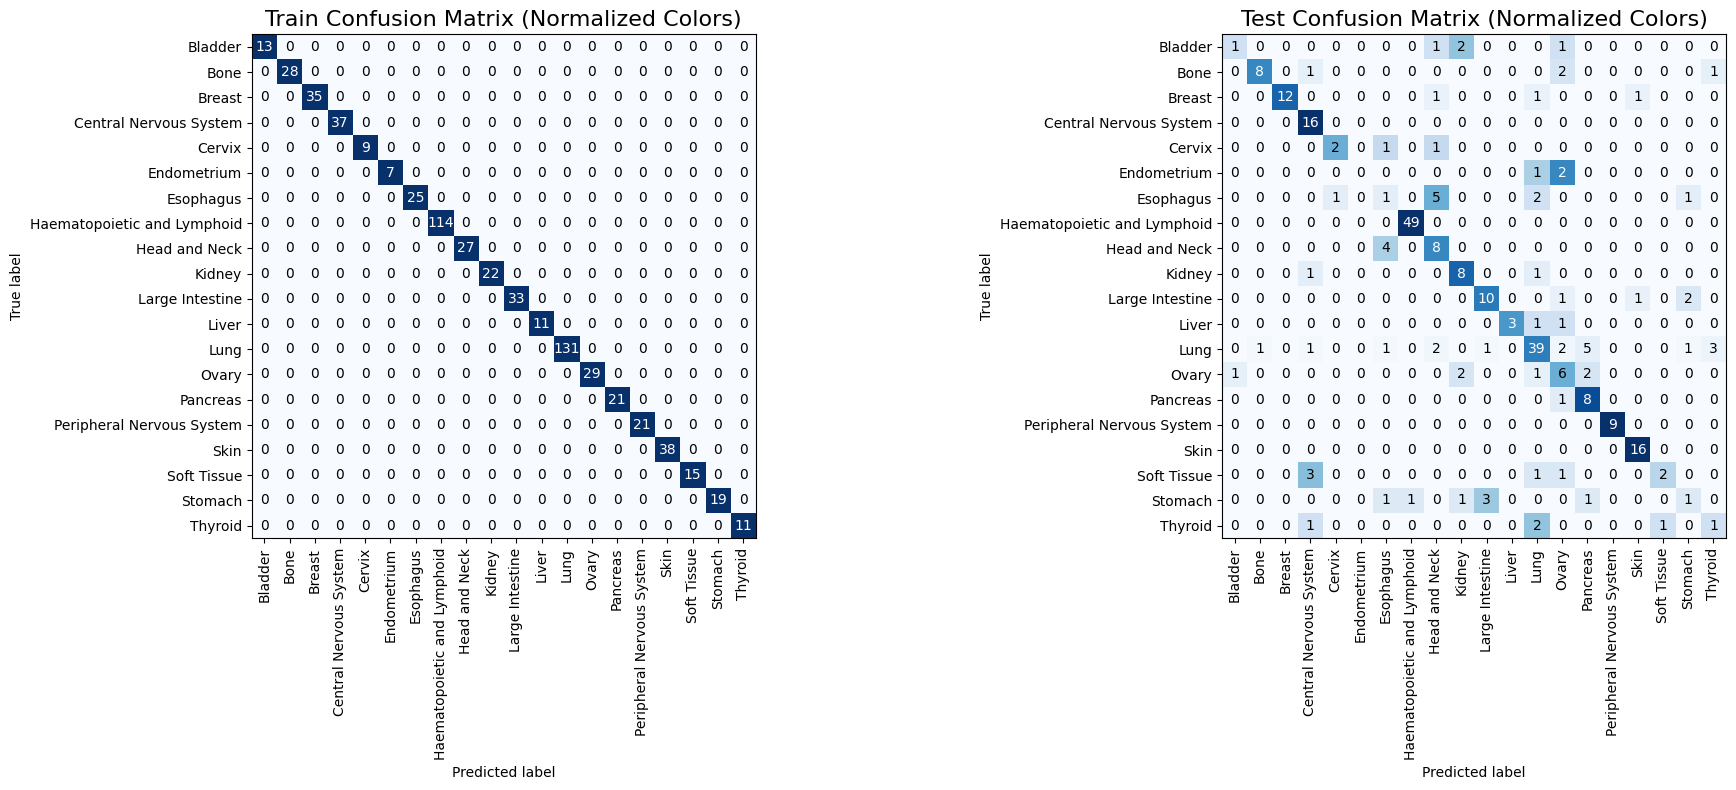

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# 1. Fit the best pipeline
best_pipe.fit(X_train, y_train_encoded, classify__sample_weight=sample_weights)

# 2. Predict on both sets
train_pred = best_pipe.predict(X_train)
test_pred = best_pipe.predict(X_test)

# 3. Generate Classification Reports
train_report = classification_report(y_train_encoded, train_pred, target_names=le.classes_)
test_report = classification_report(y_test_encoded, test_pred, target_names=le.classes_)
print("--- TRAIN CLASSIFICATION REPORT ---")
print(train_report)
print("\n--- TEST CLASSIFICATION REPORT ---")
print(test_report)

# 4. Results Dataframe summary
metrics = {
    "Metric": ["F1 Macro", "Accuracy", "Precision Macro", "Recall Macro"],
    "Train": [
        f1_score(y_train_encoded, train_pred, average='macro'),
        accuracy_score(y_train_encoded, train_pred),
        precision_score(y_train_encoded, train_pred, average='macro', zero_division=0),
        recall_score(y_train_encoded, train_pred, average='macro')
    ],
    "Test": [
        f1_score(y_test_encoded, test_pred, average='macro'),
        accuracy_score(y_test_encoded, test_pred),
        precision_score(y_test_encoded, test_pred, average='macro', zero_division=0),
        recall_score(y_test_encoded, test_pred, average='macro')
    ]
}
results_df = pd.DataFrame(metrics)
display(results_df)

# 5. Confusion Matrices (Precision Matrices with absolute numbers)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for i, (preds, labels, title) in enumerate([
    (train_pred, y_train_encoded, "Train Confusion Matrix (Normalized Colors)"),
    (test_pred, y_test_encoded, "Test Confusion Matrix (Normalized Colors)")
]):
    cm = confusion_matrix(labels, preds)
    # We use 'true' normalization for colors but display absolute counts using 'values_format'
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

    # Calculate normalization manually for coloring
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)

    im = axes[i].imshow(cm_normalized, interpolation='nearest', cmap='Blues')
    axes[i].set_title(title, fontsize=16)

    # Add absolute text annotations
    thresh = cm_normalized.max() / 2.
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            axes[i].text(col, row, format(cm[row, col], 'd'),
                         ha="center", va="center",
                         color="white" if cm_normalized[row, col] > thresh else "black")

    axes[i].set_xticks(range(len(le.classes_)))
    axes[i].set_xticklabels(le.classes_, rotation=90)
    axes[i].set_yticks(range(len(le.classes_)))
    axes[i].set_yticklabels(le.classes_)
    axes[i].set_ylabel('True label')
    axes[i].set_xlabel('Predicted label')

plt.tight_layout()
plt.show()

## **Performances:**

- Tuning improved performances from a macro F1 score of 0.50 to 0.58
- This was most likely associated with a change in the variable C (c=7.4 in the final model vs default c=1), altough both low and high C values improved performances.

We can also see that, even though the training data is dominated by the calsses "Haematopoietic and Lymphoid" and "Lung", the model correctly classifies even some less-represented classes, notably "Head and Neck" (f1: 0.53), "Kidneys" (f1: 0.7), "Pancreas"(f1: 0.64) and "Peripheral Nervous System" (f1: 1.00). However it struggles with very low-represented classes like Thyroid (f1: 0.2, n=5 in testing), Cervix (f1: 0.57, altough n=4 in the testing data), Endometrium (f1: 0, n=3 in testing data) and Liver (f1: 0.75, n=5 in testing data).

The very low F1 score for some of these tissue types is perhaps more likely due to a dangerous underepresentation the training data, compared to the dominating 2 tissue types. Altough it is also likely that the apparent bad performance for these groups is exacerbated by the underespresentation in testing dataset, as the overfit model would perhaps have better scores if simply there were more of that target class to predict in the data. For example Endometrium and Cervix have only 3 and 4 entries in the testing data respectively.


## **On overfitting:**

### My top performing models (all Logistic Regression models) with their hyperparameters, all resulted in overfitting, including the top performing model here analysed. Overfitting likely occurred as a consequence of the high dimensionality of the data with features >> samples. Any machine learning model would struggle wich this shape of data, but in my particular case, using a set l2 regularization for the Logistic Regression model likely contributed to overfitting as none of the variables could be dropped, forcing the model to overfit. Now in a previous version of this code I was using l1/l2 and various ratios of the two (elasticnet penalty) and the model still overfit. It is possible that by gridsearching all possible hyperparameter combinations of this model perhaps at least one would have not overfit, but this approach would have taken too muh computing time, especially for the scope of this project.

### Additionally, removing more variables than what was already done via filtering for columns containing less than 50% NaNs and removing highly correlated variables and/OR PCA, would have been deleterious for the downstream Go-Term analysis. PCA had the biggest potential to reduce dimensionality but at the price of sacrificing biological insight, so I decided to prioritise the downstream analysis. In an ideal scenarion I still would have not performed PCA, but I would have focused on GridSearch tuning all the four models tested initially (SVM, XGBoost, BaggingRandomForest and LogisticRegression).

---

## **Confusion matrices for the top performing model (LogisticRegression 0.58) and its best hyperparameters.**

- The model was fitted on training data and used to predict target (Tissue_type) using both training and testing data to asses overfitting

    - Train results: left
    - Test results: right
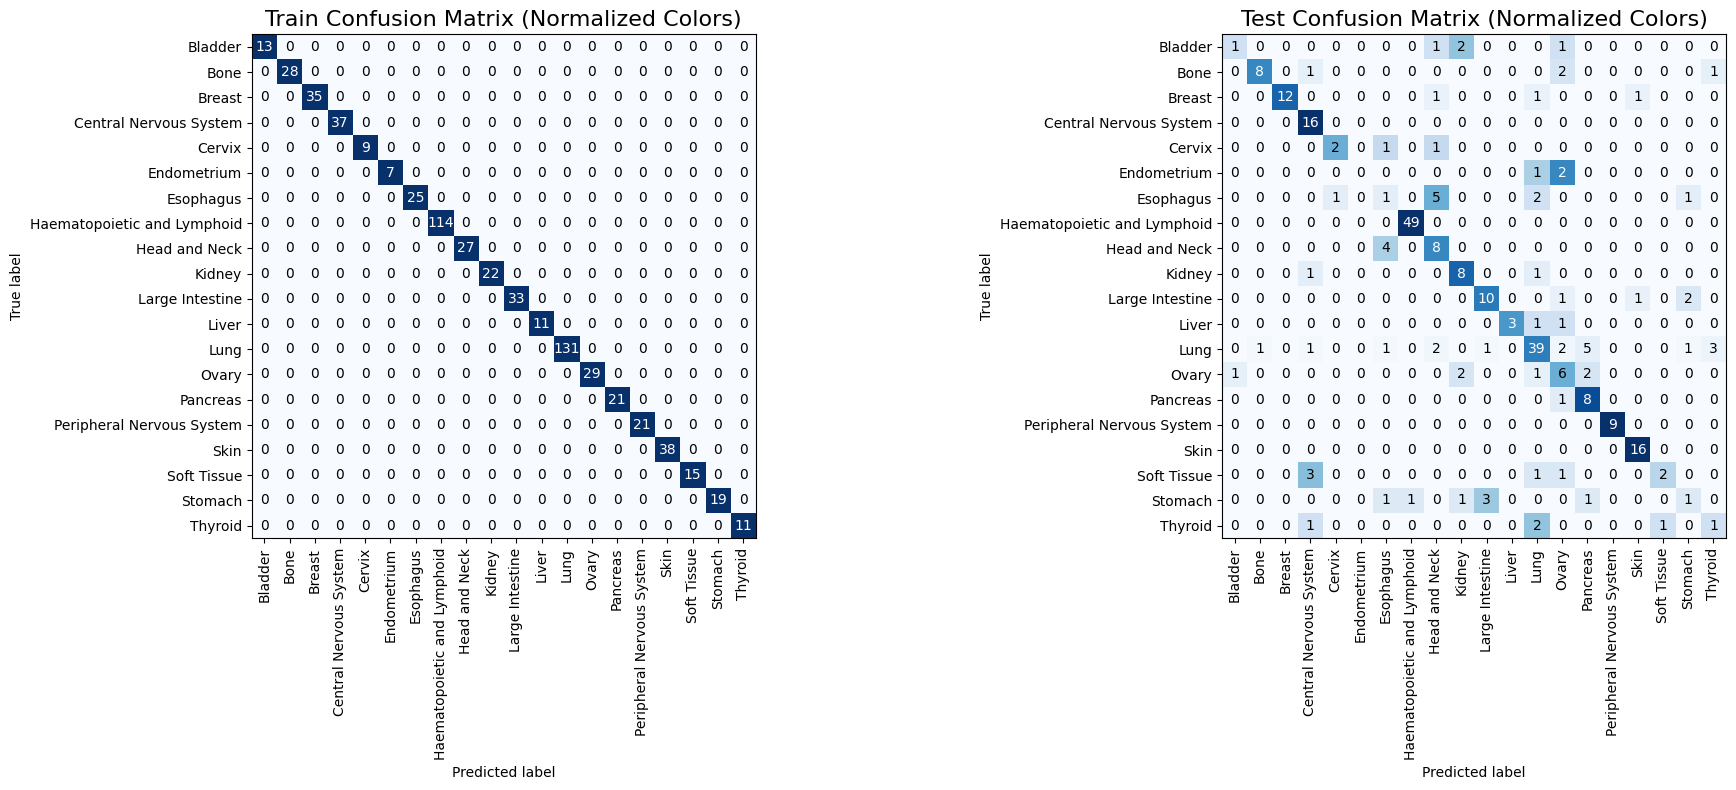
---

## We can clearly see that the top performing model (F1-macro 0.58) clearly overfit the training data

- This still resulted in somewhat acceptable performances (F1-macro ), suggesting that training and testing data are highly consistent and share similar data distributions. This could suggest data leakage somewhere in my pipeline, however I cannot think of where that may have occurred.


---


## I have decided to continue onto the feature analysis using this model instead of retuning, purely for time contraints reasons.

##I believe that another round of Grid Search CV tuning would be necessary to exhaustively search the best parameters and asses overfitting on each of them, specifically exploring further the different penalties type (pure l1/l2 or elastic net) and magnitutudes (C) as maybe overfitting can be prevented. This could be done but the time needed to run such an analysis is beyond the scope of this simple project...

##Even though none of my results suggest so, from the available literature I also believe that the LogisticRegression model simply is unsuitable for such high dimensionality data, especially considering the relatively few entries I posses. Extensively GridSearching the best hyperparameters for XGBoost or BaggingRandomForest il likely to yield even better results and/or prevent overfitting. However these models are computationally expensive and require long training times especially for the tuning process. This approach was simply not feasible for this project for time reasons, so I decided to settle on a more easily tunable model for this specific academic application...


---


# 9 - Feature Importance Analysis

1. Extract feature importance from the top performing model with top performing hyperparameter settings

2. Perform GO term enrichment analysis on the top 500 most important features according to the model, comparing them to the GO terms of the proteins from the whole dataset.

## Feature Importance Analysis:

### **Go term Enrichment Analysis:**


GO terms attributed to the 500 most important proteins, according to the Logistic Regression model, in correctly classifying the tissue of origin of cancer cells from their proteomic data, were compared to the GO terms of the whole dataset used for this project.

To be exact, the background GO terms (baseline compared to which I want to see if my GO terms are enriched), were extracted from the proteins contained within the dataset after processing and right before splitting, so they represent the GO terms of all the proteins that the model had access to. This was deliberately chosen over the ful dataset prior to dropping of certain columns (proteins), as the model would have not had access to such features and it may have skewed the enrichment analysis.

Additionally given that the majority of the dropped proteins were either due to missing values or high correlation, their attributed GO terms would have been highly specific and rare (in the case of high missing values proteins) or enriched (high correlation between proteins likely means similar functions and so similar Go terms).



In [ ]:
import ast
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Extract the classifier from the previously-defined pipeline
best_clf = best_pipe.named_steps['classify']

# Calculate importance based on the mean absolute value of coefficients
importance = np.mean(np.abs(best_clf.coef_), axis=0)

# FIX: The full preprocessor returns a numpy array which lacks .columns
# We first get the features remaining after the custom 'drop_correlated' step
# Since 'standardise' doesn't change the number or order of features, these names are correct
preprocessor_partial = Pipeline(steps=[('standardise', best_pipe.named_steps['standardise']),
                                       ('drop_correlated', best_pipe.named_steps['drop_correlated'])])

# We transform a small sample and use the custom transformer's logic to see which columns were kept
# The DropCorrelatedFeatures transformer handles DataFrame input and returns columns if used correctly
X_dropped = best_pipe.named_steps['drop_correlated'].transform(X_train[:1])
features_used = X_dropped.columns

feature_importance_df = pd.DataFrame({
    'Protein': features_used,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

# Calculate metrics for the report
print(f"{10*'='} Final Model Results: {10*'='}")
print(test_report)
print(20*"=")
print(20*"=")
print(f"\n{10*'='} Top 10 Important Features: {10*'='}")
display(feature_importance_df.head(10))

========== Final Model Results: ==========
                             precision    recall  f1-score   support

                    Bladder       0.50      0.20      0.29         5
                       Bone       0.89      0.67      0.76        12
                     Breast       1.00      0.80      0.89        15
     Central Nervous System       0.70      1.00      0.82        16
                     Cervix       0.67      0.50      0.57         4
                Endometrium       0.00      0.00      0.00         3
                  Esophagus       0.12      0.10      0.11        10
Haematopoietic and Lymphoid       0.98      1.00      0.99        49
              Head and Neck       0.44      0.67      0.53        12
                     Kidney       0.62      0.80      0.70        10
            Large Intestine       0.71      0.71      0.71        14
                      Liver       1.00      0.60      0.75         5
                       Lung       0.80      0.70      0.74 

,Protein,Importance
2237,P54652;HSP72_HUMAN,0.021697
1214,P15121;ALDR_HUMAN,0.021041
100,P80723;BASP1_HUMAN,0.020545
2332,P07195;LDHB_HUMAN,0.020468
1511,Q6WKZ4;RFIP1_HUMAN,0.020278
2754,P09936;UCHL1_HUMAN,0.019842
1989,Q8TEM1;PO210_HUMAN,0.019634
693,Q8N0X7;SPART_HUMAN,0.019348
2470,Q16666;IF16_HUMAN,0.019056
2418,Q01469;FABP5_HUMAN,0.018485


In [ ]:
#extract the top 500 more important proteins
top_500_proteins = feature_importance_df.iloc[:500]

print("Top 500 important features according to top performing Liogstic Regression Model:")
display(top_500_proteins.head(10))
print(top_500_proteins.shape)
print(f"Total importance of the top 500 features: {top_500_proteins["Importance"].sum()}")


Top 500 important features according to top performing Liogstic Regression Model:


,Protein,Importance
2237,P54652;HSP72_HUMAN,0.021697
1214,P15121;ALDR_HUMAN,0.021041
100,P80723;BASP1_HUMAN,0.020545
2332,P07195;LDHB_HUMAN,0.020468
1511,Q6WKZ4;RFIP1_HUMAN,0.020278
2754,P09936;UCHL1_HUMAN,0.019842
1989,Q8TEM1;PO210_HUMAN,0.019634
693,Q8N0X7;SPART_HUMAN,0.019348
2470,Q16666;IF16_HUMAN,0.019056
2418,Q01469;FABP5_HUMAN,0.018485


(500, 2)
Total importance of the top 500 features: 6.960290257331485


In [ ]:

# GOATools and related imports
!pip install goatools
from goatools.obo_parser import GODag
from goatools.goea.go_enrichment_ns import GOEnrichmentStudyNS
from goatools.associations import read_gaf
from goatools.go_enrichment import GOEnrichmentStudy
import os
import requests
import gzip
import shutil



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 15.6 MB/s eta 0:00:00


In [ ]:

# ==========================================
# 1. SET UP PATHS & DIRECTORIES
# ==========================================
#drive_path = "/content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO"

#UNCOMMENT THIS LINE IF WANTING TO ACTUALLY RUN THIS IN THE STUDENT FOLDER,
# It will create a new folder in the student_project/data directory,
# download two files, one being huge (roiughly 1.5Gb compressed, then unpacks it)
# use these files in the following analysis
drive_path = "/content/drive/MyDrive/GO"
os.makedirs(drive_path, exist_ok=True)

obo_file = os.path.join(drive_path, "go-basic.obo")
gaf_gz = os.path.join(drive_path, "goa_human.gaf.gz")
gaf_file = os.path.join(drive_path, "goa_human.gaf")

# ==========================================
# 2. DOWNLOAD NATIVE GO/UNIPROT MAPPINGS
# ==========================================
def download_file(url, filepath):
    if not os.path.exists(filepath):
        print(f"Downloading {url}...")
        headers = {'User-Agent': 'Mozilla/5.0'}
        response = requests.get(url, headers=headers, stream=True)
        response.raise_for_status()
        with open(filepath, 'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
    else:
        print(f"Found {filepath} locally in Drive.")

print("Checking databases...")
download_file("http://current.geneontology.org/ontology/go-basic.obo", obo_file)
download_file("https://current.geneontology.org/annotations/gaf/HUMAN-uniprot.gaf.gz", gaf_gz)

# Self-healing unzipping block for the GAF file as I had issues downloading it (my wifi is terrible)
if not os.path.exists(gaf_file):
    print("Extracting GAF file...")
    try:
        with gzip.open(gaf_gz, 'rb') as f_in:
            with open(gaf_file, 'wb') as f_out:
                shutil.copyfileobj(f_in, f_out)
    except (EOFError, OSError):
        print("Corrupted .gz file. Re-downloading...")
        os.remove(gaf_gz)
        download_file("http://current.geneontology.org/annotations/goa_human.gaf.gz", gaf_gz)
        with gzip.open(gaf_gz, 'rb') as f_in:
            with open(gaf_file, 'wb') as f_out:
                shutil.copyfileobj(f_in, f_out)

# ==========================================
# 3. DIRECT MAPPING & ID EXTRACTION
# ==========================================
print("Loading direct UniProt-to-GO-Terms associations...")
# This reads the GAF and creates a UniProtID -> GO_IDs mapping directly!
assoc_human = read_gaf(gaf_file)

# Isolate the numeric columns from your background dataframe
#protein_columns = proteomics_averaged_df.select_dtypes(include=['number']).columns
protein_columns = df.select_dtypes(include=['number']).columns

# Extract pure UniProt IDs (the part before the semicolon)
background_ids = [col.split(';')[0] for col in protein_columns]

# Extract pure UniProt IDs for your test set
# Iterates through the Protein column, every row is converted into a string and split at the ; delimiter
#At index 0 of the resulting "list" is the protein UniprotID
study_ids = [row.split(';')[0] for row in top_500_proteins['Protein']]

# Filter the association map down to just the proteins present in your background population
assoc_map = {uid: assoc_human[uid] for uid in background_ids if uid in assoc_human}

print(30*"=")
print(f"\n--- Mapping Summary ---")
print(f"Total proteins in background dataframe: {len(background_ids)}")
print(f"Successfully mapped to GO terms: {len(assoc_map)} ({round(len(assoc_map)/len(background_ids)*100, 1)}%)")

# ==========================================
# 4. RUN GO ENRICHMENT ANALYSIS
# ==========================================
godag = GODag(obo_file)

print(f"\nRunning enrichment on {len(study_ids)} study proteins against {len(background_ids)} background proteins...")
go_study = GOEnrichmentStudy(
    background_ids,
    assoc_map,
    godag,
    propagate_counts=True,
    alpha=0.05,
    methods=['fdr_bh']
)

results = go_study.run_study(study_ids)
sig_results = [r for r in results if r.p_fdr_bh < 0.05]

# ==========================================
# 5. GENERATE CLEAN RESULTS TABLE
# ==========================================
enrichment_results = []
for r in sig_results:
    study_ratio = r.ratio_in_study[0] / r.ratio_in_study[1]
    pop_ratio = r.ratio_in_pop[0] / r.ratio_in_pop[1]
    fold_enrichment = study_ratio / pop_ratio if pop_ratio > 0 else 0

    enrichment_results.append({
        'GO_ID': r.GO,
        'Term Name': r.name,
        'Category': r.NS,
        'Fold_Enrichment': round(fold_enrichment, 2),
        'Study_Count': r.ratio_in_study[0],
        'Study_Total': r.ratio_in_study[1],
        'Background_Count': r.ratio_in_pop[0],
        'Background_Total': r.ratio_in_pop[1],
        'p-value': r.p_uncorrected,
        'FDR (q-value)': r.p_fdr_bh
    })

enrich_df = pd.DataFrame(enrichment_results)
#enrich_df.to_csv(os.path.join("/content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO", "go_enrichment_analysis.csv"))
if not enrich_df.empty:
    enrich_df = enrich_df.sort_values(['FDR (q-value)', 'Fold_Enrichment'], ascending=[True, False]).reset_index(drop=True)
    print(f"\nSuccess! Found {len(enrich_df)} Significantly Enriched GO Terms (FDR < 0.05):")
    display(enrich_df)
else:
    print("\nNo terms reached statistical significance (FDR < 0.05) even with direct mapping.")

Checking databases...
Found /content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO/go-basic.obo locally in Drive.
Found /content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO/goa_human.gaf.gz locally in Drive.
Loading direct UniProt-to-GO-Terms associations...
HMS:0:00:35.879376 906,445 annotations READ: /content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO/goa_human.gaf 
31530 IDs in loaded association branch, BP

--- Mapping Summary ---
Total proteins in background dataframe: 3389
Successfully mapped to GO terms: 3252 (96.0%)
/content/drive/MyDrive/grelli_ML_project_data/20260713_1741_output_data/GO/go-basic.obo: fmt(1.2) rel(2026-06-15) 41,535 Terms

Running enrichment on 500 study proteins against 3389 background proteins...

Load  Ontology Enrichment Analysis ...
Propagating term counts 4 GO IDs NOT FOUND IN ASSOCIATION: GO:0070973 GO:0032527 GO:0070863 GO:0010142
up: is_a
 96%  3,252 of  3,389 population items found in 

,GO_ID,Term Name,Category,Fold_Enrichment,Study_Count,Study_Total,Background_Count,Background_Total,p-value,FDR (q-value)
0,GO:0051240,positive regulation of multicellular organisma...,BP,2.09,79,500,256,3389,6.523560e-12,5.463482e-08
1,GO:0006396,RNA processing,BP,0.38,25,500,444,3389,2.495826e-10,1.045127e-06
2,GO:0016072,rRNA metabolic process,BP,0.08,2,500,172,3389,6.440218e-10,1.797894e-06
3,GO:0006364,rRNA processing,BP,0.05,1,500,150,3389,9.855506e-10,2.063496e-06
4,GO:0051239,regulation of multicellular organismal process,BP,1.69,108,500,433,3389,1.792493e-09,3.002426e-06
...,...,...,...,...,...,...,...,...,...,...
128,GO:0000375,"RNA splicing, via transesterification reactions",BP,0.39,9,500,155,3389,6.761671e-04,4.389845e-02
129,GO:0007411,axon guidance,BP,3.21,9,500,19,3389,7.149879e-04,4.536381e-02
130,GO:0097485,neuron projection guidance,BP,3.21,9,500,19,3389,7.149879e-04,4.536381e-02
131,GO:0006869,lipid transport,BP,2.31,16,500,47,3389,7.042748e-04,4.536381e-02


In [ ]:
##SAVE THE DATA##
enrich_df.to_csv(os.path.join("/content/drive/MyDrive/data/GO", "go_enrichment_analysis.csv"))

#Define an enriched and depleted category for the resulting data
enriched_df = enrich_df[enrich_df['Fold_Enrichment'] > 1.00]
depleted_df = enrich_df[enrich_df['Fold_Enrichment'] < 1.00]

## GO Analysis Plots:

- The GO-terms associated with the top 500 most important proteins (features) for predicting the tissue-type of cancer cells from their proteome, according to the top performing model, were used for the TESTING POPULATION

- The background population was all the GO-terms in the whole dataframe prior to transformations (scaling and dropping of correlated variables) - deliberately chosen as it fundamentally is a background of cancer-associated GO-terms for all the cancer cell types in this dataset

- Frequency of GO-terms in the testing population is compared to frequency in background population to calculate FOLD ENRICHMENT

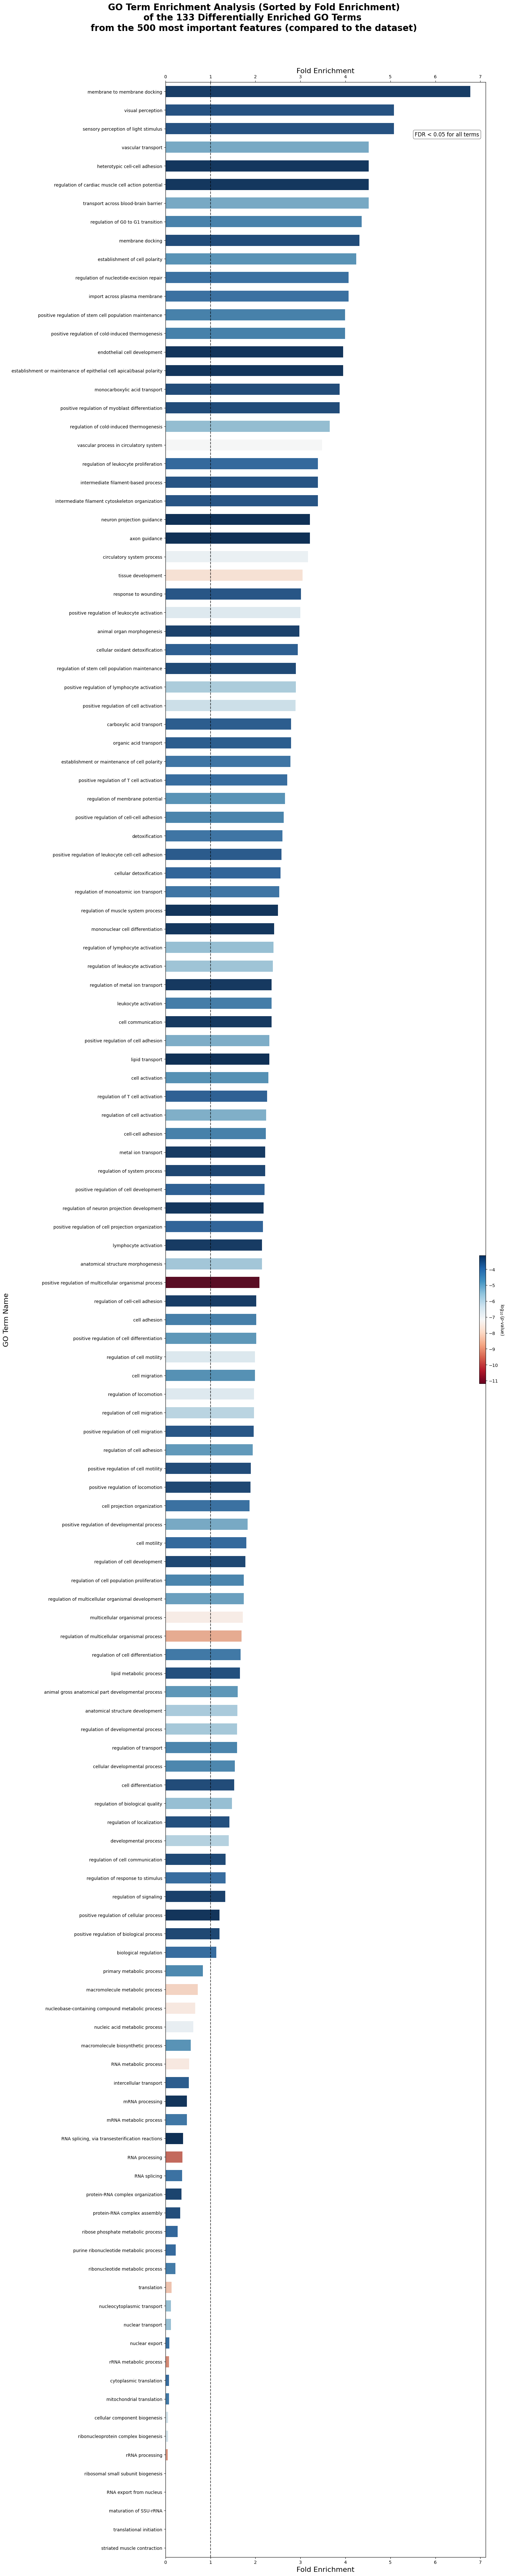

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Sort the DataFrame by Fold_Enrichment in descending order (highest at top)
enrich_df_sorted = enrich_df.sort_values(by='Fold_Enrichment', ascending=False).reset_index(drop=True)

# 2. Create log10(p-value) for coloring
enrich_df_sorted['log10_p'] = np.log10(enrich_df_sorted['p-value'])

# Normalize the log values for the colormap
norm = plt.Normalize(enrich_df_sorted['log10_p'].min(), enrich_df_sorted['log10_p'].max())
# Using 'RdBu' maps the lower end (min) to Red and higher end (max) to Blue
cmap = plt.cm.RdBu
colors = [cmap(norm(val)) for val in enrich_df_sorted['log10_p']]

# 3. Setup the figure - Increased width to 16 for a more horizontal look
fig, ax1 = plt.subplots(figsize=(16, max(12, len(enrich_df_sorted) * 0.6)))

# Plot the horizontal bar chart - Added 'width' to make bars thinner
sns.barplot(
    x='Fold_Enrichment',
    y='Term Name',
    data=enrich_df_sorted,
    hue='Term Name',
    palette=colors,
    legend=False,
    ax=ax1,
    width=0.6
)

# 4. Add a dotted vertical line at x=1
ax1.axvline(x=1, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

# 5. Dual X-Axis (Bottom and Top) - Increased fontsize for labels
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xlabel('Fold Enrichment', fontsize=16)
ax1.set_xlabel('Fold Enrichment', fontsize=16)
ax1.set_ylabel('GO Term Name', fontsize=16)

# 6. Add FDR < 0.05 annotation near the top right
# Fixed: removed 'statistics' which caused the AttributeError
ax1.text(0.98, 0.98, 'FDR < 0.05 for all terms',
         transform=ax1.transAxes,
         fontsize=12,
         verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

# 7. Create a colorbar for log10(p-value) reference
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label('$\\log_{10}(p\\text{-value})$', rotation=270, labelpad=15)

# Updated title to automatically take the number of GO terms
title_text = (f'GO Term Enrichment Analysis (Sorted by Fold Enrichment)\nof the {len(enrich_df_sorted)} Differentially Enriched GO Terms \nfrom the 500 most important features (compared to the dataset)')
plt.suptitle(title_text, fontsize=20, y=1.01, fontweight="bold")

plt.tight_layout()
plt.show()

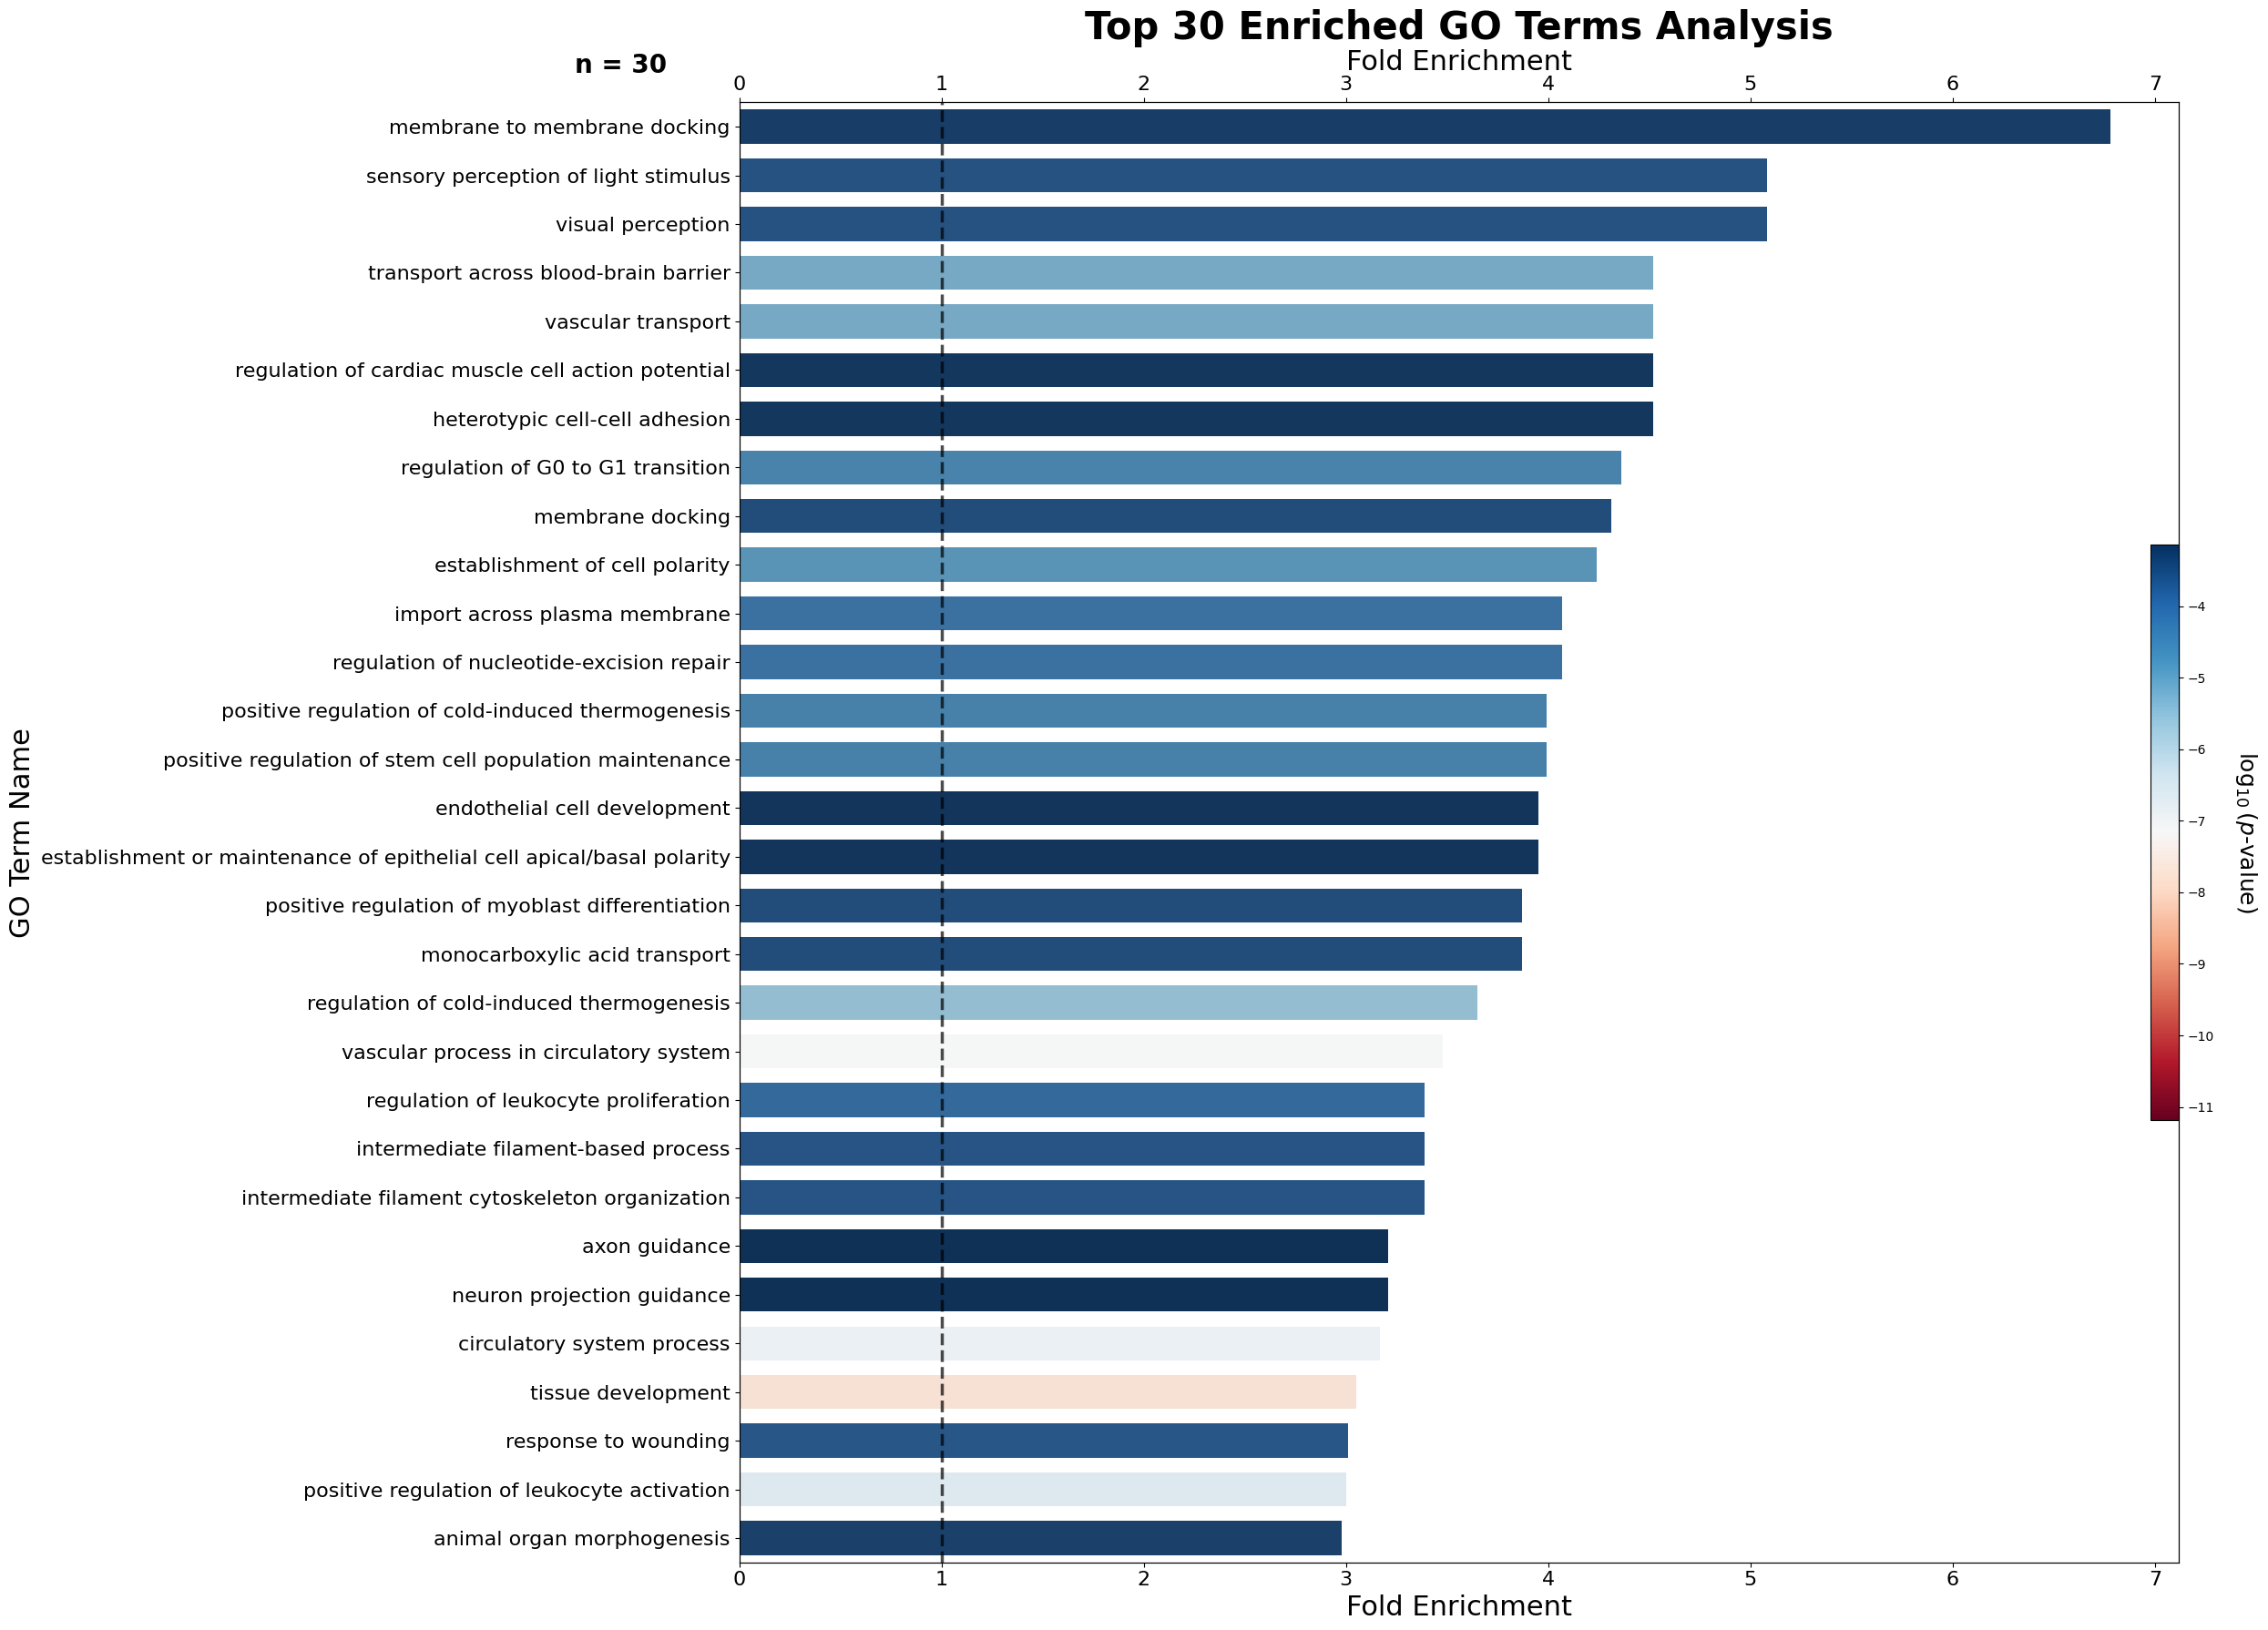

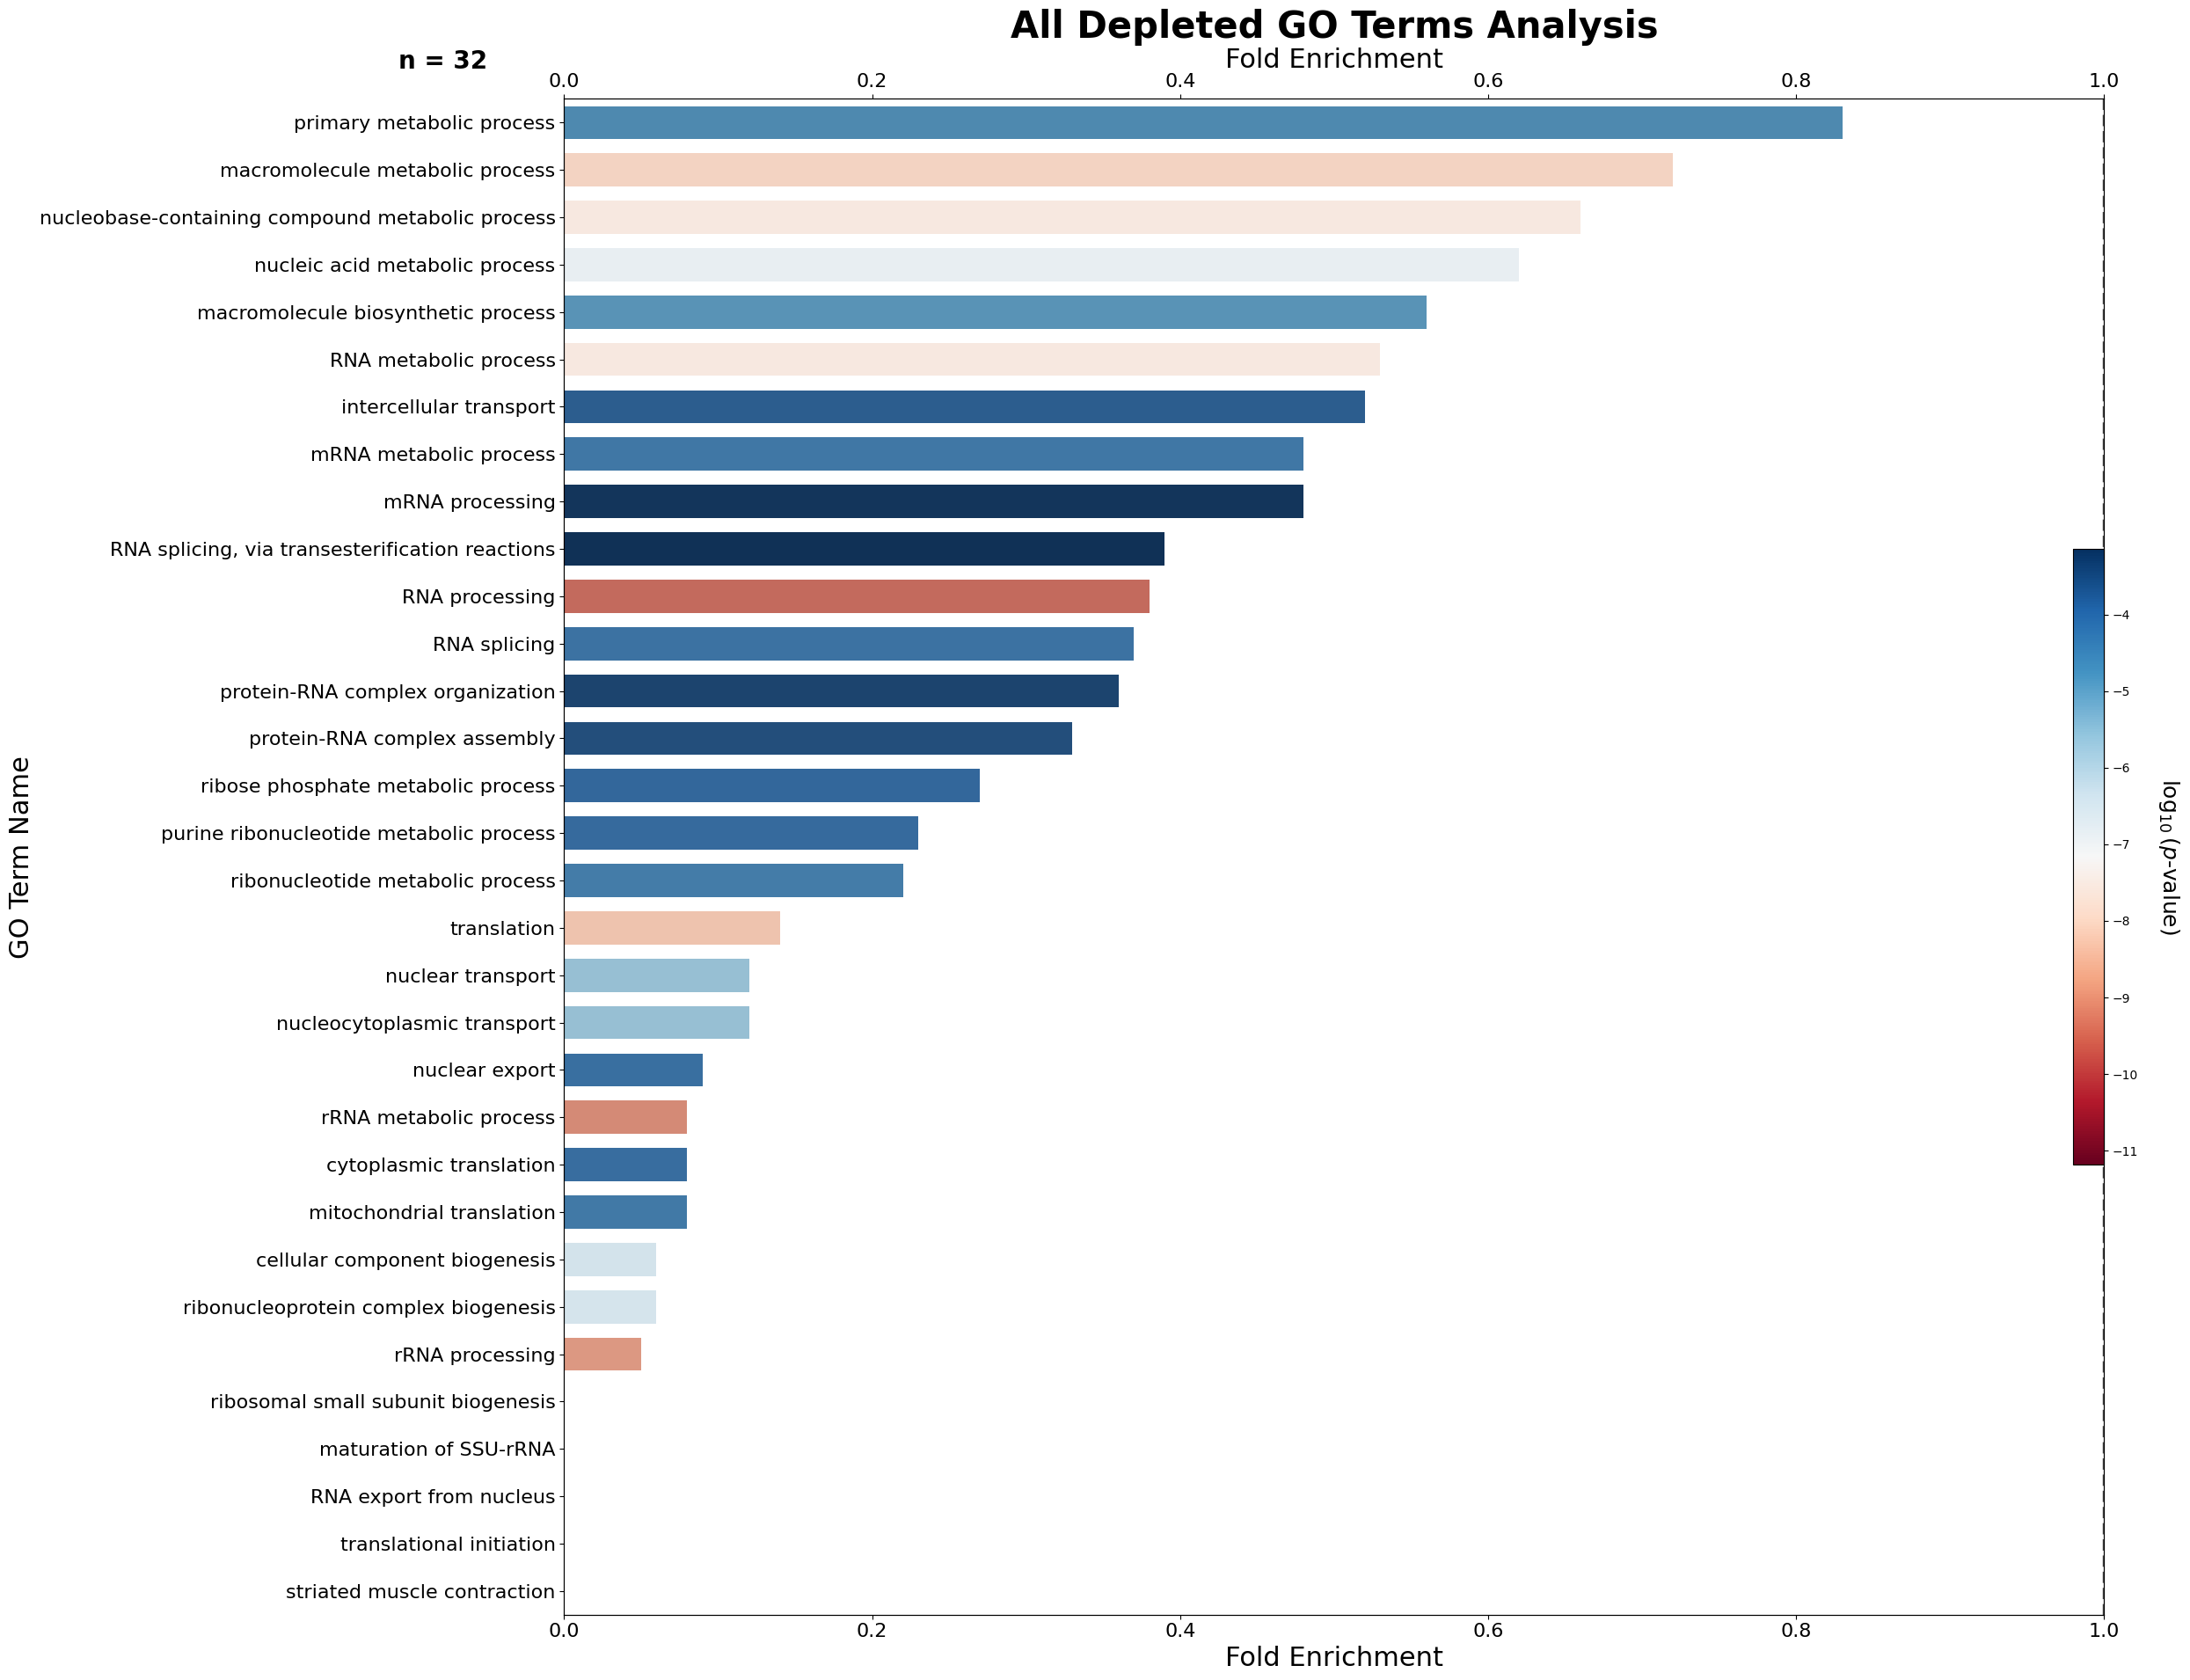

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Prepare Data
enrich_df['log10_p'] = np.log10(enrich_df['p-value'])
# Only take top 30 for Enriched as requested; keeping logic for Depleted as well
enriched_sorted = enriched_df.sort_values(by='Fold_Enrichment', ascending=False).head(30).copy().reset_index(drop=True)
depleted_sorted = depleted_df.sort_values(by='Fold_Enrichment', ascending=False).copy().reset_index(drop=True)

# Define consistent normalization and colormap
norm = plt.Normalize(enrich_df['log10_p'].min(), enrich_df['log10_p'].max())
cmap = plt.cm.RdBu

def generate_go_plot(df, title_suffix, is_enriched=True):
    if df.empty:
        print(f"No {title_suffix} terms found.")
        return

    # Calculate local log10_p if missing
    if 'log10_p' not in df.columns:
        df['log10_p'] = np.log10(df['p-value'])

    # Dynamic height based on number of terms (0.6 inches per bar to ensure labels fit)
    plot_height = max(8, len(df) * 0.6)

    fig, ax1 = plt.subplots(figsize=(25, plot_height))

    colors = [cmap(norm(val)) for val in df['log10_p']]

    sns.barplot(
        x='Fold_Enrichment',
        y='Term Name',
        data=df,
        hue='Term Name',
        palette=colors,
        legend=False,
        ax=ax1,
        width=0.7
    )

    # Setup dual x-axis
    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())

    ax1.set_title(f'{title_suffix} GO Terms Analysis', fontsize=30, fontweight='bold', pad=50)
    ax1.set_xlabel('Fold Enrichment', fontsize=22)
    ax2.set_xlabel('Fold Enrichment', fontsize=22)
    ax1.set_ylabel('GO Term Name', fontsize=22)
    ax1.tick_params(axis='both', labelsize=16)
    ax2.tick_params(axis='x', labelsize=16)

    # Add n count annotation near y-axis
    ax1.text(-0.05, 1.02, f'n = {len(df)}', transform=ax1.transAxes, fontsize=20, fontweight='bold', color='black', ha='right')

    # Dotted line at x=1
    ax1.axvline(x=1, color='black', linestyle='--', linewidth=2.5, alpha=0.7)

    if not is_enriched:
        ax1.set_xlim(right=1)
        ax2.set_xlim(right=1)

    # Add individual colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax1, orientation='vertical', fraction=0.02, pad=0.02)
    cbar.set_label(r'$\log_{10}(p\text{-value})$', rotation=270, labelpad=35, fontsize=18)

    plt.tight_layout()
    plt.show()

# 2. Iterate through both datasets using a loop
plot_configs = [
    (enriched_sorted, "Top 30 Enriched", True),
    (depleted_sorted, "All Depleted", False)
]

for df_subset, label, enriched_flag in plot_configs:
    generate_go_plot(df_subset, label, is_enriched=enriched_flag)

##

#### **1. The Data Sources**
I had to download 2 main files for this analysis:
*   **`go-basic.obo`**: This is the structured dictionary of the Gene Ontology. It contains the hierarchy of all biological GO-terms and how they are related to each other.
*   **`HUMAN-uniprot.gaf.gz`**: This is a massive mapping file provided by NCBI. Which contains mapping to directly convert UniProt protein IDs to GO terms.

#### **2. Protein-to-GO Mapping Strategy**
Since my data uses a format like `Accession;GeneName` (e.g., `P54652;HSP72_HUMAN`), we need a two-step mapping logic:
1.  **For the Study Set (Top 500):** I used the UniProt conversion dictionary to convert every UniProt ID from this dataset into keys of a dictionary associated to all their specific GO terms.
2.  **For the Background:** Did the same exact thing but on all the proteins of the dataset used (3000 or so proteins)

#### **3. Defining 'Study Set' vs. 'Background Population'**
*   **The Study Set (n=500):** These are the top features (proteins) my model prioritized as most important for predicting the tissue of origin of cancer cells.
*   **The Background Population (n=3,266):** Instead of using every known human protein, I used **my processed dataset** (containing proteins not particularly correlated with each other, and present in more than 50% of cancer cell types) as the background to compare and determine whether the Go terms in my 500 important proteins are more present than this "normale background" or nor.
    *   I did not want to use healthy human GO terms (all the GO terms in the mapping file) as cancer cells have abnormal phenotypes, I was more interested in knowing whether something in this common abnormal phenotype (more than 50% abbundance across all cell types) was unique based on the tissue of origin of these cancer cells...

#### **4. Statistics: Fisher’s Exact Test**
I used the `goatools` library to perform a **Fisher’s Exact Test**. It calculates a p-value by asking: *'Is the frequency of GO Term X in my top 100 list significantly higher than its frequency in the overall background?'*

Because we are testing thousands of terms at once, I selected Only terms with an **FDR < 0.05** are considered truly enriched, meaning there is less than a 5% chance the observation is a false positive.

#10. Conclusion

##1.  Dataset selection and description
I selected a large proteomics dataset containing over 6000 proteins identified across 949 cancer cell lines.


---


##2.  Preprocessing before the split
Preprocessing was done prior or simultaneously to EDA as the data is very dense and not prone to be easily displayed.
- First I assembled the proper dataset I would be using by adding Tissue_type and Cell_line as variables.
- Then I replaced all missing values with 0. From the article I got the data from, this was regarded as suitable. In the case of this dataset 0 would represent a theoretical mean protein abundance across all cell lines and substituting it prior to splitting does not cause significant data leakage as this imputation method is not informed by the data in the same way that other methods are (like substituting NaNs for the mean etc.)
- Crucially I dropped all protein columns containing more than 50% NaNs to find non-cell type/lineage specific features of importance. Also to avoid statistical noise I avoided imputation of many data points. This allowed me to remove 3303 protein columns and vastly "simplify" the data.

- These step are not incorporated into the scikit Pipeline as they are performed to prepare the actual initial dataset to analyse. Also I wanted to avoid creating too many custom transformers for the pipeline.

---


##3.  Exploratory Data Analysis (EDA)
This step was useful in highligthing class imbalances in my data, in fact some classes of the target variable (tissue type) had hundreds of entries while some had less than 10.
- I decided to remove all entries from tissue types containing less than 10 entries (cell lines).
- Unfortunately the data is still heavily imbalanced with the tissues "Lung" and "Haematopoietic and Lymphoid" dominating the data. This will be left as is because any imputation or resampling method would either fill the dataset with imputed values (which I am trying to avoid) or drastically decrease the number of entries (given the already high feature to samples ration, I wanted to avoid this)

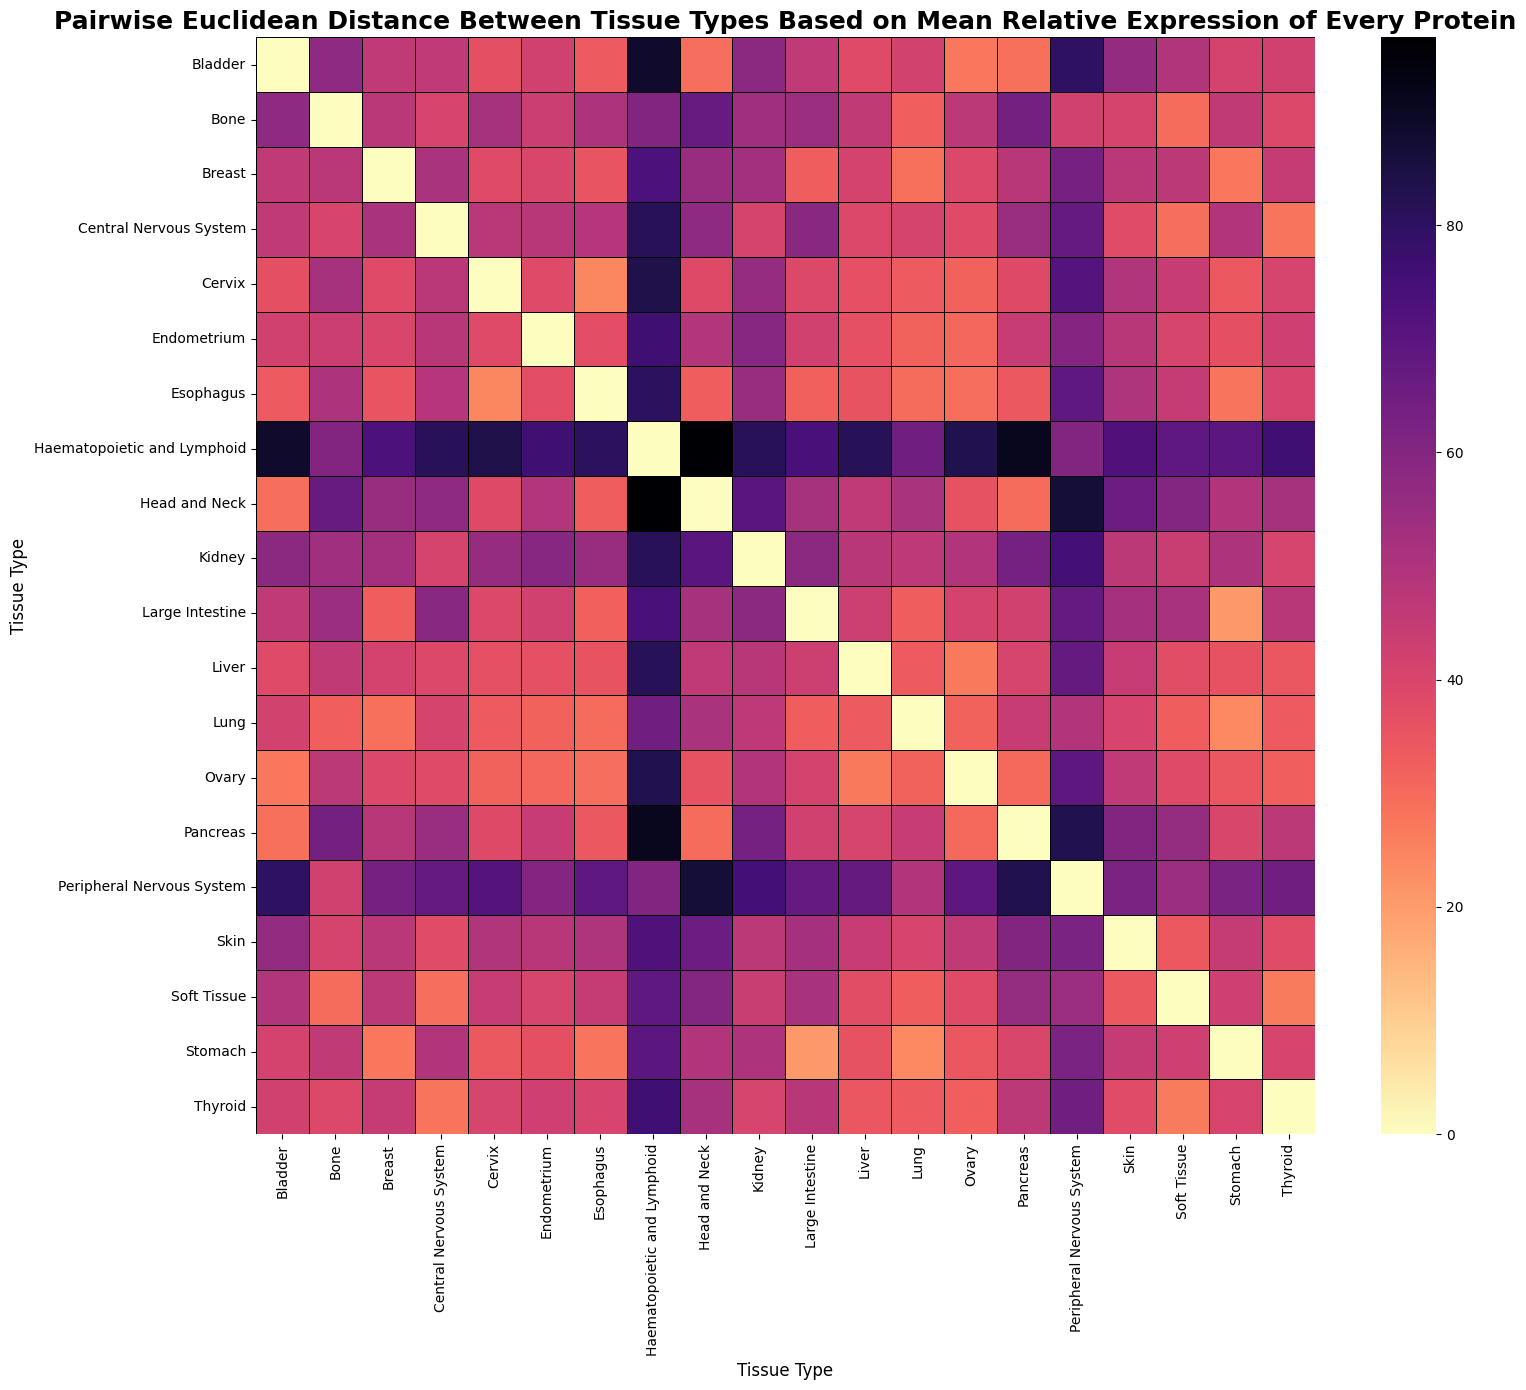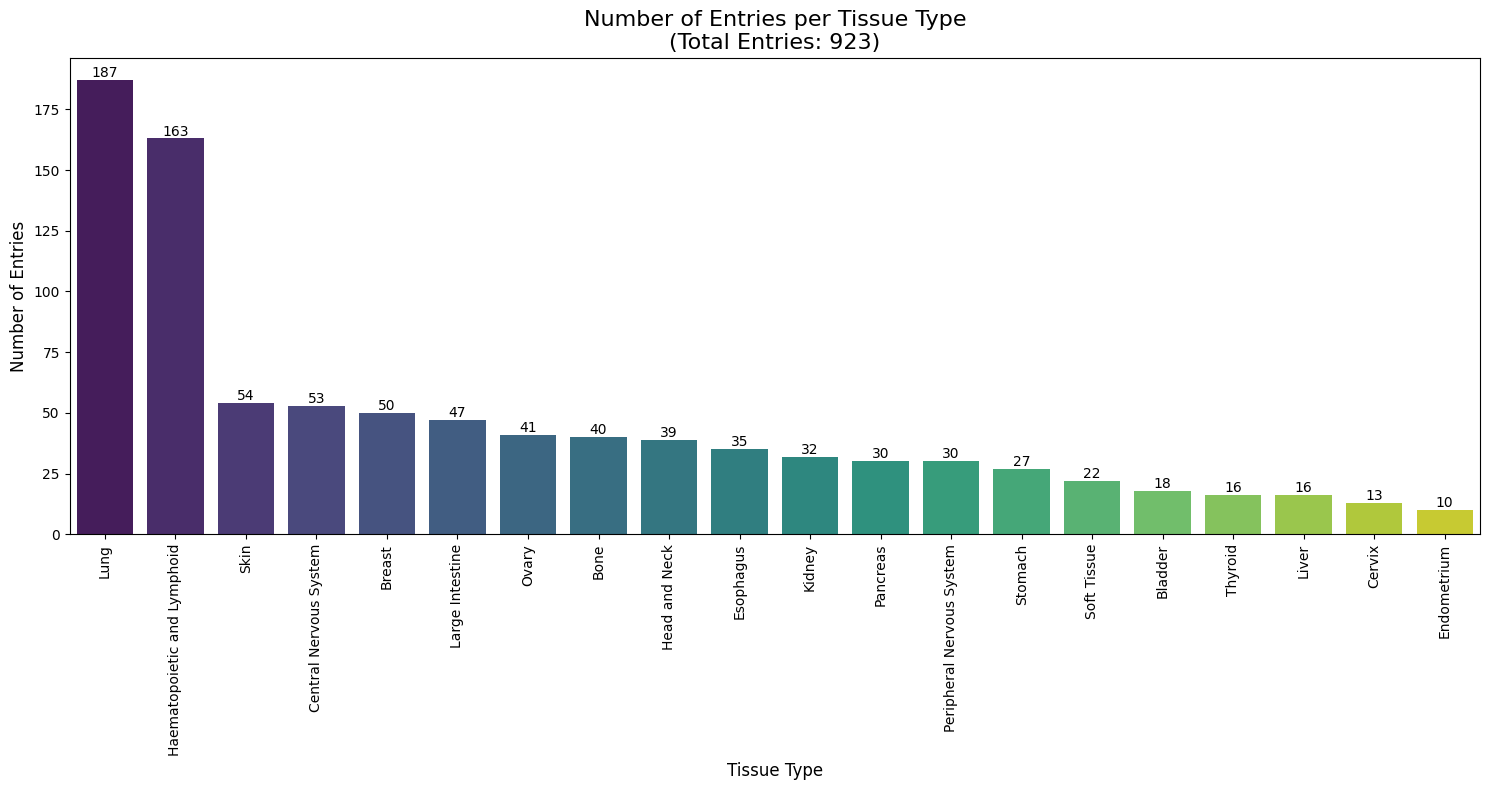
---
###4.  Dataset split
- Data was split in a ratio of 30% test, 70% train
- Stratified parameter was set to True to try to maintain somewhat representative sampling of even the smaller classes.
---
###5.  Preprocessing after the split
#### The preprocessing pipeline encompasses:
- Standardization of data (Z-score)
- Principal Component Analysis: performed to attempt to reduce the complexity of the data, this reduced the number of variables from 3266 to 433 Principal Components which expolained 95% of the variance in the dataset:
- Removal of highly correlated variables (proteins) using a custom scikit transformer. In hindsight this may not have been a great idea as protein regulatory networks are strong phenotypic predictors and could have aided in model performance or even discovery of important GO terms.
---
###6.  Model selection and comparison
- First round of cross validation of 4 models to select the most promising: Logistic Regression, XGBoost Classifier, Bagging Random Forest and SVM Classifier
- Logistic Regression won (macro F1 score 0.5 - sd 0.05). XBoost Classifier was second (macro F1 score 0.44 - sd 0.03).
- By no means these are great, but the results from Logistic Regressor were promising altough overfitting was always troubling.
---
###7.  Hyperparameter tuning
- Performed Randomised Cross Validation parameter search (30 iterations, 3 K-Folds so 90 fits total) on the whole pipeline, with the only parameters provided in the grid to test, being parameters and hyperparameters for the last step of the pipeline, the classifier. This allowed me to test various LogsticRegression and XGboost hyperparameters directly in my pipeline.
- LogisticRegression dominated the top performing positions in the ranking, so XGBoost was not included in further analysis, altough the LogisticRegression model overfit in all its top 3 best configurations of hyperparameters.
8.  Final evaluation and overfitting/underfitting check
- Logistic Regression algorithm increased in performances: Pre-tune macroF1: 0.5, Post-tune macroF1: 0.58.
- Unfortunately the model overfit the training data

- Overfitting likely occurred due to a combination of high dimensionality data and unsuitable hyerparameters (specifically the penalty type, l2 was chosen while full l1 may have prevented overfitting).
- Further tuning was not performed due to time limitations alone.
- I would however attempt tuning of the XGBoost Classifier further and asses over/underfitting of that, as according to other sources it could be more suitable for proteomics data.
---
###9.  Feature importance analysis
- The top 500 most important features (proteins) to the Logistic Regression model (according to the mean of the coefficients of said variable across the classes) were selected for further analysis.
- The GO-terms associated with hese 500 important proteins were used as the test for enrichment analysis against a background of GO terms from the whole dataset prior to the standardisation step and dropping of highly correlated proteins.
- Interestingly the model seemed to deem important biological processes that could in theory broadly classify various tissue functions like: membrane to membrane docking, sensory perception and light stimulus, visual perception, vascular transport and heterotypic cell-cell adhesion.
- These are the top 5 enriched Go-terms in the top 500 important features and while they are commonly dysregulated in cancer, allowing for migration, altered function, immune evasion, metastasis etc. We could also see that they could describe various tissue functions or at the very least, various migratory or metastatic capabilities (usually attributed to primary tumour location or tissue type).
- The model then actively avoided (Fold Enrichment < 1), proteins with associated GO terms invovled in broad metabolic processes like: maturation of SSU-rRNA, RNA export from nucleus and translation initiation. Weirdly, the model also seemed to avoid proteins involved in striated muscle contraction, this is odd given that the model correctly identified 100% of the times the tissue type Peripheral Nervous System. Perhaps cells from this particular tissue, lose this particular function when transitioning to a cancerous phenotype? Maybe expression of proteins involved in this biological process becomes dysregulated in cancer in general?
- This suggests that the model succesfully peeked past the altered cancer metabolism to highlight true cancer-cancer differences, as these are very common metabolic processes that are also very commonly altered in cancer which the model deemed unimportant in discerning tissue type of various cancer cell populations.

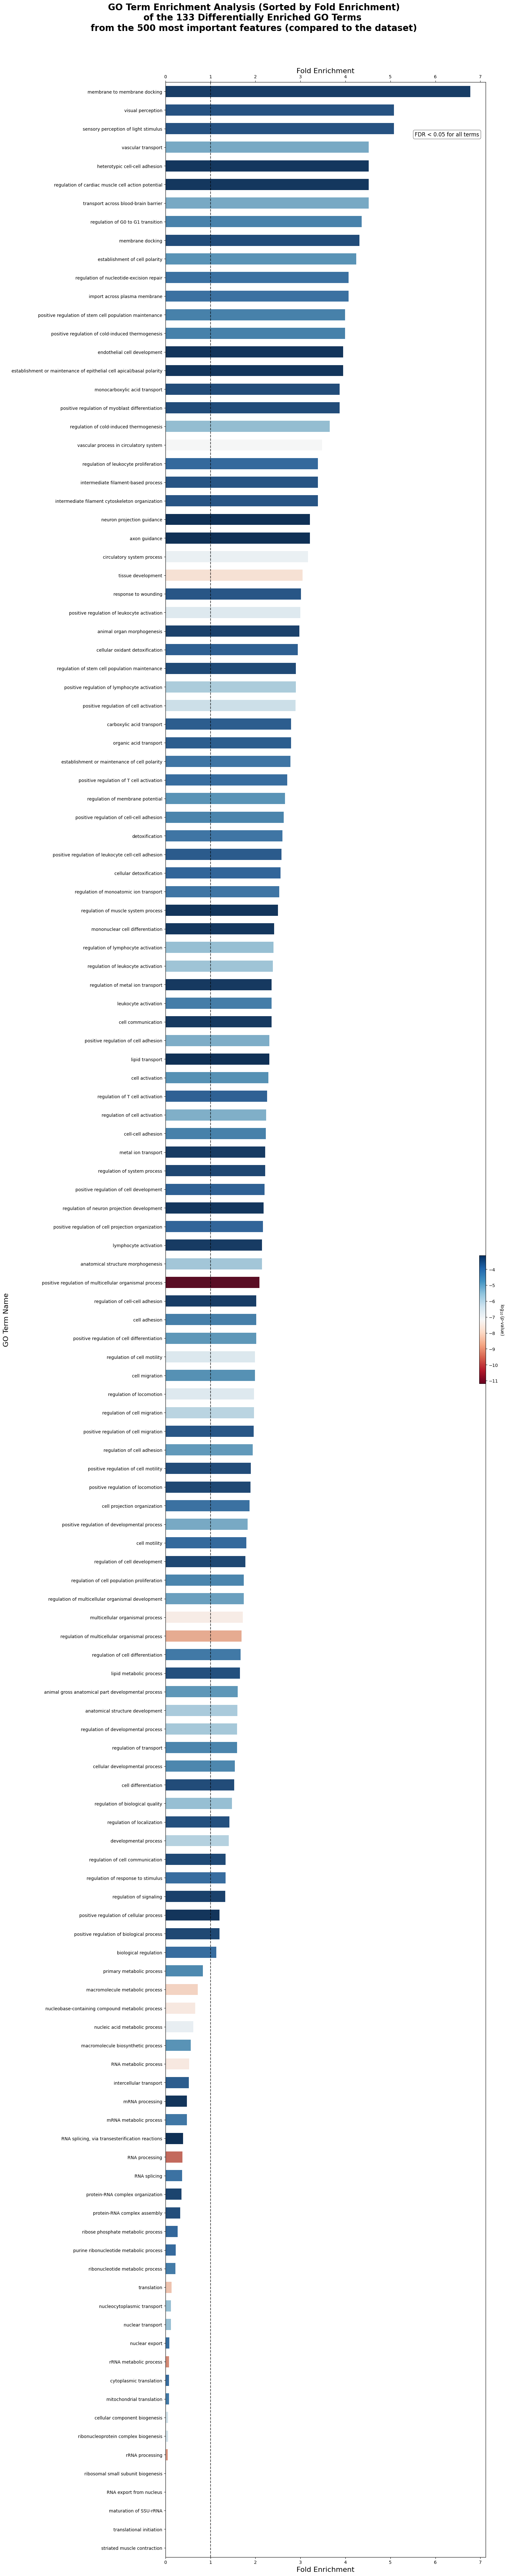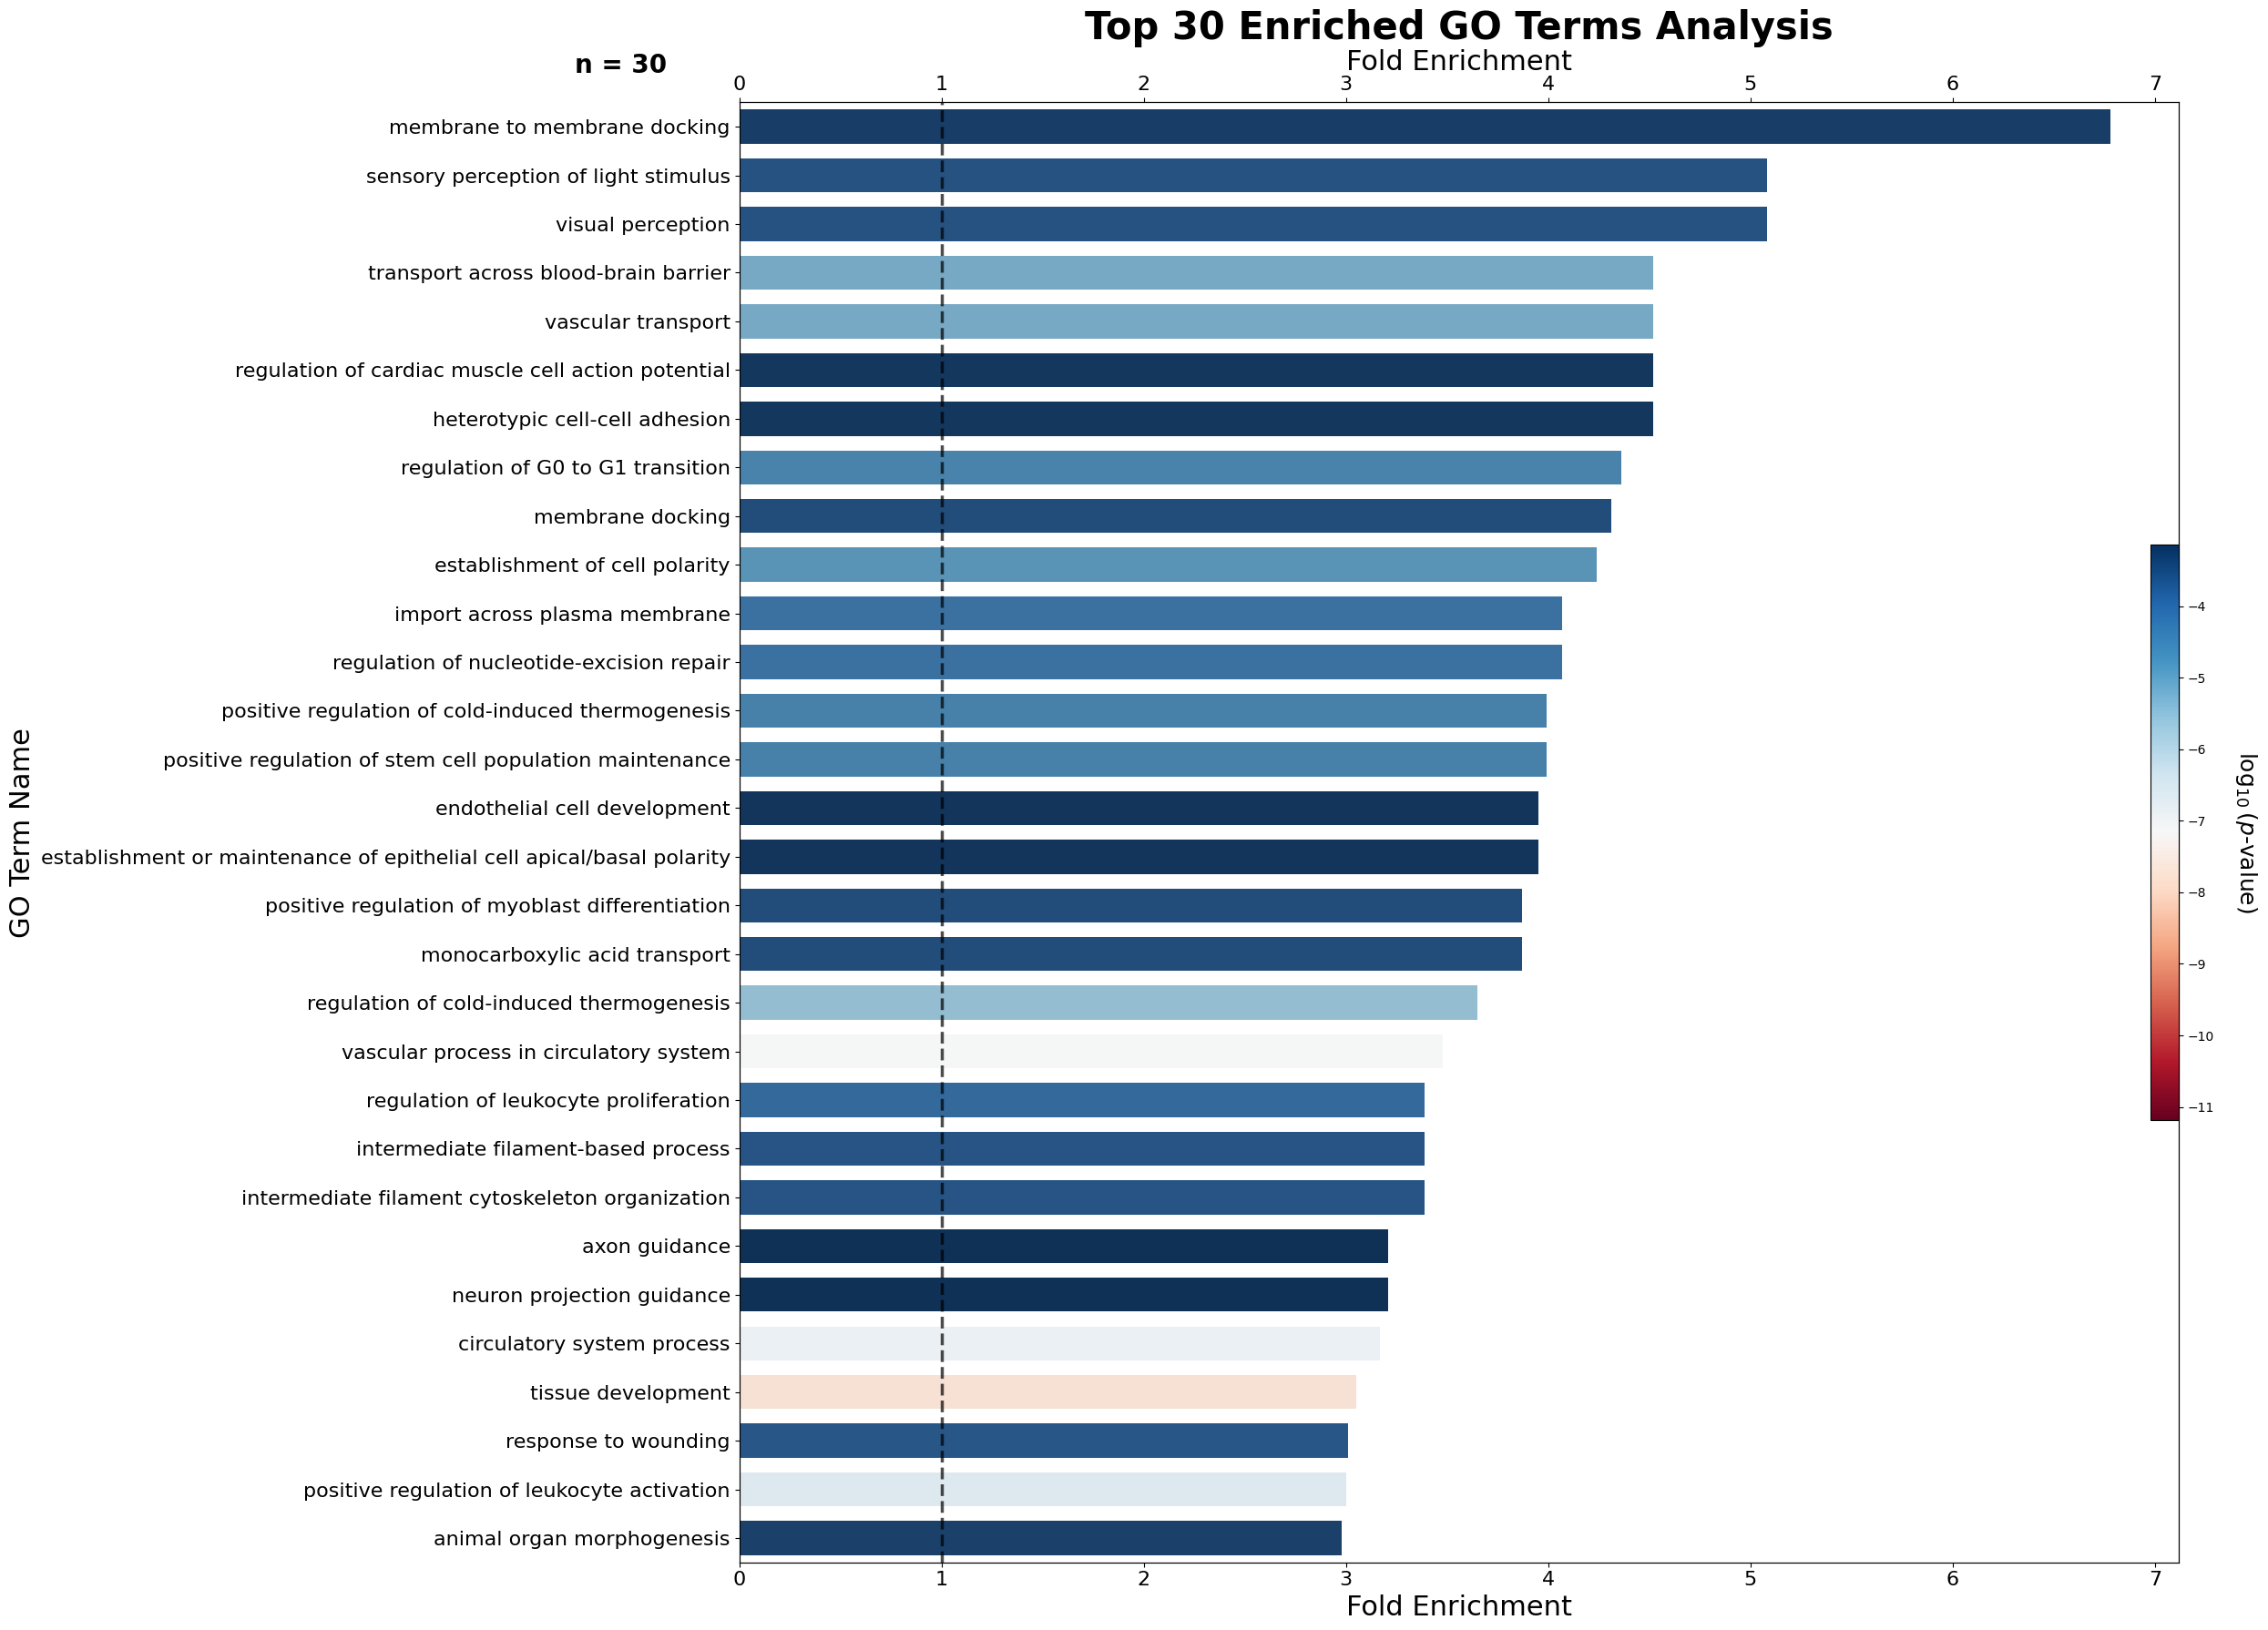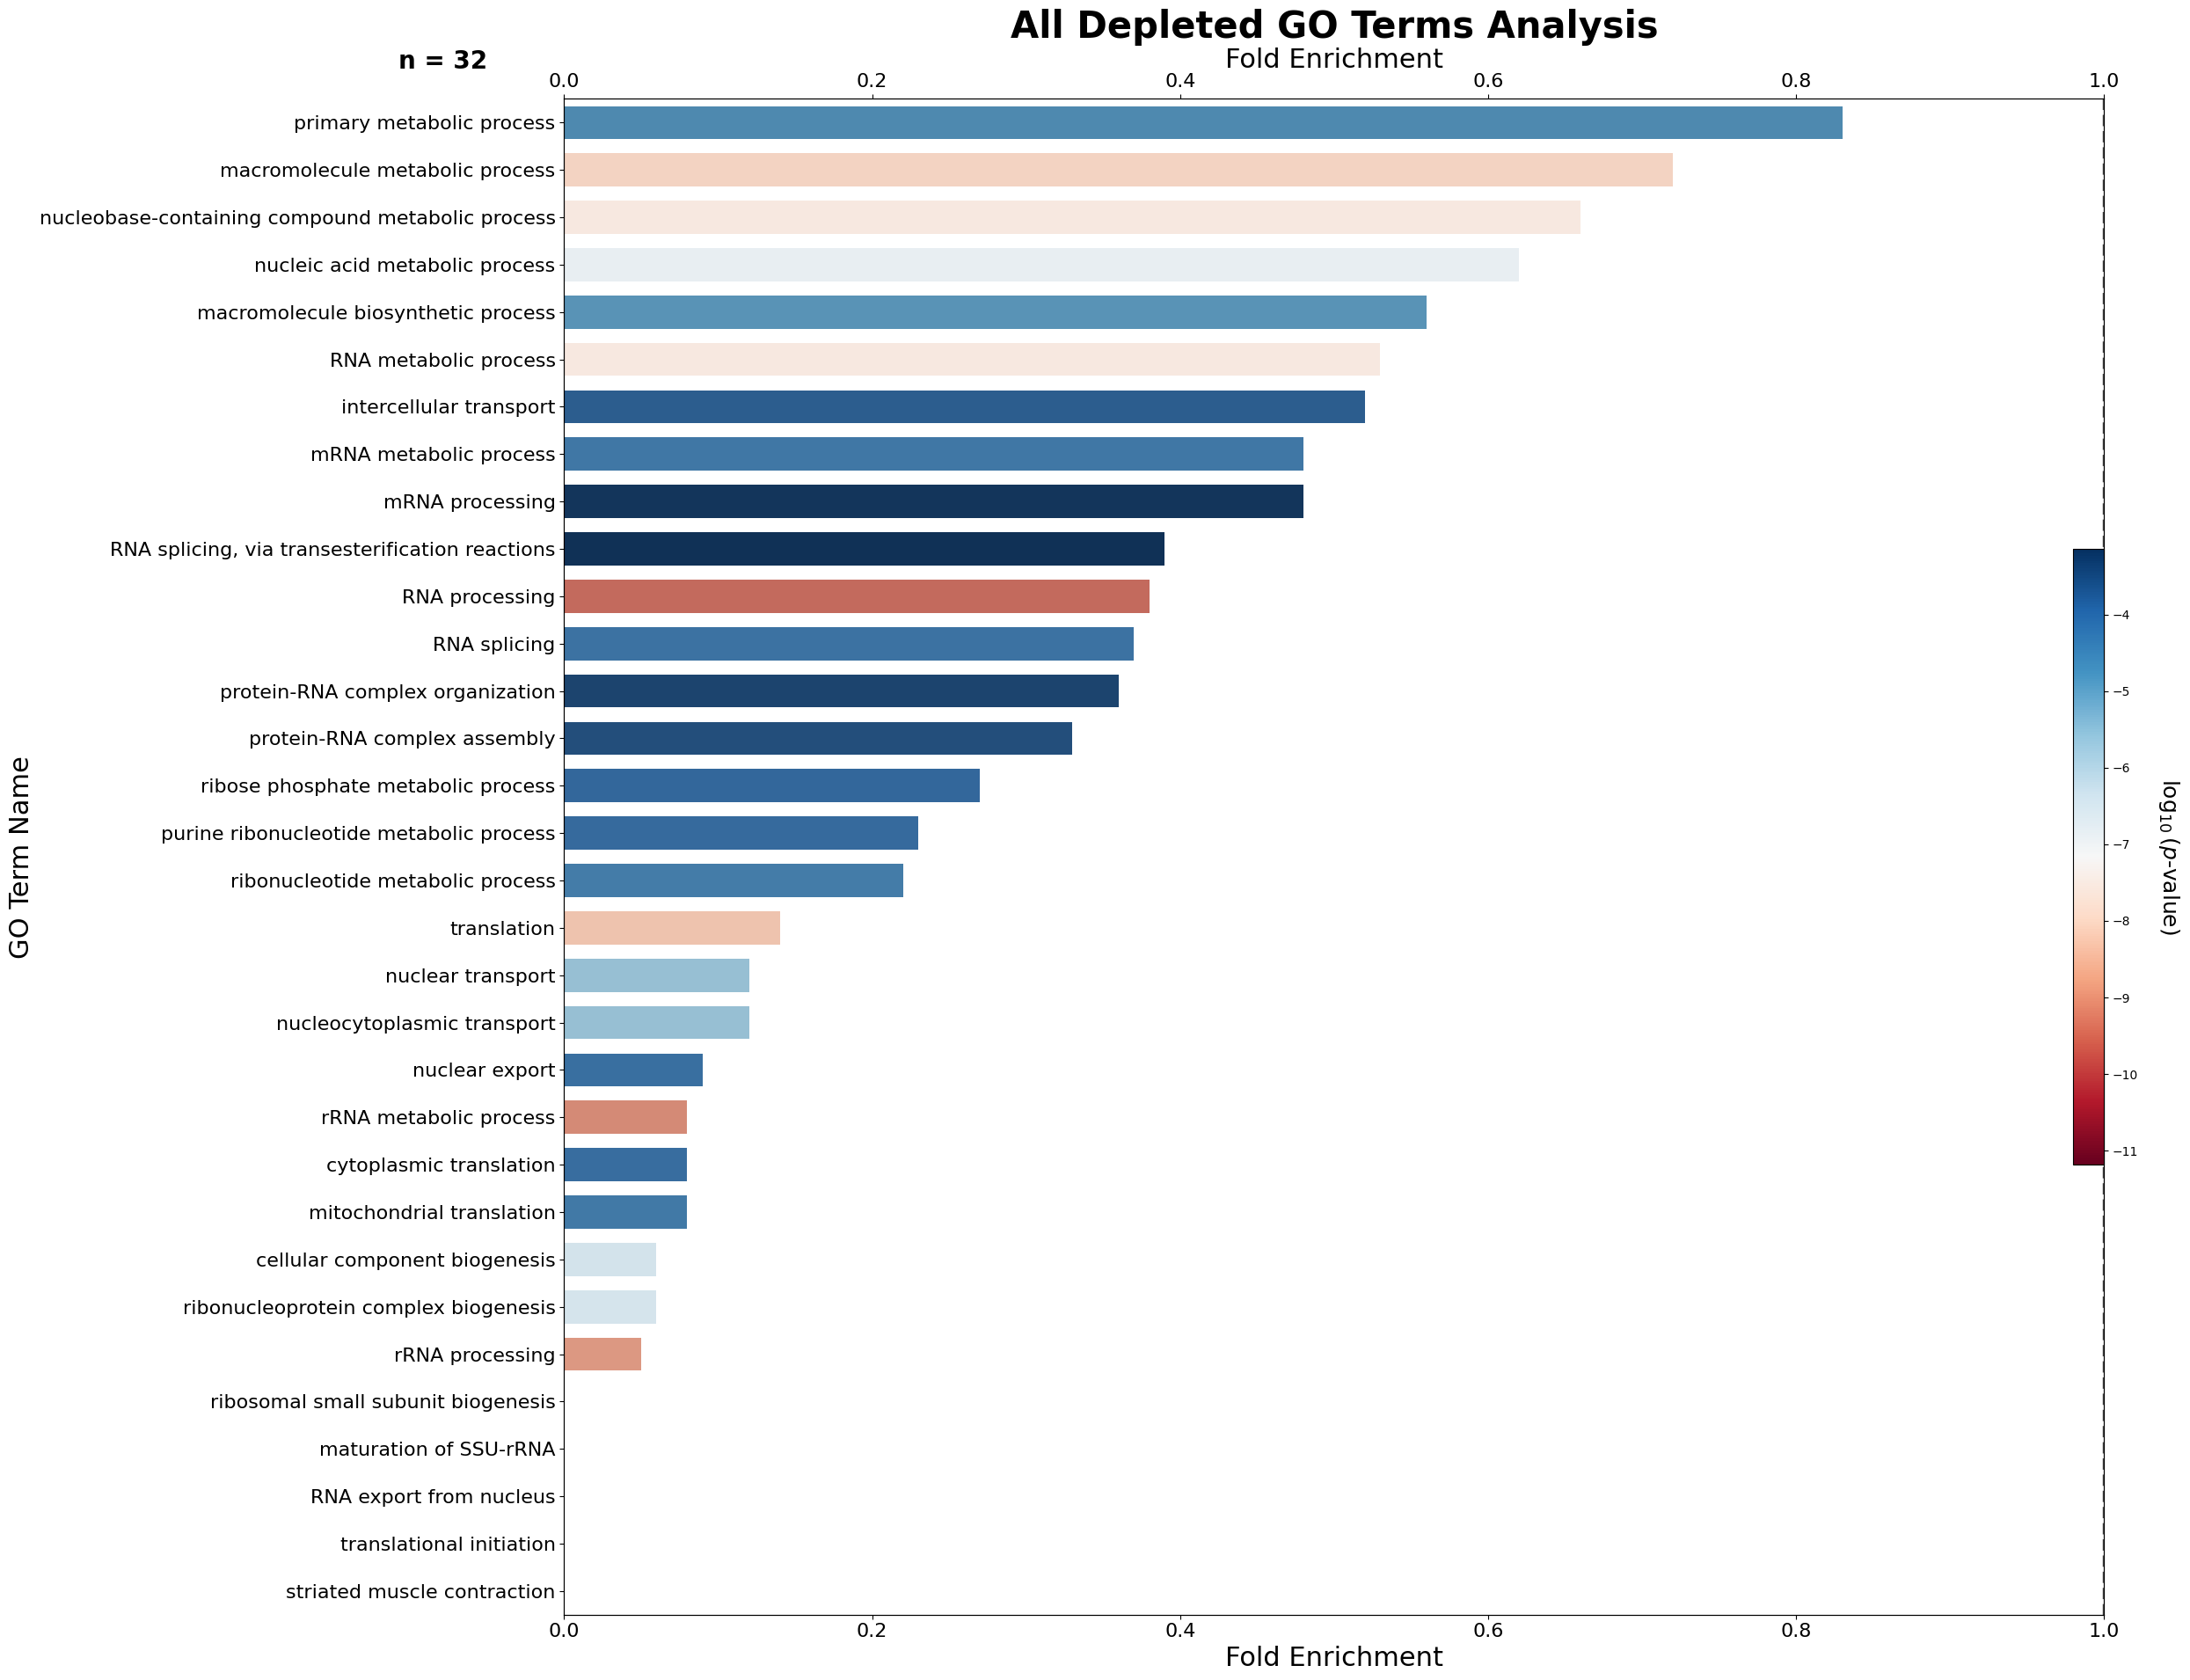